# Case Study - MEL (DDA-TMT single cell melanoma experiment)

This is case study using the experimental data from [Leduc et al. (2024)](https://www.nature.com/articles/s41596-024-01033-8).

The dataset is available at: https://scp.slavovlab.net/Leduc_et_al_2022.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.collections import LineCollection
from scipy.stats import gaussian_kde

import json
import scipy
import scipy.cluster.hierarchy as sch
import sys
import os
# current_dir = os.getcwd()
# sys.path.append(os.path.join(os.path.dirname(current_dir), 'code'))
import pickle

import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from protmapper import uniprot_client
from indra.databases import hgnc_client

from MSquantSim.simulate import simulate_using_copula, simulate_using_tvae, \
    simulate_using_per_protein
from MSquantSim.downstreamanalysis import train_rf, get_pca_explained_variance
from MSquantSim.similarity_scores import plot_corr, similarity_across_simulations
from MSquantSim.utility import mask_simulations_with_lod, fit_mnar, apply_dropout

# from causomic.graph_construction.utils import get_neighbor_network
# from causomic.graph_construction.indra_queries import get_ids, format_query_results
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split

from tqdm import tqdm

import warnings
warnings.filterwarnings('ignore')

import os
# The CoGEx client is only needed to re-run the INDRA network query (commented out
# below); the analysis loads the saved network from ../data/mel/INDRA_network_MEL.pkl.
try:
    from indra_cogex.client import Neo4jClient
    client = Neo4jClient(url=os.getenv("API_URL"), 
                            auth=(os.getenv("USER"), 
                                os.getenv("PASSWORD"))
                        )
except ImportError:
    client = None

def hgnc_converter(id, mnemonic_id=False):
    if mnemonic_id:
        uniprot_id = uniprot_client.get_id_from_mnemonic(id)
    else:
        uniprot_id = id
    hgnc_id = uniprot_client.get_hgnc_id(uniprot_id)
    hgnc_name = hgnc_client.get_hgnc_name(hgnc_id)
    return hgnc_name

The raw spectra were identified and quantified using MaxQuant. The resulting PSMs were than processed using the methods in MSstatsTMT, including normalization across TMT mixtures using a reference channel and summarization of peptide ions into a single value per protein per channel.

## Process MSstatsTMT Protein-level data

In [2]:
mel_input_raw = pd.read_csv('../data/mel/MEL_protein_level_data.csv')
mel_input_raw = mel_input_raw.loc[:, ~mel_input_raw.columns.str.contains(';', na=False)]
mel_input_raw.columns = [col.split('|')[1] if '|' in col else col for col in mel_input_raw.columns]
mel_input_raw = mel_input_raw.drop(columns=["Run", "Channel"])

mel_input_raw.columns = [hgnc_converter(i, mnemonic_id=False) if i != "Condition" \
    else "Condition" for i in mel_input_raw.columns]
mel_input_raw.head()

,Condition,ARHGAP10,EFCAB5,FAM186A,ZBTB42,NACA,CROCC2,ACOT7,MYO1C,SNAP23,...,TC2N,MED17,ARGLU1,BTG4,NAGK,SHROOM4,UTP18,ABHD8,BABAM1,HDAC11
0,u,10.449841,11.267802,10.620656,12.056047,10.616000,8.971095,7.622955,9.967160,10.002026,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,u,9.988900,9.341027,10.188457,11.560510,10.587988,9.142974,7.911131,9.644867,9.406374,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,m,9.731853,8.977844,10.933736,13.109581,10.729755,10.703360,8.243595,10.009776,9.323197,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,m,10.151383,9.964322,10.468290,13.302292,10.721968,NaN,8.699114,9.753093,10.364373,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,m,10.675715,10.823538,11.139793,12.791292,10.218707,7.363879,7.709675,9.950416,10.489982,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Filter data using missing values and INDRA network

In [3]:
# Count missing values per column
missing_counts = mel_input_raw.isna().sum()
missing_percentages = (missing_counts / len(mel_input_raw))

print(f"Columns with missing values: {(missing_counts > 0).sum()}")
print(f"Total missing values: {missing_counts.sum()}")

# Remove columns with more than 50% missing values
threshold = 0.5
cols_to_keep = missing_percentages[missing_percentages <= threshold].index
mel_input_raw = mel_input_raw[cols_to_keep]

print(f"\nColumns after filtering: {len(mel_input_raw.columns)}")
print(f"Columns removed: {len(missing_percentages) - len(cols_to_keep)}")

Columns with missing values: 3139
Total missing values: 1218425

Columns after filtering: 1148
Columns removed: 1992


In [4]:
# test_network = format_query_results(get_neighbor_network(
#     nodes=get_ids(mel_input.columns, type="gene"),
#     client=client,
#     relation=["IncreaseAmount", "DecreaseAmount"],
#     upstream=True,
#     downstream=True,
#     minimum_evidence_count=5,
#     filter_all_nodes=True))
with open('../data/mel/INDRA_network_MEL.pkl', 'rb') as f:
    test_network = pickle.load(f)

filtered = test_network.loc[:, ["source", "target"]].drop_duplicates()

G = nx.DiGraph()
for i in range(len(filtered)):
    G.add_edge(filtered.iloc[i]["source"], filtered.iloc[i]["target"])

components = list(nx.weakly_connected_components(G))
max_component = max(components, key=len)
print(f"Largest connected component size: {len(max_component)} nodes")

cols = [c for c in mel_input_raw.columns if (c == 'Condition' or c in max_component)]
mel_input_raw = mel_input_raw.loc[:, cols]

Largest connected component size: 124 nodes


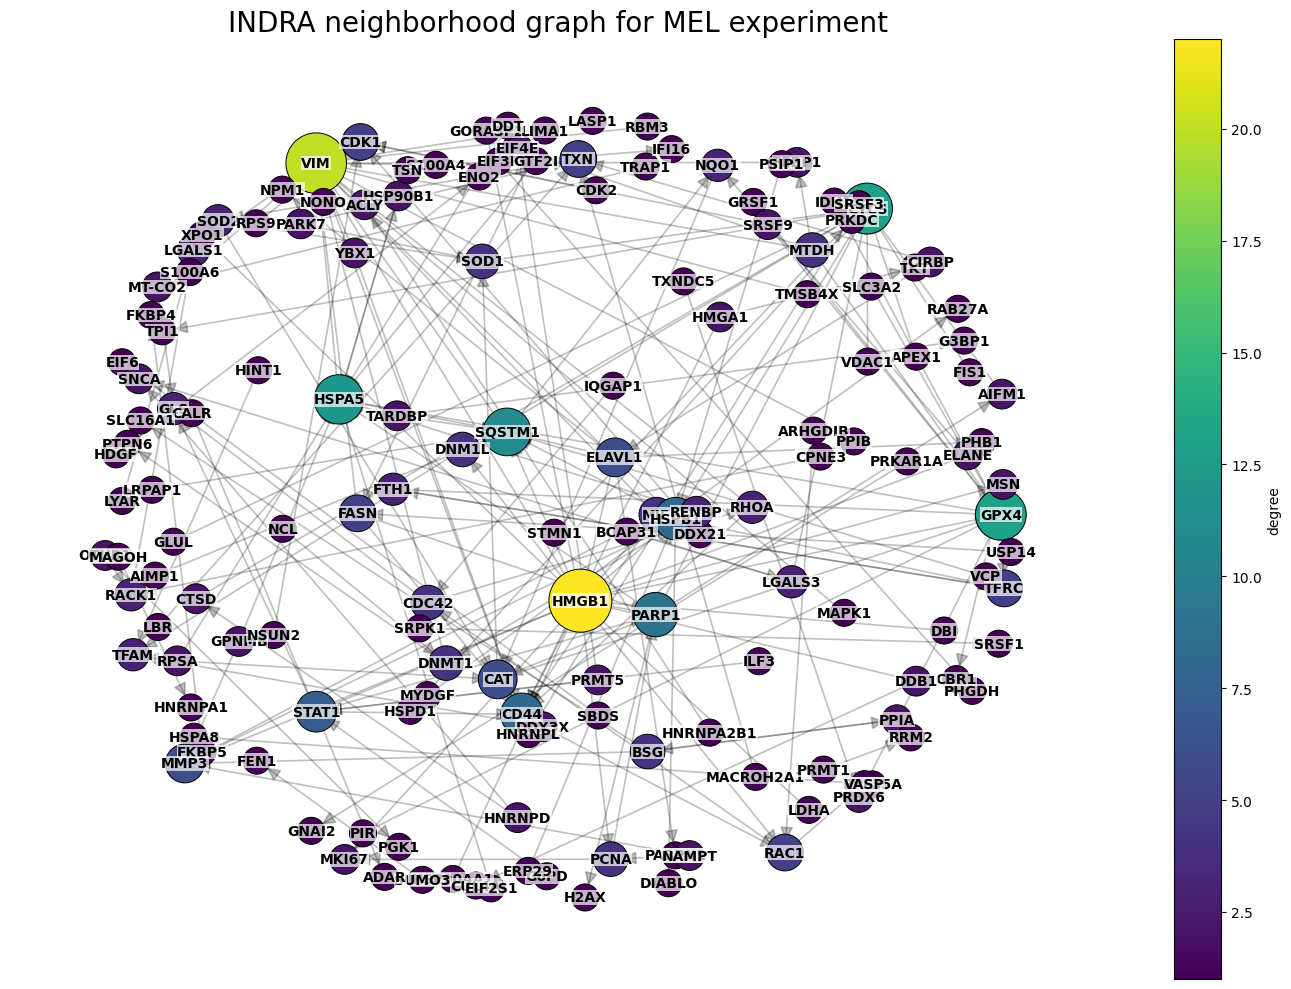

In [5]:
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42, k=.8)  # slightly more spacing
deg = dict(G.degree())
# Bigger nodes overall
node_sizes = [300 + deg[n] * 80 for n in G.nodes()]
node_colors = [deg[n] for n in G.nodes()]
nx.draw_networkx_edges(
    G,
    pos,
    alpha=0.25,
    arrowsize=20,
    width=1.2
)
nodes = nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap="viridis",
    edgecolors="black",
    linewidths=0.7
)
nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight="bold",
    bbox=dict(
        facecolor="white",
        edgecolor="none",
        alpha=0.7,
        pad=0.2
    )
)
plt.colorbar(nodes, label="degree")
plt.title("INDRA neighborhood graph for MEL experiment", fontsize=20)
plt.axis("off")
plt.tight_layout()
plt.show()

### Find missingness pattens

In [5]:
# skip non-numeric columns
numeric = mel_input_raw.select_dtypes(include=[np.number])
lod = numeric.quantile(.02, axis=0)

In [6]:
# Fit the MNAR detection curve on the real, pre-imputation data.
# n_outer above the default of 8: MEL needs 18 iterations to reach the 1e-4 tolerance,
# and fit_mnar stops early once it converges.
mnar_fits, mnar_params = fit_mnar(mel_input_raw, n_outer=60)

iter 0: a=-2.6417  b=0.4531  delta=7.59e+00


iter 1: a=-2.0298  b=0.3902  delta=6.12e-01


iter 2: a=-1.4839  b=0.3339  delta=5.46e-01


iter 3: a=-1.0949  b=0.2942  delta=3.89e-01


iter 4: a=-0.8511  b=0.2694  delta=2.44e-01


...

iter 13: a=-0.5359  b=0.2375  delta=1.05e-03


iter 14: a=-0.5354  b=0.2374  delta=5.62e-04


iter 15: a=-0.5351  b=0.2374  delta=2.98e-04


iter 16: a=-0.5349  b=0.2374  delta=1.60e-04


iter 17: a=-0.5348  b=0.2374  delta=8.69e-05


### Split data for simulation

### Split train/validation

In [5]:
mel_input = mel_input_raw
X = mel_input.drop(columns=['Condition'])
y = mel_input['Condition']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20, stratify=y
)

mel_input = pd.concat([y_train, X_train], axis=1)
validation_mel_input = pd.concat([y_test, X_test], axis=1)

print(f"Train: {mel_input.shape}, Test: {validation_mel_input.shape}")
print("Train class distribution:\n", mel_input['Condition'].value_counts())
print("Test class distribution:\n", validation_mel_input['Condition'].value_counts())

Train: (502, 125), Test: (126, 125)
Train class distribution:
 Condition
u    252
m    250
Name: count, dtype: int64
Test class distribution:
 Condition
m    63
u    63
Name: count, dtype: int64


### Impute missing values

In [6]:
# Keep original column order
orig_cols = mel_input.columns.tolist()

# Split numeric and non-numeric columns
numeric_cols = [c for c in orig_cols if pd.api.types.is_numeric_dtype(mel_input[c])]
non_numeric_cols = [c for c in orig_cols if c not in numeric_cols]

# Report missing values before imputation
print("Missing values before imputation (numeric cols):")
print(mel_input[numeric_cols].isna().sum().sum())

# KNN imputation
imputer = KNNImputer(n_neighbors=5, weights="uniform")
imputed_array = imputer.fit_transform(mel_input[numeric_cols])

# Build imputed DataFrame and restore original column order
imputed_numeric = pd.DataFrame(imputed_array, columns=numeric_cols, index=mel_input.index)
mel_input = pd.concat([mel_input[non_numeric_cols], imputed_numeric], axis=1)[orig_cols]

# Report missing values after imputation
print("\nMissing values after imputation (numeric cols):")
print(mel_input[numeric_cols].isna().sum().sum())

Missing values before imputation (numeric cols):
8123



Missing values after imputation (numeric cols):
0


### Split healthy/disease for sim

In [7]:
# Split into health and disease
mel_healthy = mel_input[mel_input['Condition'] == "u"].drop(columns=['Condition'])
mel_disease = mel_input[mel_input['Condition'] == "m"].drop(columns=['Condition'])

## Copula

### Single simulation

In [104]:
copula_sim_mel_healthy_single = simulate_using_copula(
    mel_healthy, num_simulations=1, 
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_mel_disease_single = simulate_using_copula(
    mel_disease, num_simulations=1, 
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2)

INFO: [2026-08-24 11:41:50] copulas.multivariate.gaussian - Fitting GaussianMultivariate()
INFO: [2026-08-24 11:42:14] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


### Multiple simulations

#### Run sims

In [18]:
n_sims = 100

copula_sim_mel_healthy_multi = simulate_using_copula(
    mel_healthy, num_simulations=n_sims, 
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_mel_disease_multi = simulate_using_copula(
    mel_disease, num_simulations=n_sims, 
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

Running copula simulations: 100%|██████████| 100/100 [00:51<00:00,  1.93it/s]


#### Mask data

In [ ]:
rng = np.random.default_rng(2)

copula_sim_mel_healthy_multi_masked = [apply_dropout(df, mnar_params[0], mnar_params[1], rng=rng)
                                       for df in copula_sim_mel_healthy_multi]
copula_sim_mel_disease_multi_masked = [apply_dropout(df, mnar_params[0], mnar_params[1], rng=rng)
                                       for df in copula_sim_mel_disease_multi]

#### Save simulations

In [30]:
with open("../../data/MEL_data/results/COPULA_MEL_healthy.pkl", "wb") as f:
    pickle.dump(copula_sim_mel_healthy_multi, f)
with open("../../data/MEL_data/results/COPULA_MEL_disease.pkl", "wb") as f:
    pickle.dump(copula_sim_mel_disease_multi, f)

with open("../../data/MEL_data/results/COPULA_MEL_healthy_masked.pkl", "wb") as f:
    pickle.dump(copula_sim_mel_healthy_multi_masked, f)
with open("../../data/MEL_data/results/COPULA_MEL_disease_masked.pkl", "wb") as f:
    pickle.dump(copula_sim_mel_disease_multi_masked, f)

## TVAE

### Single simulation

In [ ]:
tvae_sim_mel_healthy_single = simulate_using_tvae(
    mel_healthy, None, num_simulations=1,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_mel_disease_single = simulate_using_tvae(
    mel_disease, None, num_simulations=1,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

#### Runs sims

In [11]:
n_sims = 100

tvae_sim_mel_healthy_multi = simulate_using_tvae(
    mel_healthy, None, num_simulations=n_sims,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_mel_disease_multi = simulate_using_tvae(
    mel_disease, None, num_simulations=n_sims,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2026-01-08 17:12:48] sdv.metadata.single_table - Detected metadata:
INFO: [2026-01-08 17:12:48] sdv.metadata.single_table - {
    "columns": {
        "DDX3X": {
            "sdtype": "numerical"
        },
        "PIR": {
            "sdtype": "numerical"
        },
        "PRMT5": {
            "sdtype": "numerical"
        },
        "XPO1": {
            "sdtype": "numerical"
        },
        "CPNE3": {
            "sdtype": "numerical"
        },
        "MACROH2A1": {
            "sdtype": "numerical"
        },
        "PSIP1": {
            "sdtype": "numerical"
        },
        "IDH1": {
            "sdtype": "numerical"
        },
        "GLS": {
            "sdtype": "numerical"
        },
        "AIFM1": {
            "sdtype": "numerical"
        },
        "LDHA": {
            "sdtype": "numerical"
        },
        "MT-CO2": {
            "sdtype": "numerical"
        },
        "SOD1": {
            "sdtype": "numerical"
        },
        "PGK1": {
   

#### Mask data

In [ ]:
rng = np.random.default_rng(2)

tvae_sim_mel_healthy_multi_masked = [apply_dropout(df, mnar_params[0], mnar_params[1], rng=rng)
                                       for df in tvae_sim_mel_healthy_multi]
tvae_sim_mel_disease_multi_masked = [apply_dropout(df, mnar_params[0], mnar_params[1], rng=rng)
                                       for df in tvae_sim_mel_disease_multi]

#### Save simulations

In [13]:
with open("../../data/MEL_data/results/TVAE_MEL_healthy.pkl", "wb") as f:
    pickle.dump(tvae_sim_mel_healthy_multi, f)
with open("../../data/MEL_data/results/TVAE_MEL_disease.pkl", "wb") as f:
    pickle.dump(tvae_sim_mel_disease_multi, f)
with open("../../data/MEL_data/results/TVAE_MEL_healthy_masked.pkl", "wb") as f:
    pickle.dump(tvae_sim_mel_healthy_multi_masked, f)
with open("../../data/MEL_data/results/TVAE_MEL_disease_masked.pkl", "wb") as f:
    pickle.dump(tvae_sim_mel_disease_multi_masked, f)

## Per-protein

### Single simulation

In [18]:
pprotein_sim_mel_healthy_single = simulate_using_per_protein(
    mel_healthy, num_simulations=1,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_mel_disease_single = simulate_using_per_protein(
    mel_disease, num_simulations=1,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

### Multiple simulations

In [14]:
n_sims = 100

pprotein_sim_mel_healthy_multi = simulate_using_per_protein(
    mel_healthy, num_simulations=n_sims,
    samples_per_simulation=len(mel_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_mel_disease_multi = simulate_using_per_protein(
    mel_disease, num_simulations=n_sims,
    samples_per_simulation=len(mel_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

Running per-protein simulations: 100%|██████████| 100/100 [00:00<00:00, 5398.77it/s]


In [ ]:
rng = np.random.default_rng(2)

pprotein_sim_mel_healthy_multi_masked = [apply_dropout(df, mnar_params[0], mnar_params[1], rng=rng)
                                       for df in pprotein_sim_mel_healthy_multi]
pprotein_sim_mel_disease_multi_masked = [apply_dropout(df, mnar_params[0], mnar_params[1], rng=rng)
                                       for df in pprotein_sim_mel_disease_multi]

In [16]:
with open("../../data/MEL_data/results/PPROTEIN_MEL_healthy.pkl", "wb") as f:
    pickle.dump(pprotein_sim_mel_healthy_multi, f)
with open("../../data/MEL_data/results/PPROTEIN_MEL_disease.pkl", "wb") as f:
    pickle.dump(pprotein_sim_mel_disease_multi, f)
with open("../../data/MEL_data/results/PPROTEIN_MEL_healthy_masked.pkl", "wb") as f:
    pickle.dump(pprotein_sim_mel_healthy_multi_masked, f)
with open("../../data/MEL_data/results/PPROTEIN_MEL_disease_masked.pkl", "wb") as f:
    pickle.dump(pprotein_sim_mel_disease_multi_masked, f)

## Evaluate simulations


In [8]:
with open("../../data/MEL_data/results/COPULA_MEL_healthy_masked.pkl", "rb") as f:
    copula_sim_mel_healthy_multi_masked = pickle.load(f)
with open("../../data/MEL_data/results/COPULA_MEL_disease_masked.pkl", "rb") as f:
    copula_sim_mel_disease_multi_masked = pickle.load(f)
with open("../../data/MEL_data/results/TVAE_MEL_healthy_masked.pkl", "rb") as f:
    tvae_sim_mel_healthy_multi_masked = pickle.load(f)
with open("../../data/MEL_data/results/TVAE_MEL_disease_masked.pkl", "rb") as f:
    tvae_sim_mel_disease_multi_masked = pickle.load(f)
with open("../../data/MEL_data/results/PPROTEIN_MEL_healthy_masked.pkl", "rb") as f:
    pprotein_sim_mel_healthy_multi_masked = pickle.load(f)
with open("../../data/MEL_data/results/PPROTEIN_MEL_disease_masked.pkl", "rb") as f:
    pprotein_sim_mel_disease_multi_masked = pickle.load(f)

mel_input["Condition"] = mel_input["Condition"].map({"u": 0, "m": 1 }) # For colors

In [12]:
len(mel_input_raw)

628

In [13]:
mel_input_raw.isna().sum().sum() / len(mel_input_raw)

16.713375796178344

In [15]:
copula_sim_mel_healthy_multi_masked[0].isna().sum().sum() / len(copula_sim_mel_healthy_multi_masked[0])

17.642857142857142

### Two protein comparison

In [16]:
def joint_scatter_with_marginal_kdes(
    df,
    x_col,
    y_col,
    hue_col,
    *,
    figsize=(7, 7),
    point_size=28,
    point_alpha=0.70,
    kde_lw=2.2,
    kde_gridsize=256,
    tick_fs=20,
    label_fs=22,
    density_fs=22,
    inner_tick_fs=1,
    remove_legend=True,
    legend_kwargs=None,
    dropna=True,
    colors=None,
):
    """
    Matplotlib-only joint scatter with per-condition marginal KDEs.

    Parameters
    ----------
    df : pandas.DataFrame
    x_col, y_col, hue_col : str
        Column names for x, y, and grouping (condition).
    figsize : tuple
    point_size : float
    point_alpha : float
    kde_lw : float
    kde_gridsize : int
    tick_fs, label_fs, density_fs, inner_tick_fs : int
    remove_legend : bool
    legend_kwargs : dict or None
    dropna : bool
    colors : dict or None
        Optional mapping {condition_value: color_hex}. If None, uses
        Okabe–Ito colorblind-friendly palette.

    Returns
    -------
    fig, (ax_kde_x, ax_scatter, ax_kde_y)
    """
    # Colorblind-friendly palette (Okabe–Ito)
    okabe_ito = [
        "#0072B2", "#D55E00", "#009E73", "#CC79A7",
        "#F0E442", "#56B4E9", "#E69F00", "#000000",
    ]

    use_df = df[[x_col, y_col, hue_col]].copy()
    if dropna:
        use_df = use_df.dropna()

    x = use_df[x_col].to_numpy()
    y = use_df[y_col].to_numpy()
    hue = use_df[hue_col].to_numpy()

    conds = np.unique(hue)
    if colors is None:
        color_map = {c: okabe_ito[i % len(okabe_ito)] for i, c in enumerate(conds)}
    else:
        color_map = dict(colors)

    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(
        nrows=2,
        ncols=2,
        height_ratios=[1.1, 4],
        width_ratios=[4, 1.1],
        hspace=0.15,
        wspace=0.15,
    )

    ax_kde_x = fig.add_subplot(gs[0, 0])
    ax_scatter = fig.add_subplot(gs[1, 0])
    ax_kde_y = fig.add_subplot(gs[1, 1])

    # Scatter
    for c in conds:
        m = hue == c
        ax_scatter.scatter(
            x[m],
            y[m],
            s=point_size,
            alpha=point_alpha,
            edgecolor="none",
            color=color_map[c],
            label=str(c),
        )
    
    ax_scatter.set_xlabel(x_col, fontsize=label_fs)
    ax_scatter.set_ylabel(y_col, fontsize=label_fs)
    ax_scatter.tick_params(axis="both", which="major", labelsize=tick_fs)
    
    # ---- FIXED AXIS LIMITS ----
    ax_scatter.set_xlim(5, 15)
    ax_scatter.set_ylim(5, 15)

    # KDEs
    def _plot_kde(ax, values, grid, color):
        kde = gaussian_kde(values)
        ax.plot(grid, kde(grid), lw=kde_lw, color=color)

    x_grid = np.linspace(np.min(x), np.max(x), kde_gridsize)
    for c in conds:
        v = x[hue == c]
        if v.size > 1:
            _plot_kde(ax_kde_x, v, x_grid, color_map[c])

    ax_kde_x.set_ylabel("Density", fontsize=density_fs)
    ax_kde_x.tick_params(axis="both", which="major", labelsize=inner_tick_fs)
    ax_kde_x.set_xticklabels([])

    y_grid = np.linspace(np.min(y), np.max(y), kde_gridsize)
    for c in conds:
        v = y[hue == c]
        if v.size > 1:
            kde = gaussian_kde(v)
            ax_kde_y.plot(kde(y_grid), y_grid, lw=kde_lw, color=color_map[c])

    ax_kde_y.set_xlabel("Density", fontsize=density_fs)
    ax_kde_y.tick_params(axis="both", which="major", labelsize=inner_tick_fs)
    ax_kde_y.set_yticklabels([])
    
    # Spines
    for ax in (ax_kde_x, ax_scatter, ax_kde_y):
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    # Legend
    if remove_legend:
        leg = ax_scatter.get_legend()
        if leg is not None:
            leg.remove()
    else:
        if legend_kwargs is None:
            legend_kwargs = dict(frameon=False, fontsize=inner_tick_fs, loc="best")
        ax_scatter.legend(**legend_kwargs)

    return fig, (ax_kde_x, ax_scatter, ax_kde_y)

#### Experimental data

In [17]:
protein1 = "NQO1"
protein2 = "LGALS3"

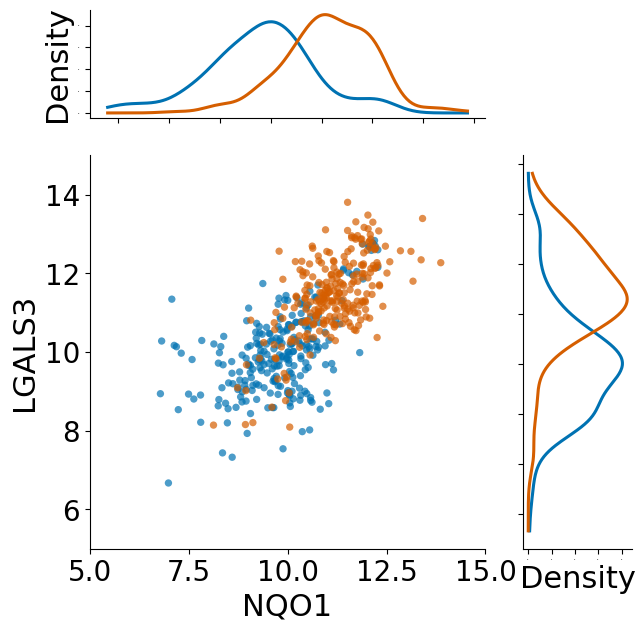

In [18]:
fig, axes = joint_scatter_with_marginal_kdes(
    mel_input, protein1, protein2, "Condition"
)
plt.show()

#### Per-protein

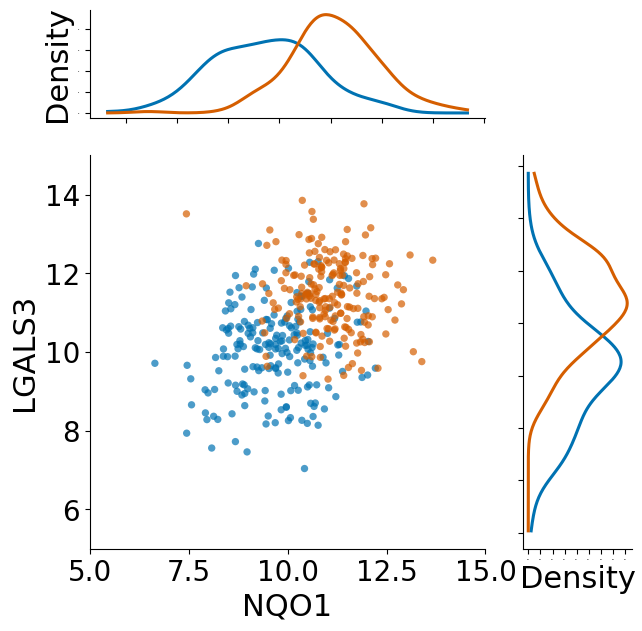

In [19]:
simpp0 = pprotein_sim_mel_healthy_multi_masked[0]
simpp1 = pprotein_sim_mel_disease_multi_masked[0]
merged_df = pd.merge(simpp0, simpp1, how='outer', indicator=True)
merged_df['Condition'] = merged_df['_merge'].map({ 'left_only': 0, 'right_only': 1})
merged_df = merged_df.drop('_merge', axis=1)
fig, axes = joint_scatter_with_marginal_kdes(
    merged_df, protein1, protein2, "Condition"
)
plt.show()

#### VAE

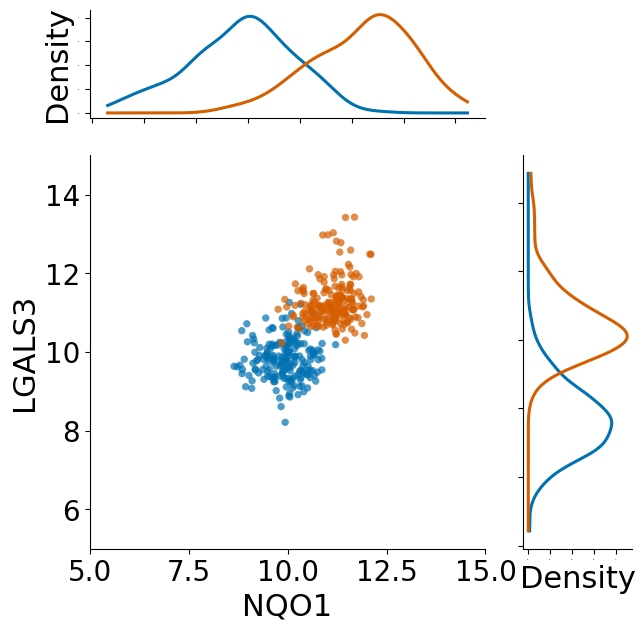

In [20]:
simtvae0 = tvae_sim_mel_healthy_multi_masked[0]
simtvae1 = tvae_sim_mel_disease_multi_masked[0]
merged_df = pd.merge(simtvae0, simtvae1, how='outer', indicator=True)
merged_df['Condition'] = merged_df['_merge'].map({ 'left_only': 0, 'right_only': 1})
merged_df = merged_df.drop('_merge', axis=1)
fig, axes = joint_scatter_with_marginal_kdes(
    merged_df, protein1, protein2, "Condition"
)
plt.show()

#### Copula

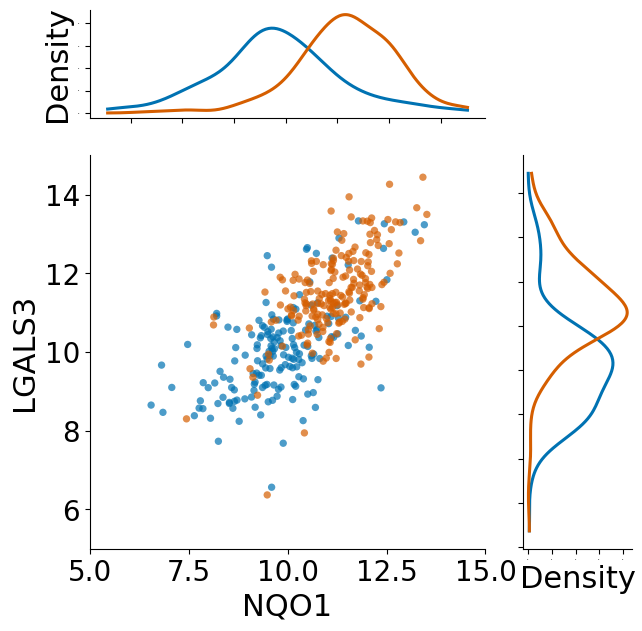

In [21]:
simco0 = copula_sim_mel_healthy_multi_masked[0]
simco1 = copula_sim_mel_disease_multi_masked[0]
merged_df = pd.merge(simco0, simco1, how='outer', indicator=True)
merged_df['Condition'] = merged_df['_merge'].map({ 'left_only': 0, 'right_only': 1})
merged_df = merged_df.drop('_merge', axis=1)
fig, axes = joint_scatter_with_marginal_kdes(
    merged_df, protein1, protein2, "Condition"
)
plt.show()

### Correlation Heatmaps

#### Experimental data

In [78]:
def plot_corr(
    df: pd.DataFrame,
    size: float = 10,
    method: str = "pearson",
    cmap: str = "RdBu_r",
):
    """
    Professional, label-free correlation heatmap (lower triangle),
    optimized for large feature sets and colorblind safety.
    """
    # Keep numeric columns only
    x = df.select_dtypes(include=[np.number])
    if x.shape[1] < 2:
        raise ValueError("Need at least 2 numeric columns.")

    corr = x.corr(method=method)

    # Mask upper triangle + diagonal
    mask = np.triu(np.ones_like(corr, dtype=bool))
    corr_plot = corr.mask(mask)

    fig, ax = plt.subplots(figsize=(size, size), dpi=150)

    im = ax.imshow(
        corr_plot.to_numpy(),
        vmin=-1,
        vmax=1,
        cmap=cmap,
        interpolation="nearest",
    )

    # Remove all ticks and labels
    ax.set_xticks([])
    ax.set_yticks([])

    # Optional subtle grid for structure (can remove if you want ultra-clean)
    n = corr.shape[0]
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", linewidth=0.4, alpha=.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Colorbar
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_ticks([-1, -0.5, 0, 0.5, 1])
    cbar.ax.tick_params(labelsize=10)
    cbar.set_label("Correlation", fontsize=11)

    fig.tight_layout()
    return fig, ax

(<Figure size 750x750 with 2 Axes>, <Axes: >)

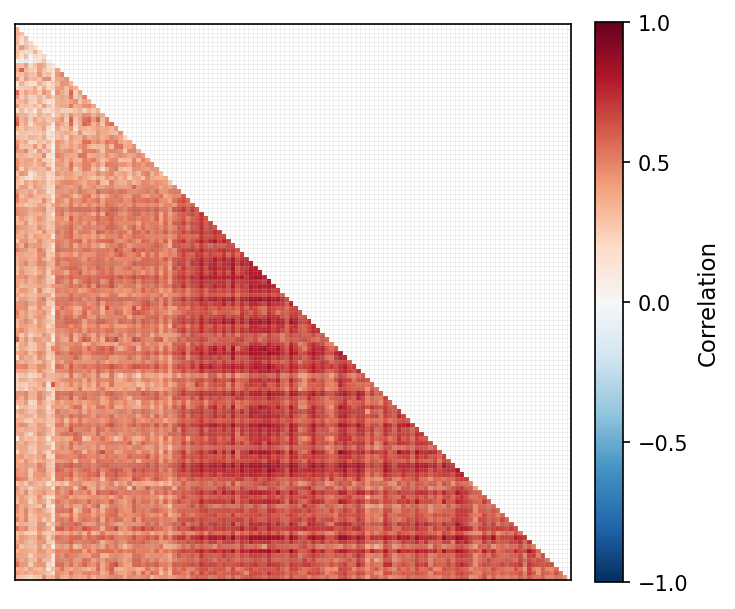

In [80]:
mono_df = mel_input[mel_input['Condition'] == "u"].drop(columns='Condition')
X = mono_df.corr().values
X[np.isnan(X)]= 0
d = sch.distance.pdist(X)   
L = sch.linkage(d, method='complete')
ind = sch.fcluster(L, 0.5*d.max(), 'distance')
columns = [mono_df.columns.tolist()[i] for i in list((np.argsort(ind)))]
columns_healthy = columns
mono_df = mono_df.reindex(columns, axis=1)
plot_corr(mono_df, size =5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

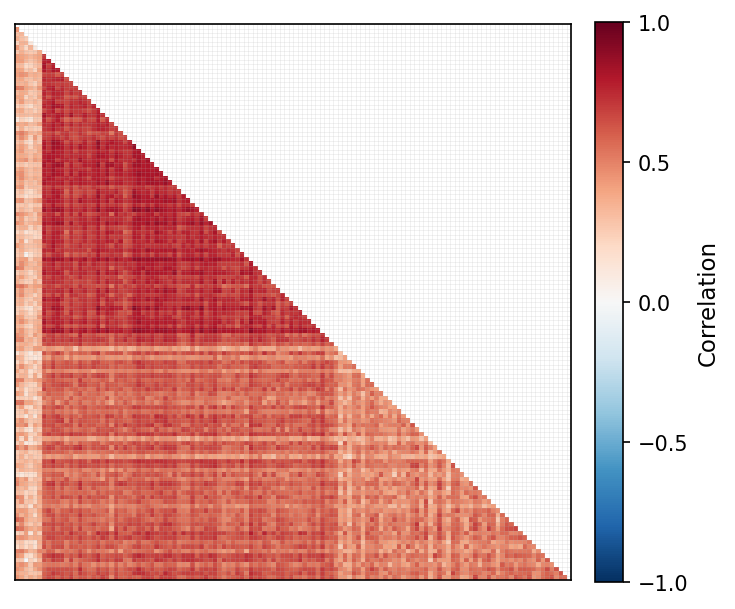

In [81]:
mel_df = mel_input[mel_input['Condition'] == "m"].drop(columns='Condition')
X = mel_df.corr().values
X[np.isnan(X)]= 0
d = sch.distance.pdist(X)   
L = sch.linkage(d, method='complete')
ind = sch.fcluster(L, 0.5*d.max(), 'distance')
columns = [mel_df.columns.tolist()[i] for i in list((np.argsort(ind)))]
columns_disease = columns
mel_df = mel_df.reindex(columns, axis=1)
plot_corr(mel_df, size =5)

#### Per-protein

(<Figure size 750x750 with 2 Axes>, <Axes: >)

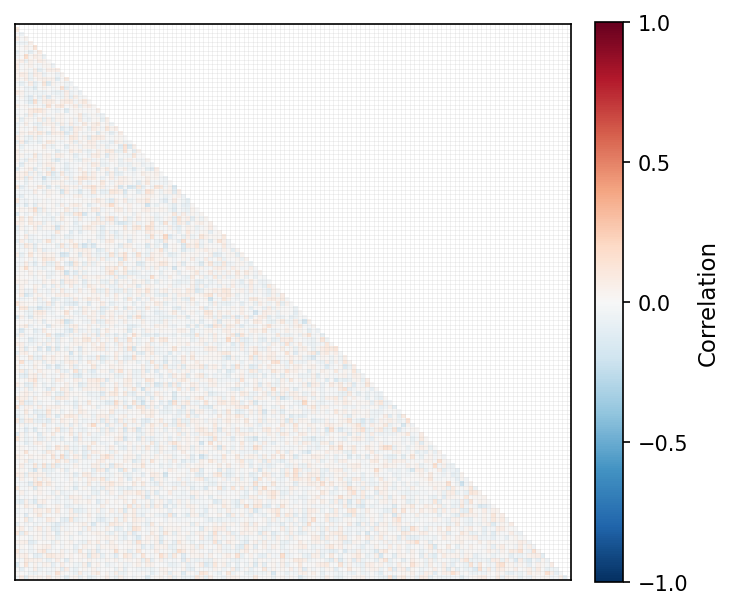

In [17]:
simpp0 = simpp0.reindex(columns_healthy, axis=1)
plot_corr(simpp0, size = 5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

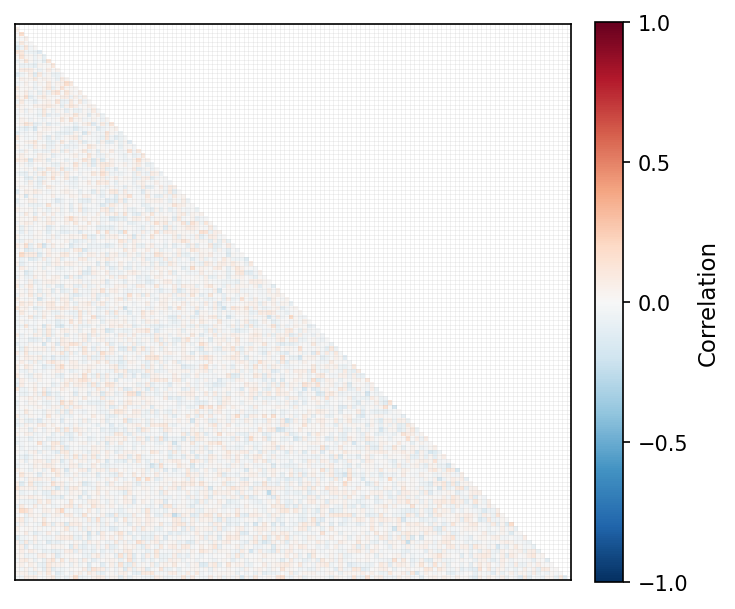

In [18]:
simpp1 = simpp1.reindex(columns_disease, axis=1)
plot_corr(simpp1, size = 5)

#### VAE

(<Figure size 750x750 with 2 Axes>, <Axes: >)

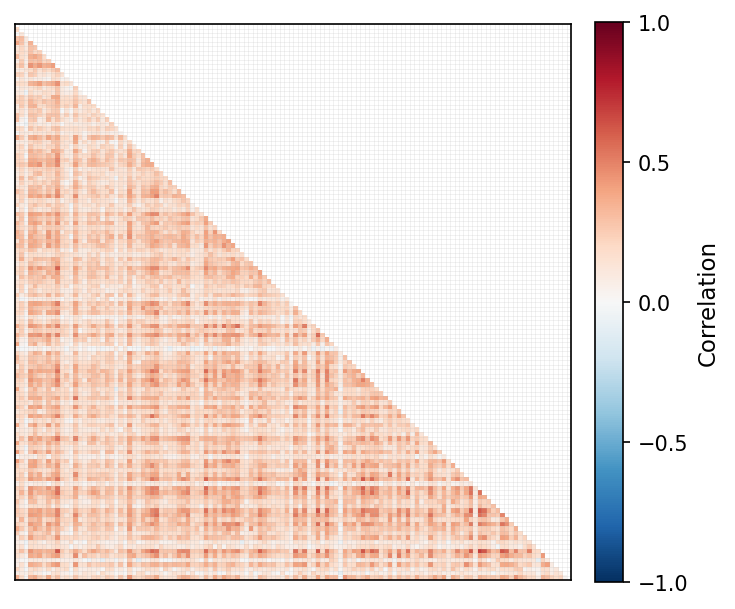

In [19]:
simtvae0 = simtvae0.reindex(columns_healthy, axis=1)
plot_corr(simtvae0, size = 5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

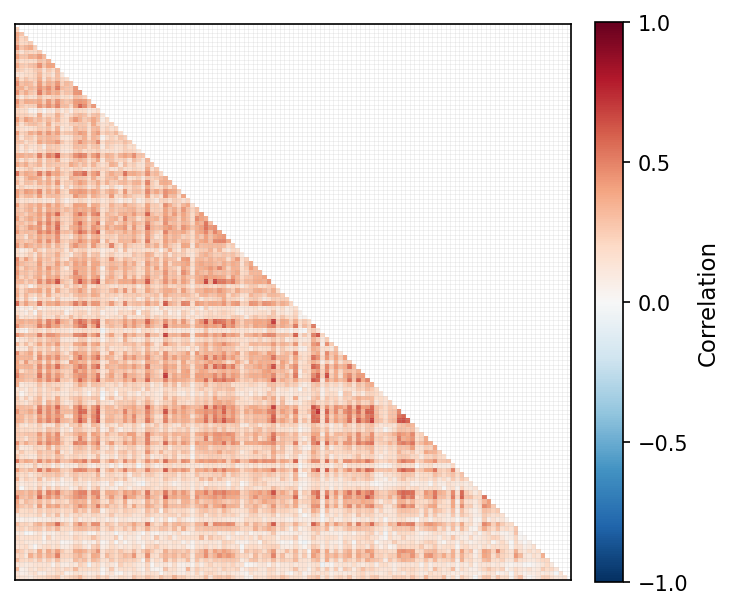

In [20]:
simtvae1 = simtvae1.reindex(columns_disease, axis=1)
plot_corr(simtvae1, size = 5)

#### Copula

(<Figure size 750x750 with 2 Axes>, <Axes: >)

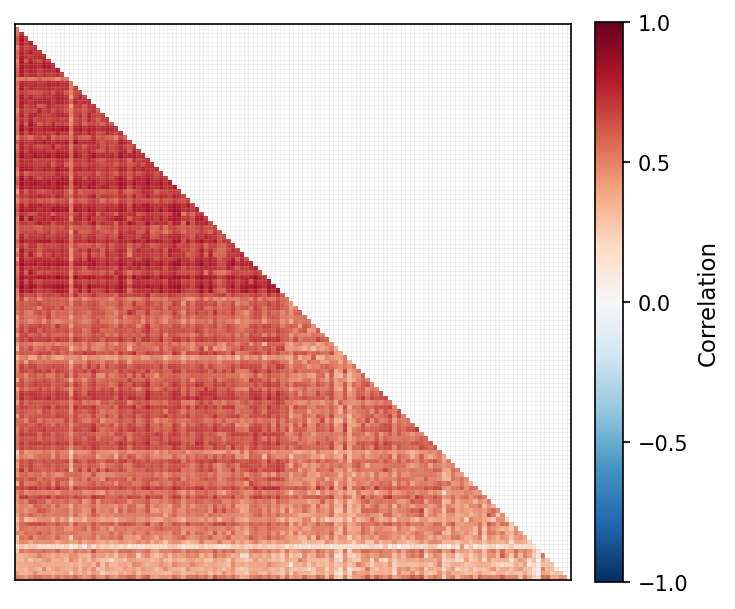

In [21]:
simco0 = simco0.reindex(columns_healthy, axis=1)
plot_corr(simco0, size = 5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

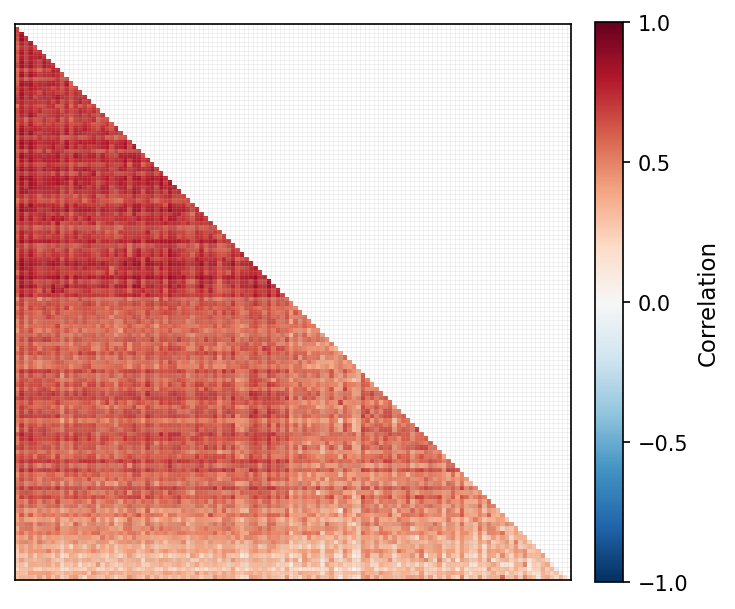

In [22]:
simco1 = simco1.reindex(columns_disease, axis=1)
plot_corr(simco1, size = 5)

#### Save correlation matrices for the paper figure

In [9]:
# Correlation matrices for the combined heatmap figure (simulation_comparison.ipynb).
# Proteins are ordered by clustering each group's experimental training data; the same
# order is used for every simulator in that group.
from MSquantSim.plotting import ordered_correlations

heatmap_data = {
    "healthy": {"Experimental": mel_healthy,
                "Per-protein": pprotein_sim_mel_healthy_multi_masked[0],
                "Copula": copula_sim_mel_healthy_multi_masked[0],
                "TVAE": tvae_sim_mel_healthy_multi_masked[0]},
    "disease": {"Experimental": mel_disease,
                "Per-protein": pprotein_sim_mel_disease_multi_masked[0],
                "Copula": copula_sim_mel_disease_multi_masked[0],
                "TVAE": tvae_sim_mel_disease_multi_masked[0]},
}
corr_matrices = {}
for group, sources in heatmap_data.items():
    order, corrs = ordered_correlations(sources)
    corr_matrices[f"{group}__proteins"] = np.array(order)
    for name, corr in corrs.items():
        corr_matrices[f"{group}__{name}"] = corr
np.savez_compressed("../data/results/MEL/correlation_matrices.npz", **corr_matrices)
print({k: v.shape for k, v in corr_matrices.items()})

{'healthy__proteins': (124,), 'healthy__Experimental': (124, 124), 'healthy__Per-protein': (124, 124), 'healthy__Copula': (124, 124), 'healthy__TVAE': (124, 124), 'disease__proteins': (124,), 'disease__Experimental': (124, 124), 'disease__Per-protein': (124, 124), 'disease__Copula': (124, 124), 'disease__TVAE': (124, 124)}


## Correlation statistics

### Per-protein

In [ ]:
pp_sim_scores = similarity_across_simulations(pprotein_sim_mel_healthy_multi, 
                                              pprotein_sim_mel_disease_multi, 
                                              mel_input, "Condition", "u", "m")

In [18]:
pp_avg_scores = {key: round(np.mean(values),4) for key, values in pp_sim_scores.items()}
print(pp_avg_scores)

{'Basic statistics': 0.9958, 'Correlation column correlations': 0.4758, 'Mean Correlation between fake and real columns': 0.9823, '1 - MAPE Estimator results': 0.901, 'Similarity Score': 0.8387}


In [20]:
pp_avg_scores = {key: round(np.std(values),4) for key, values in pp_sim_scores.items()}
print(pp_avg_scores)

{'Basic statistics': 0.0005, 'Correlation column correlations': 0.0115, 'Mean Correlation between fake and real columns': 0.0002, '1 - MAPE Estimator results': 0.0129, 'Similarity Score': 0.0046}


### TVAE

In [ ]:
tvae_sim_scores = similarity_across_simulations(tvae_sim_mel_healthy_multi, 
                                                tvae_sim_mel_disease_multi, 
                                                mel_input, "Condition", "u", "m")

In [21]:
tvae_avg_scores = {key: round(np.mean(values),4) for key, values in tvae_sim_scores.items()}
print(tvae_avg_scores)

{'Basic statistics': 0.9316, 'Correlation column correlations': 0.7068, 'Mean Correlation between fake and real columns': 0.9801, '1 - MAPE Estimator results': 0.9801, 'Similarity Score': 0.8996}


In [22]:
tvae_avg_scores = {key: round(np.std(values),4) for key, values in tvae_sim_scores.items()}
print(tvae_avg_scores)

{'Basic statistics': 0.002, 'Correlation column correlations': 0.0141, 'Mean Correlation between fake and real columns': 0.0004, '1 - MAPE Estimator results': 0.004, 'Similarity Score': 0.0043}


### Copula

In [ ]:
copula_sim_scores = similarity_across_simulations(copula_sim_mel_healthy_multi, 
                                                  copula_sim_mel_disease_multi, 
                                                  mel_input, "Condition", "u", "m")

In [23]:
copula_avg_scores = {key: round(np.mean(values),4) for key, values in copula_sim_scores.items()}
print(copula_avg_scores)

{'Basic statistics': 0.9947, 'Correlation column correlations': 0.9808, 'Mean Correlation between fake and real columns': 0.9859, '1 - MAPE Estimator results': 0.9677, 'Similarity Score': 0.9823}


In [25]:
copula_avg_scores = {key: round(np.std(values),4) for key, values in copula_sim_scores.items()}
print(copula_avg_scores)

{'Basic statistics': 0.001, 'Correlation column correlations': 0.0059, 'Mean Correlation between fake and real columns': 0.0019, '1 - MAPE Estimator results': 0.0097, 'Similarity Score': 0.003}


##  Random Forest Classifier

In [9]:
n_samples = [5, 10, 25, 50, 75, 100]

### Experimental

In [10]:
experimental_input = {}

for i in n_samples:
    temp_list = list()
    for _ in range(100):
        experimental_healthy_results = mel_healthy.sample(n=i)
        experimental_disease_results = mel_disease.sample(n=i)
        
        experimental_healthy_results.loc[:, "Condition"] = "u"
        experimental_disease_results.loc[:, "Condition"] = "m"
        
        temp_list.append(pd.concat([experimental_healthy_results, 
                                    experimental_disease_results], axis=0))
    
    experimental_input[i] = temp_list


In [ ]:
experimental_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = experimental_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, validation_mel_input))
    experimental_model_accuracy[i] = temp_acc
experimental_model_accuracy = pd.DataFrame(experimental_model_accuracy)

Running simulations: 5: 100%|██████████| 5/5 [00:29<00:00,  5.87s/it]


INFO: [2026-01-14 11:41:27] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-01-14 11:41:27] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


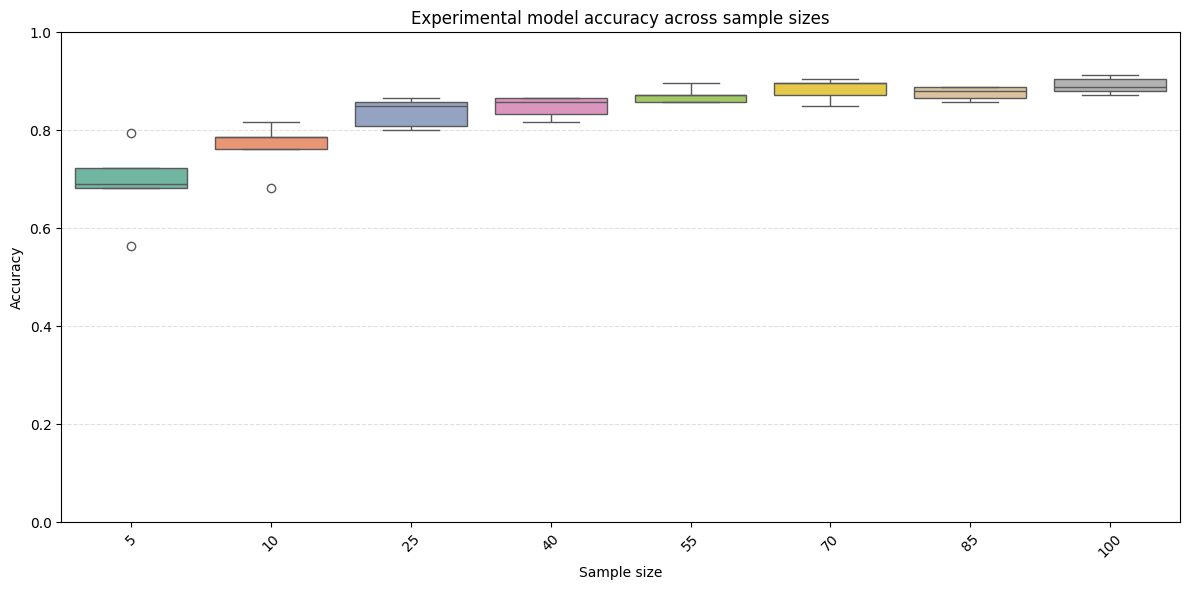

In [20]:
plt.figure(figsize=(12,6))
sns.boxplot(data=experimental_model_accuracy, palette="Set2")
plt.xlabel("Sample size")
plt.ylabel("Accuracy")
plt.title("Experimental model accuracy across sample sizes")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [ ]:
experimental_model_accuracy.to_csv("../data/results/MEL/experimental_model_accuracy.csv")

### Copula

In [11]:
copula_input = {}

for i in n_samples:
    temp_list = list()
    for s in range(100):
        copula_healthy_results = copula_sim_mel_healthy_multi_masked[s].sample(n=i)
        copula_disease_results = copula_sim_mel_disease_multi_masked[s].sample(n=i)
        
        copula_healthy_results.loc[:, "Condition"] = "u"
        copula_disease_results.loc[:, "Condition"] = "m"
        
        temp_list.append(pd.concat([copula_healthy_results, 
                                    copula_disease_results], axis=0))
    
    copula_input[i] = temp_list

In [123]:
copula_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = copula_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, validation_mel_input))
    copula_model_accuracy[i] = temp_acc
copula_model_accuracy = pd.DataFrame(copula_model_accuracy)
copula_model_accuracy.to_csv("../data/results/MEL/copula_model_accuracy.csv")


Running simulations: 5:   0%|          | 0/5 [00:10<?, ?it/s]


KeyboardInterrupt: 

INFO: [2026-01-14 11:48:25] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-01-14 11:48:25] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


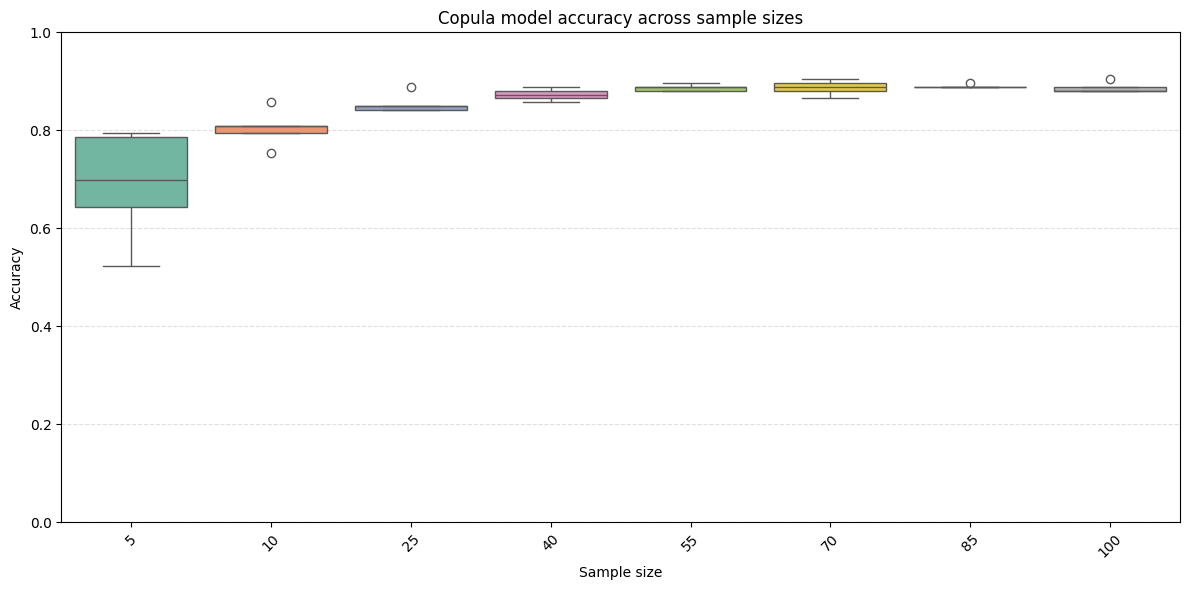

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=copula_model_accuracy, palette="Set2")
plt.xlabel("Sample size")
plt.ylabel("Accuracy")
plt.title("Copula model accuracy across sample sizes")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### TVAE

In [12]:
tvae_input = {}

for i in n_samples:
    temp_list = list()
    for s in range(100):
        tvae_healthy_results = tvae_sim_mel_healthy_multi_masked[s].sample(n=i)
        tvae_disease_results = tvae_sim_mel_disease_multi_masked[s].sample(n=i)
        
        tvae_healthy_results.loc[:, "Condition"] = "u"
        tvae_disease_results.loc[:, "Condition"] = "m"
        
        temp_list.append(pd.concat([tvae_healthy_results, 
                                    tvae_disease_results], axis=0))
    
    tvae_input[i] = temp_list

In [15]:
tvae_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = tvae_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, validation_mel_input))
    tvae_model_accuracy[i] = temp_acc
tvae_model_accuracy = pd.DataFrame(tvae_model_accuracy)
tvae_model_accuracy.to_csv("../data/results/MEL/tvae_model_accuracy.csv")


Running simulations: 100: 100%|██████████| 100/100 [05:48<00:00,  3.48s/it]


INFO: [2026-01-15 08:38:24] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO: [2026-01-15 08:38:24] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


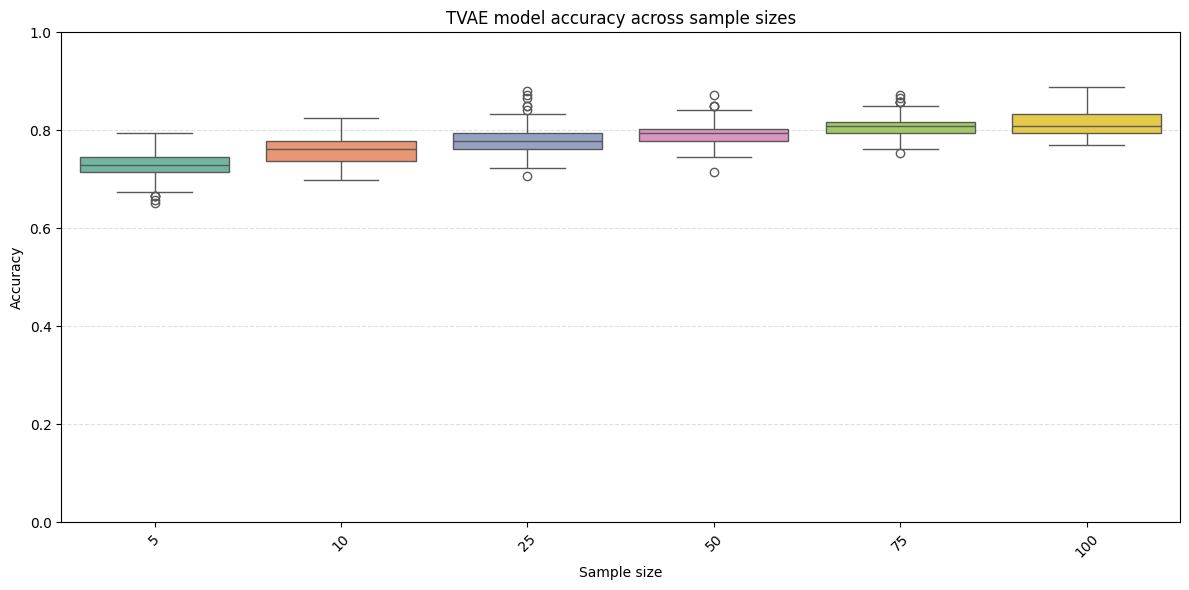

In [16]:
plt.figure(figsize=(12,6))
sns.boxplot(data=tvae_model_accuracy, palette="Set2")
plt.xlabel("Sample size")
plt.ylabel("Accuracy")
plt.title("TVAE model accuracy across sample sizes")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [15]:
tvae_model_accuracy = pd.read_csv("../data/results/MEL/tvae_model_accuracy.csv", index_col=0)

### Per-protein

In [13]:
pprotein_input = {}

for i in n_samples:
    temp_list = list()
    for s in range(100):
        pprotein_healthy_results = pprotein_sim_mel_healthy_multi_masked[s].sample(n=i)
        pprotein_disease_results = pprotein_sim_mel_disease_multi_masked[s].sample(n=i)
        
        pprotein_healthy_results.loc[:, "Condition"] = "u"
        pprotein_disease_results.loc[:, "Condition"] = "m"
        
        temp_list.append(pd.concat([pprotein_healthy_results, 
                                    pprotein_disease_results], axis=0))
    
    pprotein_input[i] = temp_list

In [25]:
pprotein_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = pprotein_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, validation_mel_input))
    pprotein_model_accuracy[i] = temp_acc
pprotein_model_accuracy = pd.DataFrame(pprotein_model_accuracy)
pprotein_model_accuracy.to_csv("../data/results/MEL/pprotein_model_accuracy.csv")


Running simulations: 100: 100%|██████████| 100/100 [10:03<00:00,  6.04s/it]


In [3]:
experimental_model_accuracy = pd.read_csv("../data/results/MEL/experimental_model_accuracy.csv", index_col=0)
copula_model_accuracy = pd.read_csv("../data/results/MEL/copula_model_accuracy.csv", index_col=0)
tvae_model_accuracy = pd.read_csv("../data/results/MEL/tvae_model_accuracy.csv", index_col=0)
pprotein_model_accuracy = pd.read_csv("../data/results/MEL/pprotein_model_accuracy.csv", index_col=0)

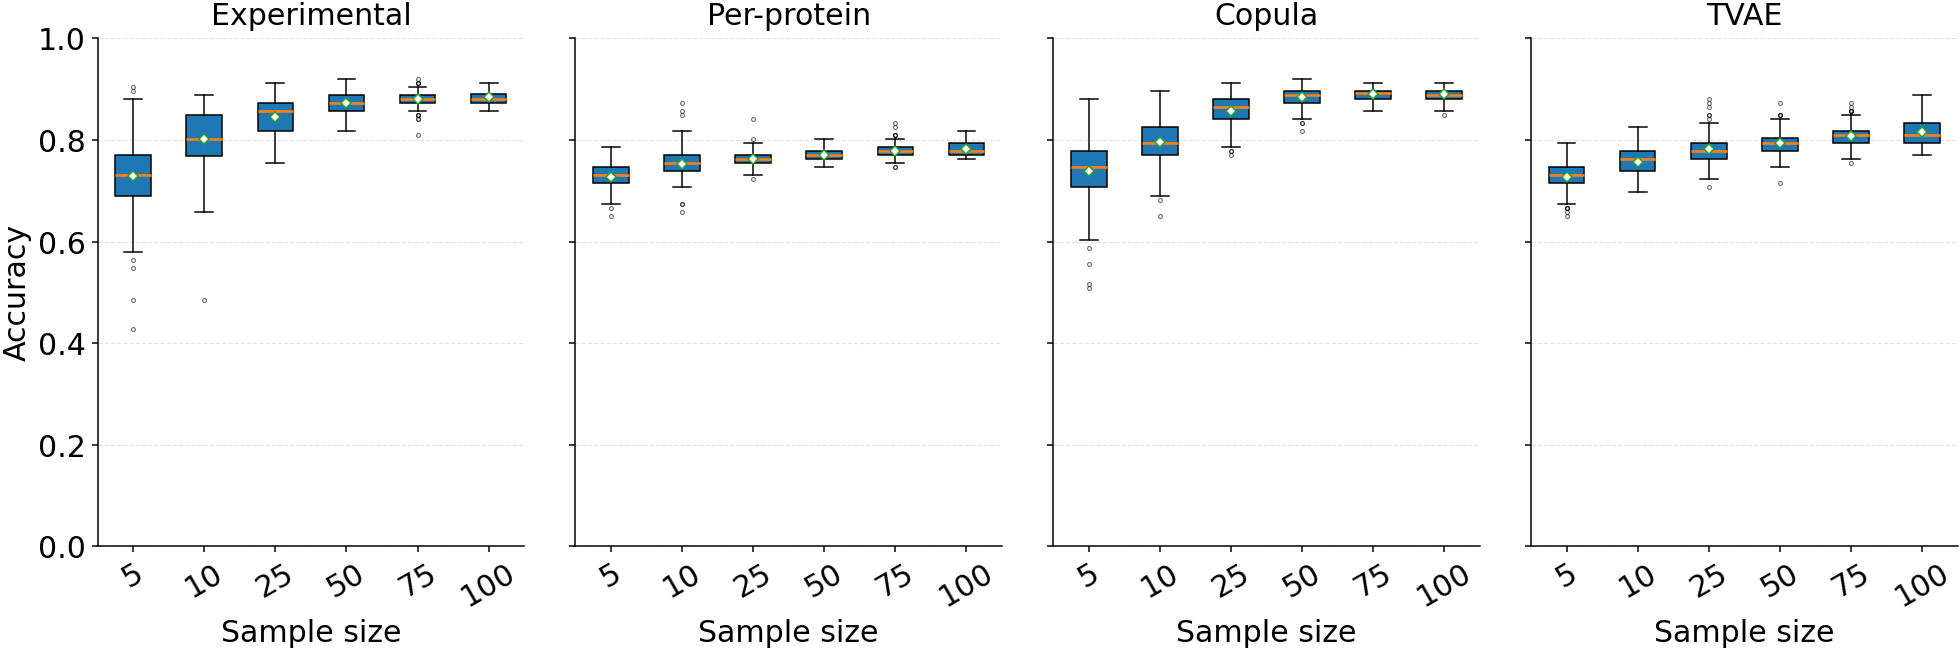

In [7]:
import matplotlib.pyplot as plt

def publication_boxpanel(
    dfs,
    titles,
    *,
    xlabel="Sample size",
    ylabel="Accuracy",
    ylim=(0, 1),
    figsize=(20, 5.5),
    rotation=30,
    show_mean=True,
    savepath=None,   # e.g., "accuracy_panels.pdf" or "accuracy_panels.png"
    dpi=600,
):
    """
    Publication-style multi-panel boxplot figure.

    Parameters
    ----------
    dfs : list of pandas.DataFrame
        Each df should have columns corresponding to sample sizes (or categories).
        Values are accuracies.
    titles : list of str
        Panel titles, same length as dfs.
    savepath : str or None
        If given, figure is saved (PDF/SVG recommended). Otherwise just shown.
    """

    # --- Global typography / rcParams (minimal, journal-friendly) ---
    plt.rcParams.update({
        "font.size": 18,
        "axes.titlesize": 18,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "axes.linewidth": 0.9,
        "xtick.major.width": 0.9,
        "ytick.major.width": 0.9,
        "xtick.major.size": 3.5,
        "ytick.major.size": 3.5,
        "figure.dpi": 120,
        "savefig.dpi": dpi,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    })

    n = len(dfs)
    fig, axes = plt.subplots(
        1, n, figsize=figsize, sharey=True,
        gridspec_kw={"wspace": 0.12}
    )
    if n == 1:
        axes = [axes]

    for i, (df, title, ax) in enumerate(zip(dfs, titles, axes)):
        # Ensure deterministic column order
        cols = list(df.columns)

        ax.boxplot(
            [df[c].dropna().values for c in cols],
            labels=[str(c) for c in cols],
            patch_artist=True,
            showmeans=show_mean,
            meanprops=dict(marker="D", markersize=4, markerfacecolor="white",
                           markeredgewidth=0.9),
            medianprops=dict(linewidth=1.6),
            boxprops=dict(linewidth=0.9),
            whiskerprops=dict(linewidth=0.9),
            capprops=dict(linewidth=0.9),
            flierprops=dict(marker="o", markersize=2.3, markerfacecolor="none",
                            markeredgewidth=0.7, alpha=0.55),
        )

        # Style: white boxes + subtle outlines (prints well)
        for b in ax.artists:
            b.set_facecolor("white")
            b.set_edgecolor("black")

        ax.set_title(title, pad=8)
        ax.set_xlabel(xlabel)
        ax.set_ylim(*ylim)

        # Light y-grid only
        ax.grid(True, axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
        ax.grid(False, axis="x")

        # Rotate tick labels gently (avoid 45 unless needed)
        ax.tick_params(axis="x", rotation=rotation)

        # Clean spines
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Only left panel gets y-label
        if i == 0:
            ax.set_ylabel(ylabel)

    fig.align_ylabels(axes)

    if savepath:
        fig.savefig(savepath)
    plt.show()


# --- Usage (replace with your existing objects) ---
publication_boxpanel(
    dfs=[
        experimental_model_accuracy,
        pprotein_model_accuracy,
        copula_model_accuracy,
        tvae_model_accuracy,
    ],
    titles=[
        "Experimental",
        "Per-protein",
        "Copula",
        "TVAE"
    ],
    savepath=None,  # e.g. "accuracy_panels.pdf"
)

## PCA Variance Explained

In [14]:
n_samples = [5, 10, 25, 50, 75, 100]

### Experimental

In [ ]:
experimental_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = experimental_input[i][s]

        temp_acc.append(get_pca_explained_variance(training_data.drop(columns=["Condition"]), 5)["total_variance"])
    experimental_pca_var[i] = temp_acc
experimental_pca_var = pd.DataFrame(experimental_pca_var)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:  79%|███████▉  | 79/100 [00:00<00:00, 786.58it/s]


Running simulations: 5: 100%|██████████| 100/100 [00:00<00:00, 784.46it/s]


Running simulations: 10:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 10:  92%|█████████▏| 92/100 [00:00<00:00, 918.08it/s]

...


Running simulations: 100:  60%|██████    | 60/100 [00:00<00:00, 103.93it/s]


Running simulations: 100:  71%|███████   | 71/100 [00:00<00:00, 103.26it/s]


Running simulations: 100:  83%|████████▎ | 83/100 [00:00<00:00, 106.84it/s]


Running simulations: 100:  94%|█████████▍| 94/100 [00:00<00:00, 106.91it/s]


Running simulations: 100: 100%|██████████| 100/100 [00:00<00:00, 106.83it/s]

In [29]:
experimental_pca_var

,5,10,25,50,75,100
0,86.827556,79.937850,68.165417,70.098896,68.489761,68.442886
1,90.587224,78.470715,71.865000,72.095776,71.123937,69.795551
2,91.734359,82.672767,65.651392,70.816086,71.055272,66.154527
3,88.661831,75.807091,69.345447,71.091697,71.603947,69.053573
4,92.034099,79.902161,75.422807,70.214434,69.040734,68.504034


### Copula

In [16]:
copula_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        copula_data = copula_input[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(copula_data.drop(columns=["Condition"]), 5)["total_variance"])
        except:
            temp_acc.append(np.nan)
    copula_pca_var[i] = temp_acc
copula_pca_var = pd.DataFrame(copula_pca_var)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:   4%|▍         | 4/100 [00:00<00:02, 39.17it/s]


Running simulations: 5:   9%|▉         | 9/100 [00:00<00:02, 41.12it/s]


Running simulations: 5:  14%|█▍        | 14/100 [00:00<00:02, 33.81it/s]


Running simulations: 5:  20%|██        | 20/100 [00:00<00:02, 39.89it/s]

...


Running simulations: 100:  93%|█████████▎| 93/100 [00:06<00:00, 14.83it/s]


Running simulations: 100:  95%|█████████▌| 95/100 [00:06<00:00, 14.02it/s]


Running simulations: 100:  97%|█████████▋| 97/100 [00:06<00:00, 13.00it/s]


Running simulations: 100:  99%|█████████▉| 99/100 [00:06<00:00, 12.61it/s]


Running simulations: 100: 100%|██████████| 100/100 [00:06<00:00, 14.90it/s]

In [33]:
copula_pca_var

,5,10,25,50,75,100
0,81.291712,69.781459,76.223827,72.068442,68.392592,66.898965
1,78.213753,67.076338,72.766898,68.642767,68.077760,67.587190
2,88.021530,75.778503,63.650877,66.028398,66.793377,64.758182
3,79.905184,73.614699,75.163285,67.381628,66.879819,65.325348
4,88.579937,71.315919,67.497178,67.032275,68.104693,65.460094
...,...,...,...,...,...,...
95,86.072618,75.957541,66.547312,70.801180,67.664447,65.440762
96,83.822397,77.438510,70.382827,67.469636,68.858696,67.081523
97,81.819876,77.901041,73.371861,65.843810,68.643530,66.609644
98,79.043796,75.731923,72.838336,67.910587,67.237189,68.046111


### TVAE

In [17]:
tvae_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        tvae_data = tvae_input[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(tvae_data.drop(columns=["Condition"]), 5)["total_variance"])
        except:
            temp_acc.append(np.nan)
    tvae_pca_var[i] = temp_acc
tvae_pca_var = pd.DataFrame(tvae_pca_var)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:   5%|▌         | 5/100 [00:00<00:01, 48.74it/s]


Running simulations: 5:  13%|█▎        | 13/100 [00:00<00:01, 64.36it/s]


Running simulations: 5:  21%|██        | 21/100 [00:00<00:01, 70.49it/s]


Running simulations: 5:  29%|██▉       | 29/100 [00:00<00:00, 73.25it/s]

...


Running simulations: 100:  94%|█████████▍| 94/100 [00:07<00:00, 12.23it/s]


Running simulations: 100:  96%|█████████▌| 96/100 [00:07<00:00, 12.42it/s]


Running simulations: 100:  98%|█████████▊| 98/100 [00:07<00:00, 12.02it/s]


Running simulations: 100: 100%|██████████| 100/100 [00:08<00:00, 12.33it/s]


Running simulations: 100: 100%|██████████| 100/100 [00:08<00:00, 12.27it/s]

In [35]:
tvae_pca_var

,5,10,25,50,75,100
0,82.633953,70.658644,62.511381,55.692598,54.180048,53.493220
1,81.285902,70.086845,59.841072,52.898059,54.719314,51.692523
2,77.698887,68.538830,54.743938,52.114759,51.011215,49.752079
3,79.786255,65.556869,54.797138,49.608874,50.313871,50.971865
4,80.532361,63.816615,52.537405,49.826580,49.302542,52.867698
...,...,...,...,...,...,...
95,80.989894,65.048295,53.093003,54.094930,51.801992,49.654000
96,80.589328,58.284247,59.587574,57.005945,52.409969,52.941673
97,80.290130,63.542963,54.208716,49.613957,50.512419,49.079131
98,82.724176,65.563369,54.220587,51.403896,51.351283,49.798862


### Per-protein

In [18]:
pprotein_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        pprotein_data = pprotein_input[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(pprotein_data.drop(columns=["Condition"]), 5)["total_variance"])
        except:
            temp_acc.append(np.nan)
    pprotein_pca_var[i] = temp_acc
pprotein_pca_var = pd.DataFrame(pprotein_pca_var)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:   6%|▌         | 6/100 [00:00<00:01, 59.20it/s]


Running simulations: 5:  14%|█▍        | 14/100 [00:00<00:01, 68.46it/s]


Running simulations: 5:  22%|██▏       | 22/100 [00:00<00:01, 72.10it/s]


Running simulations: 5:  30%|███       | 30/100 [00:00<00:00, 73.71it/s]

...


Running simulations: 100:  94%|█████████▍| 94/100 [00:07<00:00, 13.31it/s]


Running simulations: 100:  96%|█████████▌| 96/100 [00:07<00:00, 13.56it/s]


Running simulations: 100:  98%|█████████▊| 98/100 [00:07<00:00, 13.26it/s]


Running simulations: 100: 100%|██████████| 100/100 [00:08<00:00, 12.92it/s]


Running simulations: 100: 100%|██████████| 100/100 [00:08<00:00, 12.39it/s]

In [19]:
pprotein_pca_var

,5,10,25,50,75,100
0,67.381055,46.728244,29.863377,22.856614,20.788274,19.257610
1,68.975921,46.957810,30.891883,24.366454,22.119251,19.781200
2,70.020465,44.698646,28.268599,23.355879,20.965461,19.377402
3,69.929238,48.387798,28.751818,23.128708,21.720012,19.994633
4,68.977572,46.135693,28.760590,23.250064,21.025164,19.956437
...,...,...,...,...,...,...
95,69.220471,45.938817,31.014825,22.796883,21.071762,20.266706
96,68.727908,46.307416,30.657695,23.490402,22.058845,20.109978
97,69.021058,45.294797,30.414699,24.536986,21.527868,19.590635
98,70.442419,47.888859,29.540873,23.374643,21.117226,19.572993


In [20]:
# PCA results for the combined paper figure (simulation_comparison.ipynb)
for name, df in {"experimental": experimental_pca_var, "pprotein": pprotein_pca_var,
                 "copula": copula_pca_var, "tvae": tvae_pca_var}.items():
    df.to_csv(f"../data/results/MEL/{name}_pca_var.csv")

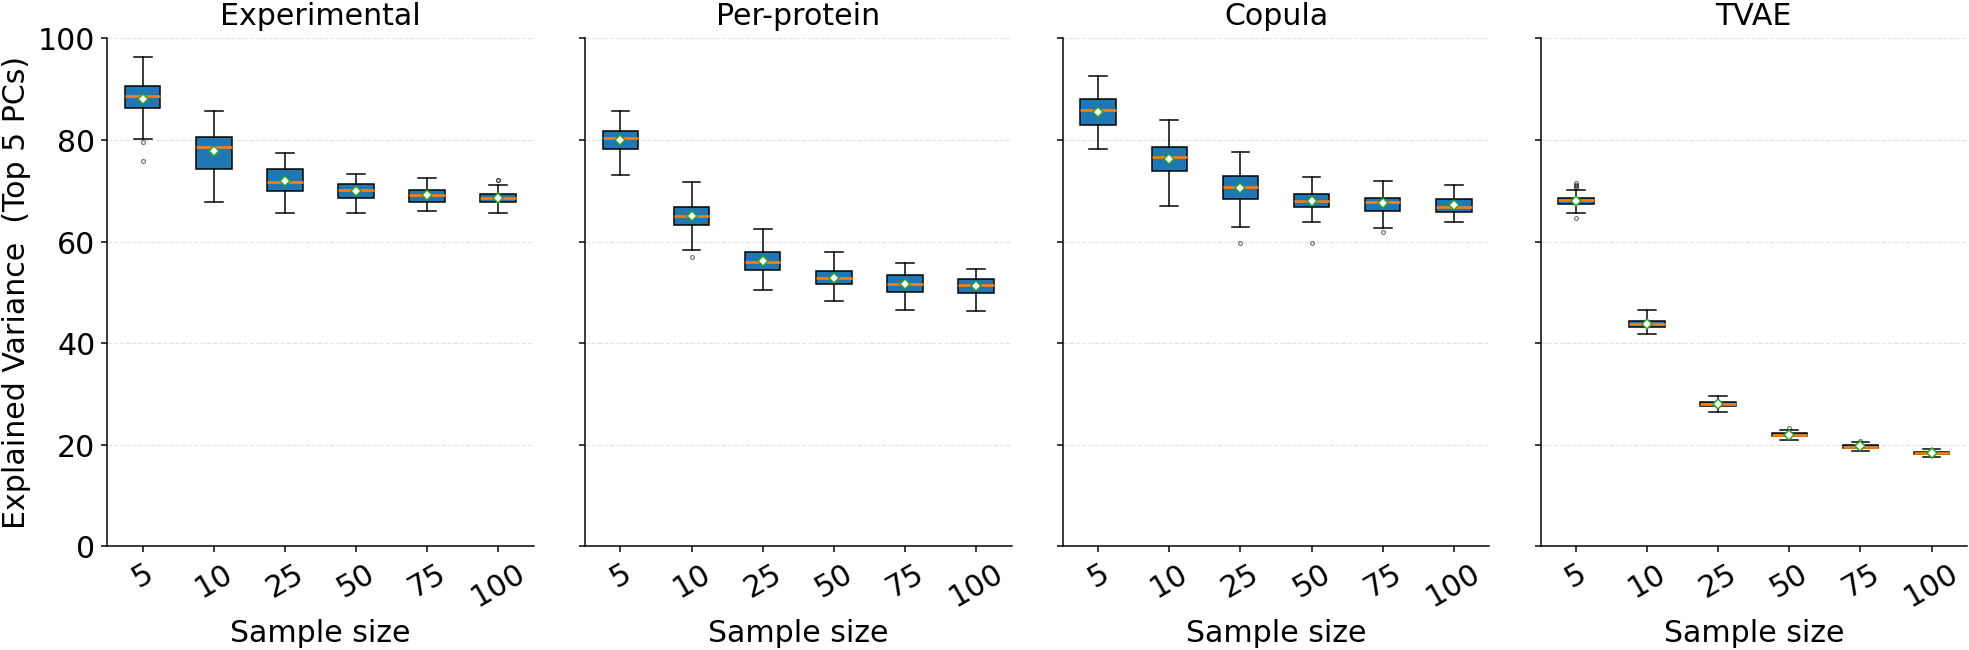

In [45]:
import matplotlib.pyplot as plt

def publication_boxpanel(
    dfs,
    titles,
    *,
    xlabel="Sample size",
    ylabel="Accuracy",
    ylim=(0, 1),
    figsize=(20, 5.5),
    rotation=30,
    show_mean=True,
    savepath=None,   # e.g., "accuracy_panels.pdf" or "accuracy_panels.png"
    dpi=600,
):
    """
    Publication-style multi-panel boxplot figure.

    Parameters
    ----------
    dfs : list of pandas.DataFrame
        Each df should have columns corresponding to sample sizes (or categories).
        Values are accuracies.
    titles : list of str
        Panel titles, same length as dfs.
    savepath : str or None
        If given, figure is saved (PDF/SVG recommended). Otherwise just shown.
    """

    # --- Global typography / rcParams (minimal, journal-friendly) ---
    plt.rcParams.update({
        "font.size": 18,
        "axes.titlesize": 18,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "axes.linewidth": 0.9,
        "xtick.major.width": 0.9,
        "ytick.major.width": 0.9,
        "xtick.major.size": 3.5,
        "ytick.major.size": 3.5,
        "figure.dpi": 120,
        "savefig.dpi": dpi,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    })

    n = len(dfs)
    fig, axes = plt.subplots(
        1, n, figsize=figsize, sharey=True,
        gridspec_kw={"wspace": 0.12}
    )
    if n == 1:
        axes = [axes]

    for i, (df, title, ax) in enumerate(zip(dfs, titles, axes)):
        # Ensure deterministic column order
        cols = list(df.columns)

        ax.boxplot(
            [df[c].dropna().values for c in cols],
            labels=[str(c) for c in cols],
            patch_artist=True,
            showmeans=show_mean,
            meanprops=dict(marker="D", markersize=4, markerfacecolor="white",
                           markeredgewidth=0.9),
            medianprops=dict(linewidth=1.6),
            boxprops=dict(linewidth=0.9),
            whiskerprops=dict(linewidth=0.9),
            capprops=dict(linewidth=0.9),
            flierprops=dict(marker="o", markersize=2.3, markerfacecolor="none",
                            markeredgewidth=0.7, alpha=0.55),
        )

        # Style: white boxes + subtle outlines (prints well)
        for b in ax.artists:
            b.set_facecolor("white")
            b.set_edgecolor("black")

        ax.set_title(title, pad=8)
        ax.set_xlabel(xlabel)
        ax.set_ylim(*ylim)

        # Light y-grid only
        ax.grid(True, axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
        ax.grid(False, axis="x")

        # Rotate tick labels gently (avoid 45 unless needed)
        ax.tick_params(axis="x", rotation=rotation)

        # Clean spines
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Only left panel gets y-label
        if i == 0:
            ax.set_ylabel(ylabel)

    fig.align_ylabels(axes)

    if savepath:
        fig.savefig(savepath)
    plt.show()


# --- Usage (replace with your existing objects) ---
publication_boxpanel(
    dfs=[
        experimental_pca_var,
        tvae_pca_var,
        copula_pca_var,
        pprotein_pca_var,
    ],
    titles=[
        "Experimental",
        "Per-protein",
        "Copula",
        "TVAE"
    ],
    savepath=None,  # e.g. "accuracy_panels.pdf"
    xlabel="Sample size",
    ylabel="Explained Variance (Top 5 PCs)",
    ylim=(0, 100),
)

In [41]:
experimental_pca_var

,5,10,25,50,75,100
0,86.827556,79.937850,68.165417,70.098896,68.489761,68.442886
1,90.587224,78.470715,71.865000,72.095776,71.123937,69.795551
2,91.734359,82.672767,65.651392,70.816086,71.055272,66.154527
3,88.661831,75.807091,69.345447,71.091697,71.603947,69.053573
4,92.034099,79.902161,75.422807,70.214434,69.040734,68.504034
...,...,...,...,...,...,...
95,92.489037,80.925844,74.647560,69.151326,66.770815,68.161710
96,90.596666,84.072427,73.274041,70.313028,69.486346,67.639213
97,88.908620,85.729397,69.820135,69.406499,69.466253,68.088550
98,87.119416,73.806617,75.096488,70.986417,70.218709,69.106623


## $t$-test Power Calcuation

### Calculate experimental "positives"

In [21]:
# Split into health and disease
from MSquantSim.downstreamanalysis import run_ttest

mel_healthy.loc[:, "Condition"] = "u"
mel_disease.loc[:, "Condition"] = "m"

experimental_input = pd.concat([mel_healthy, mel_disease], axis=0)
da_results = run_ttest(
    experimental_input, condition_col='Condition', equal_var=False,
    adjust_pvalues=True, significance_level=0.05, min_samples=2, 
    sort_by_pvalue=True)

positives = da_results.loc[da_results["significant"] == True]["Protein"].values

In [22]:
n_samples = [5, 10, 25, 50]

### Experimental

In [23]:
experimental_positive_counts = dict()
experimental_valid_iterations = dict()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = validation_mel_input.sample(n=i*2, random_state=s)
        try:
            da_results = run_ttest(training_data)
        except ValueError:
            # Subsample landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
    experimental_positive_counts[i] = counts
    experimental_valid_iterations[i] = n_valid

experimental_positive_counts = pd.DataFrame(experimental_positive_counts)
experimental_positive_counts.index.name = "Protein"
experimental_positive_counts = experimental_positive_counts.reset_index()

print("Iterations with both conditions present:", experimental_valid_iterations)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:   3%|▎         | 3/100 [00:00<00:04, 22.54it/s]


Running simulations: 5:   6%|▌         | 6/100 [00:00<00:03, 24.38it/s]


Running simulations: 5:   9%|▉         | 9/100 [00:00<00:03, 25.38it/s]


Running simulations: 5:  13%|█▎        | 13/100 [00:00<00:03, 27.97it/s]

...


Running simulations: 50:  93%|█████████▎| 93/100 [00:03<00:00, 24.93it/s]


Running simulations: 50:  96%|█████████▌| 96/100 [00:04<00:00, 22.63it/s]


Running simulations: 50:  99%|█████████▉| 99/100 [00:04<00:00, 16.54it/s]


Running simulations: 50: 100%|██████████| 100/100 [00:04<00:00, 22.34it/s]

Iterations with both conditions present: {5: 99, 10: 100, 25: 100, 50: 100}


### Copula

In [24]:
copula_positive_counts = dict()
copula_valid_iterations = dict()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        copula_data = copula_input[i][s]
        try:
            da_results = run_ttest(copula_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
    copula_positive_counts[i] = counts
    copula_valid_iterations[i] = n_valid

copula_positive_counts = pd.DataFrame(copula_positive_counts)
copula_positive_counts.index.name = "Protein"
copula_positive_counts = copula_positive_counts.reset_index()

print("Iterations with both conditions present:", copula_valid_iterations)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:   1%|          | 1/100 [00:00<00:12,  7.72it/s]


Running simulations: 5:   3%|▎         | 3/100 [00:00<00:08, 12.06it/s]


Running simulations: 5:   5%|▌         | 5/100 [00:00<00:08, 11.33it/s]


Running simulations: 5:   7%|▋         | 7/100 [00:00<00:08, 11.38it/s]

...


Running simulations: 50:  93%|█████████▎| 93/100 [00:05<00:00, 22.79it/s]


Running simulations: 50:  96%|█████████▌| 96/100 [00:05<00:00, 23.25it/s]


Running simulations: 50:  99%|█████████▉| 99/100 [00:06<00:00, 23.40it/s]


Running simulations: 50: 100%|██████████| 100/100 [00:06<00:00, 16.45it/s]

Iterations with both conditions present: {5: 100, 10: 100, 25: 100, 50: 100}


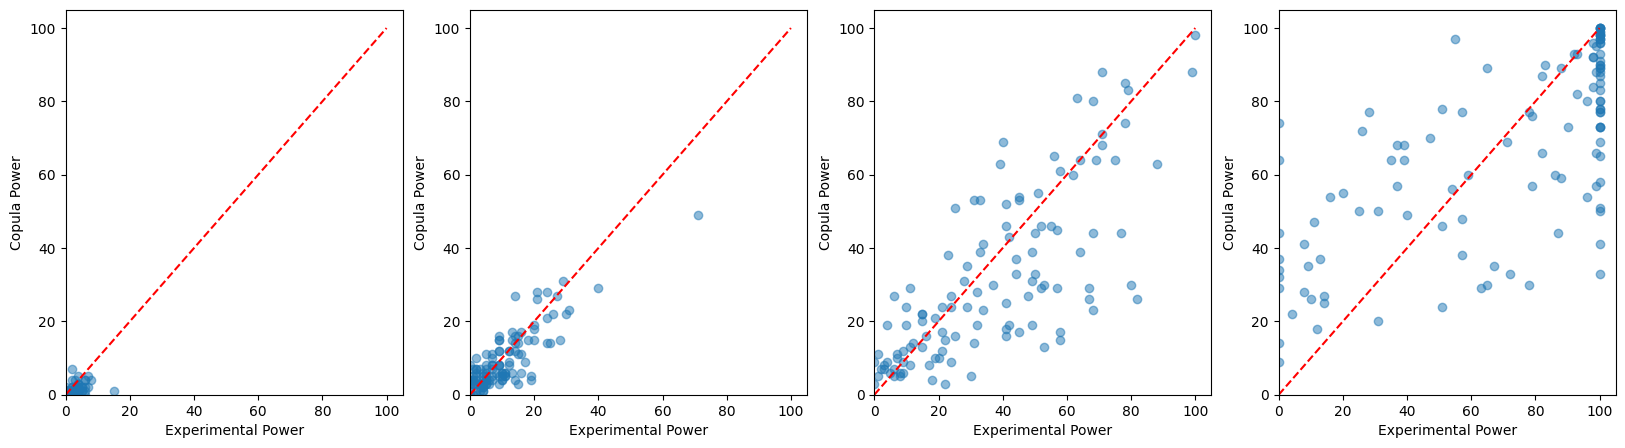

In [55]:
fig, ax = plt.subplots(1,4, figsize=(20,5))

ax[0].scatter(x=experimental_positive_counts.iloc[:,1],
              y=copula_positive_counts.iloc[:,1], alpha=0.5)
ax[1].scatter(x=experimental_positive_counts.iloc[:,2],
              y=copula_positive_counts.iloc[:,2], alpha=0.5)
ax[2].scatter(x=experimental_positive_counts.iloc[:,3],
              y=copula_positive_counts.iloc[:,3], alpha=0.5)
ax[3].scatter(x=experimental_positive_counts.iloc[:,4],
              y=copula_positive_counts.iloc[:,4], alpha=0.5)

for i in range(4):
    #identitiy line
    ax[i].plot([0,100], [0,100], color='red', linestyle='--')
    ax[i].set_xlim(0,105)
    ax[i].set_ylim(0,105)

    ax[i].set_xlabel("Experimental Power")
    ax[i].set_ylabel("Copula Power")


### TVAE

In [25]:
tvae_positive_counts = dict()
tvae_valid_iterations = dict()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        tvae_data = tvae_input[i][s]
        try:
            da_results = run_ttest(tvae_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
    tvae_positive_counts[i] = counts
    tvae_valid_iterations[i] = n_valid

tvae_positive_counts = pd.DataFrame(tvae_positive_counts)
tvae_positive_counts.index.name = "Protein"
tvae_positive_counts = tvae_positive_counts.reset_index()

print("Iterations with both conditions present:", tvae_valid_iterations)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:   3%|▎         | 3/100 [00:00<00:03, 24.49it/s]


Running simulations: 5:   6%|▌         | 6/100 [00:00<00:03, 24.90it/s]


Running simulations: 5:   9%|▉         | 9/100 [00:00<00:03, 24.95it/s]


Running simulations: 5:  12%|█▏        | 12/100 [00:00<00:03, 24.69it/s]

...


Running simulations: 50:  93%|█████████▎| 93/100 [00:04<00:00, 20.56it/s]


Running simulations: 50:  96%|█████████▌| 96/100 [00:04<00:00, 20.49it/s]


Running simulations: 50:  99%|█████████▉| 99/100 [00:04<00:00, 21.82it/s]


Running simulations: 50: 100%|██████████| 100/100 [00:04<00:00, 22.22it/s]

Iterations with both conditions present: {5: 100, 10: 100, 25: 100, 50: 100}


In [57]:
tvae_positive_counts

,Protein,5,10,25,50
0,TMSB4X,52,100,100,100
1,LGALS3,46,98,100,100
2,NQO1,34,98,100,100
3,S100A6,50,98,100,100
4,FASN,39,100,100,100
...,...,...,...,...,...
110,LBR,3,13,35,67
111,CAT,0,3,5,16
112,PCNA,7,25,68,95
113,PTPN6,0,1,2,5


### Per-protein

In [26]:
pprotein_positive_counts = dict()
pprotein_valid_iterations = dict()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        pprotein_data = pprotein_input[i][s]
        try:
            da_results = run_ttest(pprotein_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
    pprotein_positive_counts[i] = counts
    pprotein_valid_iterations[i] = n_valid

pprotein_positive_counts = pd.DataFrame(pprotein_positive_counts)
pprotein_positive_counts.index.name = "Protein"
pprotein_positive_counts = pprotein_positive_counts.reset_index()

print("Iterations with both conditions present:", pprotein_valid_iterations)


Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]


Running simulations: 5:   3%|▎         | 3/100 [00:00<00:03, 25.76it/s]


Running simulations: 5:   6%|▌         | 6/100 [00:00<00:03, 25.39it/s]


Running simulations: 5:   9%|▉         | 9/100 [00:00<00:03, 24.87it/s]


Running simulations: 5:  12%|█▏        | 12/100 [00:00<00:03, 24.70it/s]

...


Running simulations: 50:  92%|█████████▏| 92/100 [00:04<00:00, 21.56it/s]


Running simulations: 50:  95%|█████████▌| 95/100 [00:04<00:00, 21.91it/s]


Running simulations: 50:  98%|█████████▊| 98/100 [00:04<00:00, 22.19it/s]


Running simulations: 50: 100%|██████████| 100/100 [00:04<00:00, 21.48it/s]

Iterations with both conditions present: {5: 100, 10: 100, 25: 100, 50: 100}


In [27]:
pprotein_positive_counts

,Protein,5,10,25,50
0,TMSB4X,2,42,100,100
1,LGALS3,1,26,98,100
2,NQO1,1,19,99,100
3,S100A6,0,18,99,100
4,FASN,1,15,95,100
...,...,...,...,...,...
110,LBR,0,1,3,15
111,CAT,0,1,4,11
112,PCNA,0,0,4,9
113,PTPN6,1,0,2,12


In [28]:
# t-test power results for the combined paper figure (simulation_comparison.ipynb).
# Counts: number of valid iterations in which each experimentally significant protein
# was detected. "experimental" subsamples the validation set.
power_results = {
    "experimental": (experimental_positive_counts, experimental_valid_iterations),
    "pprotein": (pprotein_positive_counts, pprotein_valid_iterations),
    "copula": (copula_positive_counts, copula_valid_iterations),
    "tvae": (tvae_positive_counts, tvae_valid_iterations),
}
for name, (counts, valid) in power_results.items():
    counts.to_csv(f"../data/results/MEL/{name}_power_counts.csv", index=False)
    (pd.Series(valid, name="n_valid").rename_axis("n_samples")
       .to_csv(f"../data/results/MEL/{name}_power_valid.csv"))

### Compare

In [60]:
copula_positive_counts

,Protein,5,10,25,50
0,TMSB4X,1,49,98,100
1,LGALS3,2,29,88,100
2,NQO1,3,28,88,100
3,S100A6,1,27,83,99
4,FASN,5,31,85,99
...,...,...,...,...,...
110,LBR,1,2,9,20
111,CAT,0,1,4,24
112,PCNA,0,3,6,28
113,PTPN6,0,0,3,9


In [61]:
experimental_positive_counts.iloc[:,1:].mean(axis=0).values

array([ 2.14782609, 10.37391304, 36.97391304, 68.75652174])

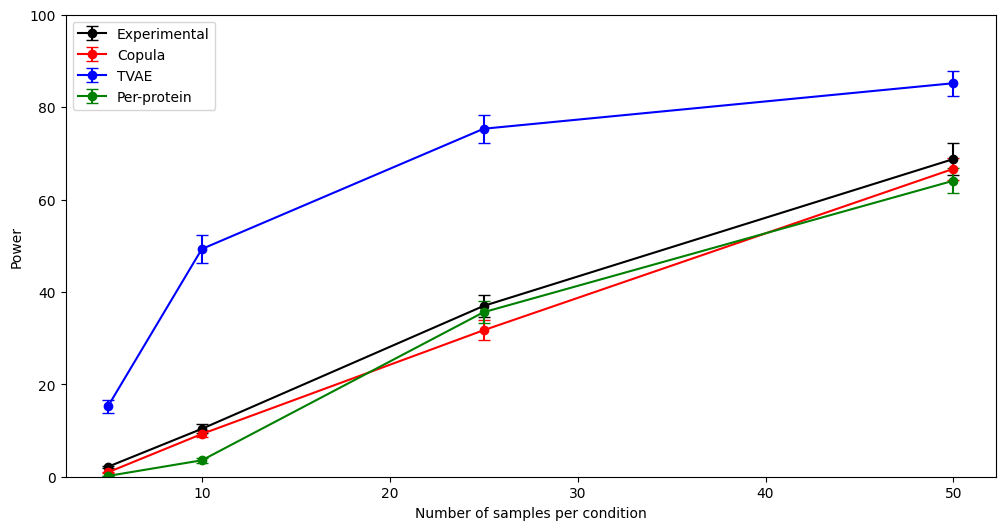

In [63]:
fig, ax = plt.subplots(figsize=(12, 6))

# Error bars show the standard error of the mean across the "positive" proteins
ax.errorbar(n_samples, 
            experimental_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=experimental_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Experimental', color='black')

ax.errorbar(n_samples, 
            copula_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=copula_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Copula', color='red')

ax.errorbar(n_samples, 
            tvae_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=tvae_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='TVAE', color='blue')

ax.errorbar(n_samples, 
            pprotein_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=pprotein_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Per-protein', color='green')
ax.set_ylim(0, 100)
ax.set_xlabel('Number of samples per condition')
ax.set_ylabel('Power')
ax.legend()

## Fine-grid Copula analyses for the sample-size table

Plan 4.1 (`plans/step4_table.md`). The Copula RF, PCA and t-test power analyses above, rerun on a finer grid of replicates per group, n ∈ {5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100}, with 100 iterations each (iteration s subsamples simulated dataset s with `random_state=s`). Inputs, `train_rf`, `get_pca_explained_variance` (top 5 PCs) and the power counts over the experimentally significant proteins (`positives`, from the t-test section) are as in the existing cells. Prerequisites: the data cells, the simulation-loading cell and the `positives` cell of the t-test section.

In [ ]:
import time

fine_n = [5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100]
fine_iterations = 100

copula_input_fine = {}
for i in fine_n:
    temp_list = list()
    for s in range(fine_iterations):
        copula_healthy_results = copula_sim_mel_healthy_multi_masked[s].sample(n=i, random_state=s)
        copula_disease_results = copula_sim_mel_disease_multi_masked[s].sample(n=i, random_state=s)

        copula_healthy_results.loc[:, "Condition"] = "u"
        copula_disease_results.loc[:, "Condition"] = "m"

        temp_list.append(pd.concat([copula_healthy_results,
                                    copula_disease_results], axis=0))

    copula_input_fine[i] = temp_list

In [ ]:
# PCA: % variance explained by the top 5 PCs
copula_pca_var_fine = dict()

for i in fine_n:
    temp_acc = list()
    for s in range(fine_iterations):
        copula_data = copula_input_fine[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(copula_data.drop(columns=["Condition"]), 5)["total_variance"])
        except Exception:
            temp_acc.append(np.nan)
    copula_pca_var_fine[i] = temp_acc
copula_pca_var_fine = pd.DataFrame(copula_pca_var_fine)
copula_pca_var_fine.to_csv("../data/results/MEL/copula_pca_var_fine.csv")
copula_pca_var_fine.mean().round(2)

In [ ]:
# t-test power: detections of the experimentally significant proteins (positives)
copula_positive_counts_fine = dict()
copula_valid_iterations_fine = dict()

for i in fine_n:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in range(fine_iterations):
        copula_data = copula_input_fine[i][s]
        try:
            da_results = run_ttest(copula_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
    copula_positive_counts_fine[i] = counts
    copula_valid_iterations_fine[i] = n_valid

copula_positive_counts_fine = pd.DataFrame(copula_positive_counts_fine)
copula_positive_counts_fine.index.name = "Protein"
copula_positive_counts_fine = copula_positive_counts_fine.reset_index()

copula_positive_counts_fine.to_csv("../data/results/MEL/copula_power_counts_fine.csv", index=False)
(pd.Series(copula_valid_iterations_fine, name="n_valid").rename_axis("n_samples")
   .to_csv("../data/results/MEL/copula_power_valid_fine.csv"))
print("Iterations with both conditions present:", copula_valid_iterations_fine)
print("mean power over positives:",
      (copula_positive_counts_fine.set_index("Protein").mean()
       / pd.Series(copula_valid_iterations_fine)).round(3).to_dict())

In [ ]:
# Random forest accuracy on the validation set (long: 1-2 h or more), split over two cells.
# The CSV is rewritten after each n, so a partial run keeps the completed columns.
copula_model_accuracy_fine = dict()


def run_rf_fine(n_values):
    for i in n_values:
        temp_acc = list()
        t0 = time.time()
        for s in range(fine_iterations):
            training_data = copula_input_fine[i][s]

            X = training_data.drop("Condition", axis=1)
            y = training_data["Condition"]
            temp_acc.append(train_rf(X, y, validation_mel_input))
        copula_model_accuracy_fine[i] = temp_acc
        pd.DataFrame(copula_model_accuracy_fine).to_csv(
            "../data/results/MEL/copula_model_accuracy_fine.csv")
        print(f"n = {i}: mean accuracy {np.mean(temp_acc):.3f} ({time.time() - t0:.0f} s)",
              flush=True)


run_rf_fine([n for n in fine_n if n <= 40])

In [ ]:
run_rf_fine([n for n in fine_n if n > 40])
copula_model_accuracy_fine = pd.DataFrame(copula_model_accuracy_fine)
copula_model_accuracy_fine.mean().round(3)

## Limited training data

Plan 3.6 (`plans/limited_n.md`). How much training data the simulators need. For each group, protein panels P ∈ {15, 30, 60, 124} (nested: the P proteins with the highest variance in the group's full training data) and training sizes N ∈ {10, 25, 50, 100, 150, full} cells, with 5 seeded random subsets per N (for N = full the subset is the whole group and repeats differ only in the simulation seed). Copula and Per-protein are trained on each subset (TVAE only for P = 124, repeat 1), one dataset of the full group size is simulated, and S_corr is computed against the correlation matrix of the same P proteins in the full data. A failed fit is recorded with its error type. Uses the helpers defined in the missing-values section.

In [8]:
# Helpers shared by the missing-value and limited-training-data sections.
import time
import torch
from sdv.single_table import TVAESynthesizer
from sdv.metadata import SingleTableMetadata
from MSquantSim.simulate import fit_copula, sample_copula, fit_per_protein, sample_per_protein
from MSquantSim.utility import calibrate_offsets
from MSquantSim.plotting import cluster_order


def upper_triangle(corr):
    corr = np.asarray(corr)
    return corr[np.triu_indices_from(corr, k=1)]


def s_corr(corr, reference):
    # Pearson correlation between the upper triangles of two correlation matrices; pairs
    # undefined in either matrix (e.g. a constant simulated protein) are skipped
    x, y = upper_triangle(corr), upper_triangle(reference)
    ok = np.isfinite(x) & np.isfinite(y)
    return float(np.corrcoef(x[ok], y[ok])[0, 1])


def knn_impute(df):
    # KNN imputation as for the training data (k = 5, uniform weights)
    imputed = KNNImputer(n_neighbors=5, weights="uniform").fit_transform(df)
    return pd.DataFrame(imputed, columns=df.columns, index=df.index)


def fit_tvae(data, seed):
    # TVAE as in simulate.tvae_model (CPU), with numpy and torch seeded so the fit reproduces
    np.random.seed(seed)
    torch.manual_seed(seed)
    metadata = SingleTableMetadata()
    metadata.detect_from_dataframe(data=data)
    model = TVAESynthesizer(metadata, enable_gpu=False)
    model.fit(data)
    return model

In [9]:
# One task = (group, P, N, repeat): train on the subset, simulate the full group size, score.
from joblib import Parallel, delayed

lt_groups = {"healthy": mel_healthy, "disease": mel_disease}
lt_panel_sizes = [15, 30, 60, 124]
lt_sizes = [10, 25, 50, 100, 150, "full"]
lt_repeats = [1, 2, 3, 4, 5]
lt_heatmap_sizes = [10, 50, "full"]   # Copula heatmaps for P = 124, repeat 1
lt_n_jobs = 12                        # results do not depend on this (every task is seeded)


def lt_task(group, gi, complete, panel, pi, n_label, ni, rep, heat_order=None):
    n_cells = len(complete)
    if n_label == "full":
        rows = np.arange(n_cells)
    else:
        rows = np.sort(np.random.default_rng([36, gi, ni, rep]).choice(n_cells, n_label,
                                                                       replace=False))
    train = complete.iloc[rows][panel]
    full_corr = complete[panel].corr().to_numpy()
    simulators = ["Copula", "Per-protein"]
    if len(panel) == complete.shape[1] and rep == 1:
        simulators.append("TVAE")
    seed = 360000 + 10000 * gi + 1000 * pi + 10 * ni + rep
    out, heat = [], None
    for name in simulators:
        score, nonfinite, error = np.nan, np.nan, ""
        try:
            if name == "Copula":
                sim = sample_copula(fit_copula(train), n_cells, random_state=seed)
            elif name == "Per-protein":
                sim = sample_per_protein(fit_per_protein(train), n_cells,
                                         rng=np.random.default_rng(seed))
            else:
                sim = fit_tvae(train, seed).sample(num_rows=n_cells)
            values = sim[panel].to_numpy(dtype=float)
            nonfinite = float(np.mean(~np.isfinite(values)))
            score = s_corr(sim[panel].corr().to_numpy(), full_corr)
            if name == "Copula" and heat_order is not None:
                heat = sim[heat_order].corr().to_numpy()
        except Exception as e:
            error = type(e).__name__
        out.append(dict(group=group, P=len(panel), N=len(rows), n_label=str(n_label),
                        repeat=rep, simulator=name, s_corr=score, error=error,
                        nonfinite_frac=nonfinite))
    return out, (group, n_label, heat)


lt_tasks, lt_corrs = [], {}
for gi, (group, group_df) in enumerate(lt_groups.items()):
    complete = group_df.drop(columns=["Condition"], errors="ignore")
    by_variance = complete.var().sort_values(ascending=False).index.tolist()
    order = cluster_order(complete)
    lt_corrs[f"{group}__proteins"] = np.array(order)
    lt_corrs[f"{group}__full_data"] = complete[order].corr().to_numpy()
    for pi, P in enumerate(lt_panel_sizes):
        for ni, n_label in enumerate(lt_sizes):
            for rep in lt_repeats:
                heat_order = (order if P == complete.shape[1] and rep == 1
                              and n_label in lt_heatmap_sizes else None)
                lt_tasks.append(delayed(lt_task)(group, gi, complete, by_variance[:P], pi,
                                                 n_label, ni, rep, heat_order))

t0 = time.time()
lt_results = Parallel(n_jobs=lt_n_jobs)(lt_tasks)
print(f"{len(lt_tasks)} tasks in {time.time() - t0:.0f} s")

lt_scores = pd.DataFrame([row for rows, _ in lt_results for row in rows])
for _, (group, n_label, heat) in lt_results:
    if heat is not None:
        lt_corrs[f"{group}__N{n_label}"] = heat
lt_scores.to_csv("../data/results/MEL/training_size_scores.csv", index=False)
np.savez_compressed("../data/results/MEL/training_size_correlations.npz", **lt_corrs)
print(lt_scores.shape, "|", {k: v.shape for k, v in lt_corrs.items()})

240 tasks in 203 s
(492, 9) | {'healthy__proteins': (124,), 'healthy__full_data': (124, 124), 'disease__proteins': (124,), 'disease__full_data': (124, 124), 'healthy__N10': (124, 124), 'healthy__N50': (124, 124), 'healthy__Nfull': (124, 124), 'disease__N10': (124, 124), 'disease__N50': (124, 124), 'disease__Nfull': (124, 124)}


N                          10     25     50     100    150    250    252
group   simulator   P                                                   
disease Copula      15   0.550  0.715  0.857  0.880  0.939  0.909    NaN
                    30   0.544  0.719  0.826  0.906  0.927  0.934    NaN
                    60   0.493  0.693  0.802  0.878  0.924  0.924    NaN
                    124  0.472  0.659  0.762  0.875  0.919  0.943    NaN
        Per-protein 15   0.041  0.011  0.006  0.054  0.067  0.005    NaN
                    30   0.005  0.004  0.017  0.028  0.007  0.028    NaN
                    60   0.011  0.003 -0.001 -0.011 -0.000 -0.002    NaN
                    124 -0.001  0.008  0.015 -0.004 -0.003  0.002    NaN
        TVAE        124  0.358  0.375  0.314  0.190  0.238  0.430    NaN
healthy Copula      15   0.447  0.627  0.803  0.876  0.882    NaN  0.947
                    30   0.498  0.600  0.798  0.875  0.915    NaN  0.935
                    60   0.422  0.661  0.808  0.892

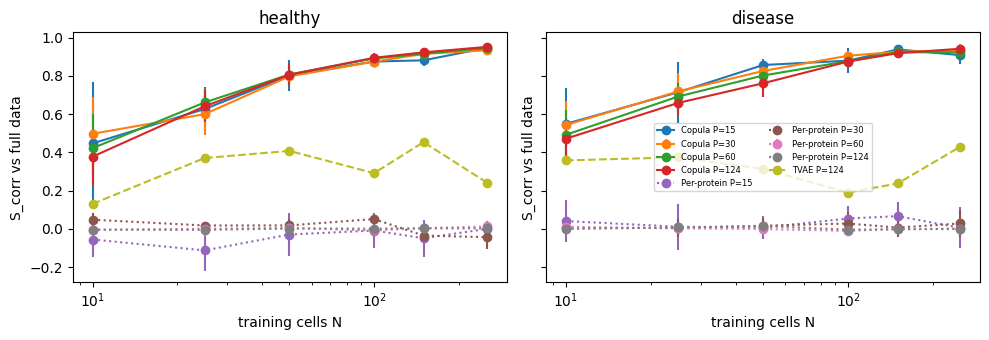

In [10]:
# Mean (SD) S_corr per P and N; failures; sanity plot.
lt_summary = (lt_scores.groupby(["group", "simulator", "P", "N"])["s_corr"]
              .agg(["mean", "std", "count"]).round(3))
print(lt_summary.unstack("N")["mean"].to_string())
failed = lt_scores[lt_scores["error"] != ""]
print("failed fits:", len(failed))
if len(failed):
    print(failed.groupby(["group", "simulator", "P", "N", "error"]).size().to_string())
print("max non-finite fraction:", lt_scores["nonfinite_frac"].max())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, (group, g) in zip(ax, lt_scores.groupby("group", sort=False)):
    for (sim, P), gs in g.groupby(["simulator", "P"]):
        m = gs.groupby("N")["s_corr"].agg(["mean", "std"])
        ls = {"Copula": "-", "Per-protein": ":", "TVAE": "--"}[sim]
        a.errorbar(m.index, m["mean"], yerr=m["std"], ls=ls, marker="o", label=f"{sim} P={P}")
    a.set(title=group, xscale="log", xlabel="training cells N", ylabel="S_corr vs full data")
ax[1].legend(fontsize=6, ncol=2)
plt.tight_layout()
plt.show()

In [ ]:
# TVAE repeats 2-5 (P = 124, every N), so TVAE gets error bars like Copula and Per-protein.
# Training subsets, protein order and seeds follow lt_task exactly, so each subset is the one
# used by the Copula repeat of the same group, N and repeat. Repeat 1 is refitted only as a
# reproducibility check against training_size_scores.csv; it is not saved again.
# This cell only defines the tasks; the next cell runs them (60 TVAE fits) and saves.
# Prerequisites: data cells (imports, load/filter, split, KNN imputation, group split) and the
# helper cell of the missing-values section (fit_tvae, s_corr, time).
from joblib import Parallel, delayed

lt_groups = {"healthy": mel_healthy, "disease": mel_disease}
lt_panel_sizes = [15, 30, 60, 124]
lt_sizes = [10, 25, 50, 100, 150, "full"]
lt_extra_repeats = [2, 3, 4, 5]
lt_n_jobs = 12   # as in the Copula/Per-protein run (TVAE threads per worker = cores // n_jobs)


def lt_tvae_task(group, gi, complete, n_label, ni, rep):
    n_cells = len(complete)
    if n_label == "full":
        rows = np.arange(n_cells)
    else:
        rows = np.sort(np.random.default_rng([36, gi, ni, rep]).choice(n_cells, n_label,
                                                                       replace=False))
    panel = complete.var().sort_values(ascending=False).index.tolist()   # P = 124, as in lt_task
    pi = lt_panel_sizes.index(len(panel))
    train = complete.iloc[rows][panel]
    full_corr = complete[panel].corr().to_numpy()
    seed = 360000 + 10000 * gi + 1000 * pi + 10 * ni + rep
    score, nonfinite, error = np.nan, np.nan, ""
    try:
        sim = fit_tvae(train, seed).sample(num_rows=n_cells)
        values = sim[panel].to_numpy(dtype=float)
        nonfinite = float(np.mean(~np.isfinite(values)))
        score = s_corr(sim[panel].corr().to_numpy(), full_corr)
    except Exception as e:
        error = type(e).__name__
    return dict(group=group, P=len(panel), N=len(rows), n_label=str(n_label), repeat=rep,
                simulator="TVAE", s_corr=score, error=error, nonfinite_frac=nonfinite)


lt_tvae_tasks = []
for gi, (group, group_df) in enumerate(lt_groups.items()):
    complete = group_df.drop(columns=["Condition"], errors="ignore")
    for ni, n_label in enumerate(lt_sizes):
        for rep in [1] + lt_extra_repeats:
            lt_tvae_tasks.append(delayed(lt_tvae_task)(group, gi, complete, n_label, ni, rep))
print(len(lt_tvae_tasks), "TVAE fits defined")

In [ ]:
# Run the TVAE fits, save repeats 2-5, check repeat 1 against the saved value, summarize.
t0 = time.time()
lt_tvae = pd.DataFrame(Parallel(n_jobs=lt_n_jobs)(lt_tvae_tasks))
print(f"{len(lt_tvae_tasks)} TVAE fits in {time.time() - t0:.0f} s")

lt_tvae_extra = lt_tvae[lt_tvae["repeat"].isin(lt_extra_repeats)].reset_index(drop=True)
lt_tvae_extra.to_csv("../data/results/MEL/training_size_scores_tvae_extra.csv", index=False)
print(lt_tvae_extra.shape, "| failed fits:", int((lt_tvae_extra["error"] != "").sum()))

# reproducibility check: refitted repeat 1 vs the saved repeat 1
lt_saved = pd.read_csv("../data/results/MEL/training_size_scores.csv", dtype={"n_label": str})
lt_check = lt_tvae[lt_tvae["repeat"] == 1].merge(
    lt_saved[lt_saved["simulator"] == "TVAE"][["group", "n_label", "s_corr"]],
    on=["group", "n_label"], suffixes=("", "_saved"))
print("repeat 1 refit vs saved: max |difference| in S_corr =",
      float((lt_check["s_corr"] - lt_check["s_corr_saved"]).abs().max()))

# TVAE mean (SD) over repeats 1-5 (repeat 1 from training_size_scores.csv)
lt_tvae_all = pd.concat([lt_saved[lt_saved["simulator"] == "TVAE"], lt_tvae_extra])
print(lt_tvae_all.groupby(["group", "n_label"], sort=False)["s_corr"]
      .agg(["mean", "std", "count"]).round(3).to_string())

## Placement benchmark (4.2), MEL-SCP-DDA

Plan `plans/placement_benchmark.md` ("Design", "Addition: ground truth vs Copula vs standard calculator" and "MEL run of the placement benchmark and addition"; Devon, 2026-10-19: "do the same thing for MEL"). The MEL run of the PDAC-DIA placement benchmark and its method comparison (`PDAC_case_study.ipynb`, "Placement benchmark (4.2)"). Two questions: does the placement of the K differentially abundant (DE) proteins, random vs correlated modules, change the distributions of power (TPR) and FDP when K is held fixed; and do the Copula and the standard calculator reproduce the ground truth's P(success) for each placement?

- Data: the MEL cells without the three almost-empty runs eAL00263, eAL00264 and eAL00265 (39 cells, about 98% missing; R16), leaving 589 cells; the 124 proteins of the pilot panel (INDRA component, cells 7–8); KNN-imputed (k = 5, uniform weights) on the 589 cells; each protein centered within condition (`center_by_group(..., "Condition")`). This null (589 × 124) is the real-noise pool.
- One experiment: 2n pool rows, split into two groups of n; the truth (|log2FC| with the truth's signs) added to group 2; Welch $t$-tests + BH at FDR 0.05 (`MSquantSim.power.run_experiments`). Success = TPR ≥ 0.8 and FDP ≤ 0.05.
- Methods, all on the same truth assignments:
  - **ground_truth:** real null rows (`independent_columns=False`);
  - **resampled:** each protein draws its own 2n of its 589 null values (`independent_columns=True`), which keeps every protein's values and removes the correlation between proteins;
  - **copula:** 2n rows of a 10,000-row pool sampled (`sample_copula`, random_state 20261020) from the Gaussian copula fitted to the null (`fit_copula`);
  - **calculator_sim:** the standard calculator's assumptions: 10,000 rows of independent Normal(0, σ²) for all 124 proteins, σ² = the median within-group variance of the imputed 589-cell data; rng `SeedSequence(20261020, spawn_key=(3,))`.
- Truths (K fixed): **clustered** (`clustered_de_sets` on the copula correlation, in the null's protein order: a seed drawn uniformly from the unselected proteins plus its unselected partners with r > 0.5, at most the 15 strongest, repeated until K are selected; the last cluster trimmed to exactly K by dropping its weakest partners; one random sign per cluster; a partnerless seed is a singleton) or **random** (`random_de_set`: K uniform proteins, a random sign each; logged as K singleton clusters).
- Grid: method {ground_truth, resampled, copula, calculator_sim} × placement {random, clustered} × K {6, 12, 25} (5, 10, 20% of 124) × log2FC {0.58, 1} × n per group {3, 5, 10, 20, 30, 40, 50, 75, 100} = 432 cells, R = 500 replicates each (216,000 experiments). The 589-row pool allows n ≤ 294, so the ground truth needs no sample-reuse caveat on this grid.
- Seeds (`np.random.SeedSequence(20261020, spawn_key=...)`, indices into the grids in the order listed above, log2FC order 0.58, 1): truths `spawn_key=(0, placement, K, n)`, drawn once per (placement, K, n), a new truth per replicate, shared by all four methods and both log2FC; rows `spawn_key=(1, method, placement, K, log2FC, n)`, one stream per cell.
- Logged per replicate: number of clusters, singleton clusters and their fraction, mean within-group variance of the DE set (`within_group_variance` of the imputed 589-cell data), mean |copula r| over the DE-set pairs.
- Standard calculator: `analytic_sample_size` (MSstats `designSampleSize` formula) with the median within-group variance, π₁ = K / 124, FDR 0.05, power 0.8.
- Compute: joblib over grid cells with 4 workers and 1 BLAS thread each; the Copula fit and sampling run with at most 4 BLAS threads.
- Outputs (`../data/results/MEL/`, the PDAC-DIA file names and formats): `placement_replicates.csv` (ground_truth and resampled, as correlation = "correlated" / "uncorrelated"), `placement_methods_replicates.csv` (copula and calculator_sim, column `method`), `placement_summary.csv`, `placement_methods_summary.csv`, `placement_clusters.csv` (clustered placement), `placement_calculator.csv`.
- To reproduce: `env -u USER python ../../plans/tools/run_cells.py MEL_case_study.ipynb 2,5,7-8,157-167` (cell numbers as of 2026-10-21, after the reorder; for `env -u USER` see cell 193). The section needs only cells 2, 5, 7 and 8 upstream, not the pilot or seed-design cells 184–189 and 193–203 (now in the Reserve).

In [5]:
# Placement benchmark data: 589 cells (runs eAL00263-65 dropped, R16), the 124 proteins of the
# pilot panel, KNN-imputed (k = 5, uniform) on the 589 cells, then centered within condition
import time
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from scipy.stats import spearmanr
from MSquantSim.power import (center_by_group, within_group_variance, clustered_de_sets,
                              random_de_set, run_experiments, summarize_success,
                              analytic_sample_size)
from MSquantSim.simulate import fit_copula, sample_copula

pb_entropy = 20261020
pb_fdr = 0.05
pb_dropped_runs = ["eAL00263", "eAL00264", "eAL00265"]
pb_prots = [c for c in mel_input_raw.columns if c != "Condition"]   # pilot panel (cells 7-8)
pb_p = len(pb_prots)
assert pb_p == 124 and len(set(pb_prots)) == pb_p

# Run identifies each cell's TMT run (cell 5 drops it from mel_input_raw; same rows, same order)
pb_raw = pd.read_csv('../data/mel/MEL_protein_level_data.csv', usecols=["Run", "Channel", "Condition"])
assert pb_raw.index.equals(mel_input_raw.index) and pb_raw["Condition"].equals(mel_input_raw["Condition"])
pb_keep = ~pb_raw["Run"].isin(pb_dropped_runs).to_numpy()
print(f"dropped {int((~pb_keep).sum())} cells (runs {', '.join(pb_dropped_runs)}; "
      f"{pb_raw.loc[~pb_keep, 'Condition'].value_counts().to_dict()}); kept {int(pb_keep.sum())} of {len(pb_raw)}")
pb_raw_data = mel_input_raw.loc[pb_keep, ["Condition"] + pb_prots]
print("cells per condition:", pb_raw_data["Condition"].value_counts().to_dict())

# Missingness before imputation, after the drop (124 proteins)
pb_cell_missing = pb_raw_data[pb_prots].isna().mean(axis=1)
pb_prot_missing = pb_raw_data[pb_prots].isna().mean(axis=0)
print(f"missing values: {int(pb_raw_data[pb_prots].isna().sum().sum())} of {pb_raw_data[pb_prots].size} "
      f"({pb_raw_data[pb_prots].isna().mean().mean():.1%})")
print(f"missing per cell: median {pb_cell_missing.median():.1%}, q95 {pb_cell_missing.quantile(0.95):.1%}, "
      f"max {pb_cell_missing.max():.1%}; cells > 50%: {int((pb_cell_missing > 0.5).sum())}, "
      f"> 25%: {int((pb_cell_missing > 0.25).sum())}, complete: {int((pb_cell_missing == 0).sum())}")
print(f"missing per protein: median {pb_prot_missing.median():.1%}, q95 {pb_prot_missing.quantile(0.95):.1%}, "
      f"max {pb_prot_missing.max():.1%}")
display(pb_cell_missing.groupby(pb_raw_data["Condition"])
        .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).round(3))

# KNN imputation on the 589 cells, null pool and per-protein within-group variance
pb_imputed = pd.DataFrame(
    KNNImputer(n_neighbors=5, weights="uniform").fit_transform(pb_raw_data[pb_prots]),
    columns=pb_prots, index=pb_raw_data.index)
pb_imputed.insert(0, "Condition", pb_raw_data["Condition"].to_numpy())
pb_null = center_by_group(pb_imputed, "Condition")[pb_prots]
pb_pool = pb_null.to_numpy(dtype=float)
pb_variance = within_group_variance(pb_imputed, "Condition")[pb_prots].to_numpy()
pb_median_variance = float(np.median(pb_variance))
assert np.isfinite(pb_pool).all()
print("imputed:", pb_imputed.shape, "| null pool:", pb_pool.shape, "| max |group mean| after centering:",
      float(pb_null.groupby(pb_imputed["Condition"]).mean().abs().max().max()))
print(f"within-group variance per protein: median {pb_median_variance:.4f}, "
      f"q05 {np.quantile(pb_variance, 0.05):.4f}, q95 {np.quantile(pb_variance, 0.95):.4f}; "
      f"max |value| of the null {np.abs(pb_pool).max():.3f}")

dropped 39 cells (runs eAL00263, eAL00264, eAL00265; {'u': 21, 'm': 18}); kept 589 of 628
cells per condition: {'m': 295, 'u': 294}
missing values: 5936 of 73036 (8.1%)
missing per cell: median 6.5%, q95 18.5%, max 37.9%; cells > 50%: 0, > 25%: 15, complete: 0
missing per protein: median 1.9%, q95 38.5%, max 45.7%


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
Condition,,,,,,,,,,,
m,295.0,0.072,0.049,0.008,0.048,0.065,0.073,0.113,0.174,0.283,0.339
u,294.0,0.091,0.055,0.024,0.056,0.073,0.105,0.145,0.199,0.324,0.379


imputed: (589, 125) | null pool: (589, 124) | max |group mean| after centering: 1.5376966517937543e-15
within-group variance per protein: median 0.7744, q05 0.5329, q95 1.3484; max |value| of the null 9.191


In [6]:
# Copula fitted to the null (at most 4 BLAS threads). Its correlation, reindexed to the null's
# protein order, defines the clusters
t0 = time.time()
with threadpool_limits(4):
    pb_copula = fit_copula(pb_null)
pb_fit_time = time.time() - t0
pb_corr = pb_copula.correlation.loc[pb_prots, pb_prots].to_numpy(dtype=float)
pb_abs_corr = np.abs(pb_corr)
assert np.isfinite(pb_corr).all()
print(f"Copula fit: {pb_fit_time:.0f} s; marginals:",
      pd.Series([type(getattr(u, "_instance", u)).__name__ for u in pb_copula.univariates])
      .value_counts().to_dict())

# Agreement of the copula correlation with the Pearson correlation of the null
pb_iu = np.triu_indices(pb_p, 1)
pb_pearson = pb_null.corr().to_numpy()
cop_r, pear_r = pb_corr[pb_iu], pb_pearson[pb_iu]
print(f"copula vs Pearson (off-diagonal pairs): Pearson r {np.corrcoef(cop_r, pear_r)[0, 1]:.3f}, "
      f"Spearman rho {spearmanr(cop_r, pear_r)[0]:.3f}, median |difference| "
      f"{np.median(np.abs(cop_r - pear_r)):.3f}, max |difference| {np.abs(cop_r - pear_r).max():.3f}; "
      f"median r: copula {np.median(cop_r):.3f}, Pearson {np.median(pear_r):.3f}; "
      f"pairs > 0.5: copula {(cop_r > 0.5).sum()}, Pearson {(pear_r > 0.5).sum()}, "
      f"both {((cop_r > 0.5) & (pear_r > 0.5)).sum()} of {len(cop_r)}")

# Partners per protein at r > 0.5
pb_partner_counts = pd.DataFrame({
    name: ((m > 0.5) & ~np.eye(pb_p, dtype=bool)).sum(axis=1)
    for name, m in [("copula", pb_corr), ("pearson", pb_pearson)]})
display(pd.DataFrame({
    "median": pb_partner_counts.median(), "q05": pb_partner_counts.quantile(0.05),
    "q95": pb_partner_counts.quantile(0.95), "max": pb_partner_counts.max(),
    "share_0": (pb_partner_counts == 0).mean(),
    "share_ge_15": (pb_partner_counts >= 15).mean()}).round(3))

INFO: [2026-10-19 13:46:25] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


Copula fit: 15 s; marginals: {'GaussianKDE': 96, 'StudentTUnivariate': 22, 'BetaUnivariate': 5, 'GammaUnivariate': 1}
copula vs Pearson (off-diagonal pairs): Pearson r 0.993, Spearman rho 0.992, median |difference| 0.010, max |difference| 0.127; median r: copula 0.521, Pearson 0.512; pairs > 0.5: copula 4297, Pearson 4090, both 4044 of 7626


,median,q05,q95,max,share_0,share_ge_15
copula,79.5,4.00,107.85,113,0.04,0.895
pearson,77.5,1.15,105.00,111,0.04,0.855


### Pools

copula: 10,000 rows sampled from the Copula of the previous cell (no refit), at most 4 BLAS threads. calculator_sim: 10,000 rows of independent Normal(0, median within-group variance). Checks against the real null (the ground_truth and resampled pool): non-finite values (the section stops if the copula pool has any), median protein SD, max |value| and the number of values (and proteins) beyond the real null's max |value| (heavy Copula marginals, R10), mean off-diagonal correlation and the agreement of each pool's correlation with the real null's.

In [7]:
# Pools: copula (10,000 rows) and calculator_sim (independent Normal, median within-group
# variance, 10,000 rows); the real null serves ground_truth and resampled
pb_pool_size = 10000
t0 = time.time()
with threadpool_limits(4):
    pb_copula_pool = sample_copula(pb_copula, pb_pool_size,
                                   random_state=pb_entropy)[pb_prots].to_numpy(dtype=float)
pb_sampling_time = time.time() - t0
pb_calc_rng = np.random.default_rng(np.random.SeedSequence(pb_entropy, spawn_key=(3,)))
pb_calc_pool = pb_calc_rng.normal(0.0, np.sqrt(pb_median_variance), size=(pb_pool_size, pb_p))
pb_pools = {"ground_truth": pb_pool, "resampled": pb_pool,
            "copula": pb_copula_pool, "calculator_sim": pb_calc_pool}
print(f"Copula sampling ({pb_pool_size:,} rows): {pb_sampling_time:.0f} s; "
      f"calculator_sim variance {pb_median_variance:.4f}")

pb_real_max = np.abs(pb_pool).max()
pb_pool_check = []
for name, values in {"real null (ground_truth, resampled)": pb_pool, "copula": pb_copula_pool,
                     "calculator_sim": pb_calc_pool}.items():
    finite = np.isfinite(values)
    beyond = np.abs(np.where(finite, values, 0)) > pb_real_max
    check = dict(pool=name, rows=values.shape[0], non_finite=int((~finite).sum()),
                 median_sd=np.median(np.nanstd(np.where(finite, values, np.nan), axis=0, ddof=1)),
                 max_abs_value=np.abs(values[finite]).max(),
                 n_beyond_real_max=int(beyond.sum()),
                 n_proteins_beyond_real_max=int(beyond.any(axis=0).sum()))
    if finite.all():
        pool_corr = np.corrcoef(values, rowvar=False)
        check.update(mean_offdiag_r=pool_corr[pb_iu].mean(),
                     r_vs_real_corr=np.corrcoef(pool_corr[pb_iu], pb_pearson[pb_iu])[0, 1])
    pb_pool_check.append(check)
pb_pool_check = pd.DataFrame(pb_pool_check).set_index("pool")
print(f"real null max |value|: {pb_real_max:.3f}")
display(pb_pool_check.round(4))
assert pb_pool_check.loc["copula", "non_finite"] == 0, "non-finite values in the copula pool: stop and report"
assert pb_pool_check.loc["calculator_sim", "non_finite"] == 0

Copula sampling (10,000 rows): 176 s; calculator_sim variance 0.7744
real null max |value|: 9.191


,rows,non_finite,median_sd,max_abs_value,n_beyond_real_max,n_proteins_beyond_real_max,mean_offdiag_r,r_vs_real_corr
pool,,,,,,,,
"real null (ground_truth, resampled)",589,0,0.8792,9.1914,0,0,0.5072,1.0000
copula,10000,0,0.9118,19.7625,12,3,0.5050,0.9917
calculator_sim,10000,0,0.8807,4.5457,0,0,-0.0002,-0.0006


### Truth assignments and experiments

Truths are drawn in the main process, one stream per (placement, K, n), and shared by all four methods and both log2FC. The experiments run in parallel, one task per grid cell, each with its own row stream. The smoke test uses the first 20 truths and rows of the same streams (checked against the full run).

In [8]:
# Grid, truth assignments and the parallel experiment loop
pb_methods = ["ground_truth", "resampled", "copula", "calculator_sim"]
pb_placements = ["random", "clustered"]
pb_K_grid = [6, 12, 25]                        # 5, 10, 20% of 124
pb_log2fc_grid = [0.58, 1.0]
pb_n_grid = [3, 5, 10, 20, 30, 40, 50, 75, 100]
pb_R = 500
pb_real_cols = ["placement", "correlation", "K", "log2fc", "n_per_group"]
pb_method_cols = ["method", "placement", "K", "log2fc", "n_per_group"]
pb_rep_cols = ["replicate", "discoveries", "tp", "fp", "fdp", "tpr", "n_clusters", "n_singletons",
               "frac_singletons", "de_mean_variance", "de_mean_abs_r"]
assert pb_K_grid == [round(f * pb_p) for f in (0.05, 0.10, 0.20)]
assert 2 * max(pb_n_grid) <= min(pool.shape[0] for pool in pb_pools.values())


def pb_draw_truths(placement, K, n, n_reps):
    # n_reps truth assignments for one (placement, K, n), with their per-replicate logs
    key = (0, pb_placements.index(placement), pb_K_grid.index(K), pb_n_grid.index(n))
    rng = np.random.default_rng(np.random.SeedSequence(pb_entropy, spawn_key=key))
    sets, signs, logs, clusters = [], [], [], []
    for r in range(n_reps):
        if placement == "clustered":
            idx, sgn, sizes = clustered_de_sets(pb_corr, K, rng, min_corr=0.5, max_partners=15)
            clusters += [dict(K=K, n_per_group=n, replicate=r, cluster_index=c, size=s)
                         for c, s in enumerate(sizes)]
        else:
            idx, sgn = random_de_set(pb_p, K, rng)
            sizes = [1] * K
        sub = pb_abs_corr[np.ix_(idx, idx)]
        n_single = sum(s == 1 for s in sizes)
        sets.append(idx)
        signs.append(sgn)
        logs.append(dict(replicate=r, n_clusters=len(sizes), n_singletons=n_single,
                         frac_singletons=n_single / len(sizes),
                         de_mean_variance=pb_variance[idx].mean(),
                         de_mean_abs_r=sub[np.triu_indices(K, 1)].mean()))
    return sets, signs, pd.DataFrame(logs), pd.DataFrame(clusters)


def pb_run_cell(pool, method, placement, K, log2fc, n, sets, signs, key):
    # All replicates of one grid cell (runs in a joblib worker, 1 BLAS thread)
    with threadpool_limits(1):
        rng = np.random.default_rng(np.random.SeedSequence(pb_entropy, spawn_key=key))
        exps, _ = run_experiments(pool, n, None, log2fc, len(sets), rng, fdr=pb_fdr,
                                  changed_sets=sets, changed_signs=signs,
                                  independent_columns=(method == "resampled"))
    exps.insert(0, "replicate", np.arange(len(sets)))
    return exps.assign(method=method, placement=placement, K=K, log2fc=log2fc, n_per_group=n)


def pb_run_grid(methods, K_grid, n_grid, n_reps, n_jobs=4):
    # Replicates (all methods, column `method`) and cluster sizes for every cell of the grid
    truths, logs, clusters, tasks = {}, [], [], []
    for placement in pb_placements:
        for K in K_grid:
            for n in n_grid:
                sets, signs, log, clu = pb_draw_truths(placement, K, n, n_reps)
                truths[(placement, K, n)] = (sets, signs)
                logs.append(log.assign(placement=placement, K=K, n_per_group=n))
                clusters.append(clu)
    for method in methods:
        for placement in pb_placements:
            for K in K_grid:
                for log2fc in pb_log2fc_grid:
                    for n in n_grid:
                        key = (1, pb_methods.index(method), pb_placements.index(placement),
                               pb_K_grid.index(K), pb_log2fc_grid.index(log2fc), pb_n_grid.index(n))
                        tasks.append((method, placement, K, log2fc, n, *truths[(placement, K, n)], key))
    results = Parallel(n_jobs=n_jobs)(delayed(pb_run_cell)(pb_pools[t[0]], *t) for t in tasks)
    reps = (pd.concat(results, ignore_index=True)
            .merge(pd.concat(logs, ignore_index=True), on=["placement", "K", "n_per_group", "replicate"],
                   how="left", validate="many_to_one")
            .rename(columns={"power": "tpr"}))
    return reps[pb_method_cols + pb_rep_cols], pd.concat(clusters, ignore_index=True)


def pb_split(reps):
    # ground_truth / resampled in the PDAC-DIA placement_replicates format (column `correlation`),
    # copula / calculator_sim in the placement_methods_replicates format (column `method`)
    real = reps[reps["method"].isin(["ground_truth", "resampled"])]
    real = real.assign(correlation=real["method"].map({"ground_truth": "correlated",
                                                       "resampled": "uncorrelated"}))
    sim = reps[reps["method"].isin(["copula", "calculator_sim"])]
    return real[pb_real_cols + pb_rep_cols].reset_index(drop=True), sim.reset_index(drop=True)


def pb_summarize(reps, cell_cols):
    # summarize_success per cell, plus the means of the per-replicate truth logs
    return (reps.groupby(cell_cols, sort=False)
            .apply(lambda g: pd.concat([
                summarize_success(g.rename(columns={"tpr": "power"}), fdr=pb_fdr, target_power=0.8),
                pd.Series({"mean_n_clusters": g["n_clusters"].mean(),
                           "mean_frac_singletons": g["frac_singletons"].mean(),
                           "mean_de_variance": g["de_mean_variance"].mean(),
                           "mean_de_abs_r": g["de_mean_abs_r"].mean()})]),
                   include_groups=False)
            .reset_index())

In [9]:
# Smoke test (optional, seconds): K = 12, n = 10, 20 replicates, all four methods, both placements
# and both log2FC. Nothing is saved.
t0 = time.time()
pb_smoke, pb_smoke_clusters = pb_run_grid(pb_methods, [12], [10], 20)
print(f"smoke test: {len(pb_smoke)} experiments in {time.time() - t0:.1f} s")
pb_summarize(pb_smoke, pb_method_cols).round(3)

smoke test: 320 experiments in 2.7 s


,method,placement,K,log2fc,n_per_group,mean_fdp,fdp_q90,p_fdp_gt_2alpha,mean_tpr,sd_tpr,p_success,mean_n_clusters,mean_frac_singletons,mean_de_variance,mean_de_abs_r
0,ground_truth,random,12,0.58,10,0.082,0.285,0.15,0.029,0.068,0.00,12.00,1.0,0.854,0.516
1,ground_truth,random,12,1.00,10,0.027,0.014,0.10,0.192,0.213,0.00,12.00,1.0,0.854,0.516
2,ground_truth,clustered,12,0.58,10,0.008,0.000,0.05,0.046,0.205,0.00,1.05,0.0,0.687,0.753
3,ground_truth,clustered,12,1.00,10,0.000,0.000,0.00,0.133,0.263,0.05,1.05,0.0,0.687,0.753
4,resampled,random,12,0.58,10,0.050,0.000,0.05,0.012,0.031,0.00,12.00,1.0,0.854,0.516
5,resampled,random,12,1.00,10,0.028,0.017,0.10,0.187,0.132,0.00,12.00,1.0,0.854,0.516
6,resampled,clustered,12,0.58,10,0.000,0.000,0.00,0.008,0.026,0.00,1.05,0.0,0.687,0.753
7,resampled,clustered,12,1.00,10,0.039,0.170,0.20,0.258,0.160,0.00,1.05,0.0,0.687,0.753
8,copula,random,12,0.58,10,0.000,0.000,0.00,0.012,0.031,0.00,12.00,1.0,0.854,0.516
9,copula,random,12,1.00,10,0.011,0.000,0.05,0.100,0.154,0.00,12.00,1.0,0.854,0.516


In [10]:
# Full grid: 432 cells x 500 replicates; saves replicates, cluster sizes and the summaries
t0 = time.time()
pb_all, pb_clusters = pb_run_grid(pb_methods, pb_K_grid, pb_n_grid, pb_R)
pb_grid_time = time.time() - t0
print(f"full grid: {len(pb_all)} experiments in {pb_grid_time:.0f} s (4 workers)")

# Checks: one truth log per (placement, K, n, replicate) across methods and log2FC (same truths);
# the smoke test, if run, equals the first 20 replicates of the same streams
pb_keys = ["placement", "K", "n_per_group", "replicate"]
pb_log_cols = ["n_clusters", "n_singletons", "de_mean_variance", "de_mean_abs_r"]
assert pb_all.groupby(pb_keys)[pb_log_cols].nunique().eq(1).all().all()
assert (pb_all.groupby(pb_keys).size() == len(pb_methods) * len(pb_log2fc_grid)).all()
if "pb_smoke" in globals():
    first20 = (pb_all.query("K == 12 and n_per_group == 10 and replicate < 20")
               .sort_values(pb_method_cols + ["replicate"]).reset_index(drop=True))
    pd.testing.assert_frame_equal(first20, pb_smoke.sort_values(pb_method_cols + ["replicate"])
                                  .reset_index(drop=True), check_exact=True)
    print("smoke test = first 20 replicates of the full run: True")

pb_replicates, pb_methods_replicates = pb_split(pb_all)
pb_summary = pb_summarize(pb_replicates, pb_real_cols)
pb_methods_summary = pb_summarize(pb_methods_replicates, pb_method_cols)
pb_out = "../data/results/MEL/"
pb_replicates.to_csv(pb_out + "placement_replicates.csv", index=False)
pb_methods_replicates.to_csv(pb_out + "placement_methods_replicates.csv", index=False)
pb_summary.to_csv(pb_out + "placement_summary.csv", index=False)
pb_methods_summary.to_csv(pb_out + "placement_methods_summary.csv", index=False)
pb_clusters.to_csv(pb_out + "placement_clusters.csv", index=False)
print("replicates:", pb_replicates.shape, "| methods replicates:", pb_methods_replicates.shape,
      "| summary:", pb_summary.shape, "| methods summary:", pb_methods_summary.shape,
      "| clusters:", pb_clusters.shape)

full grid: 216000 experiments in 63 s (4 workers)
smoke test = first 20 replicates of the full run: True


replicates: (108000, 16) | methods replicates: (108000, 16) | summary: (216, 15) | methods summary: (216, 15) | clusters: (19584, 5)


In [11]:
# Standard calculator (MSstats designSampleSize formula, pi1 = K / 124): one "representative
# protein" with the median within-group variance of the imputed 589-cell data
pb_calculator = []
for K in pb_K_grid:
    for log2fc in pb_log2fc_grid:
        n_calc, alpha = analytic_sample_size(pb_median_variance, log2fc, K / pb_p, fdr=pb_fdr, power=0.8)
        pb_calculator.append(dict(K=K, log2fc=log2fc, pi1=K / pb_p, n_calculator=n_calc,
                                  alpha=alpha, median_variance=pb_median_variance))
pb_calculator = pd.DataFrame(pb_calculator)
pb_calculator.to_csv("../data/results/MEL/placement_calculator.csv", index=False)
pb_calculator

,K,log2fc,pi1,n_calculator,alpha,median_variance
0,6,0.58,0.048387,72,0.002032,0.774388
1,6,1.00,0.048387,24,0.002032,0.774388
2,12,0.58,0.096774,64,0.004054,0.774388
3,12,1.00,0.096774,22,0.004054,0.774388
4,25,0.58,0.201613,56,0.008400,0.774388
5,25,1.00,0.201613,19,0.008400,0.774388


In [12]:
# Results: clusters per K; DE-set variance and |r| per placement; P(success) by method
# (ground_truth, resampled, copula, calculator_sim); mean |gap| to the ground truth; first n with
# P(success) >= 0.8; false-positive concentration
pb_truth_logs = pb_all.drop_duplicates(pb_keys)
clu = pb_clusters.assign(singleton=pb_clusters["size"] == 1)
clu_reps = pb_truth_logs.query("placement == 'clustered'")
display(pd.DataFrame({
    "clusters_per_replicate_mean": clu_reps.groupby("K")["n_clusters"].mean(),
    "clusters_per_replicate_max": clu_reps.groupby("K")["n_clusters"].max(),
    "frac_singleton_clusters_mean": clu_reps.groupby("K")["frac_singletons"].mean(),
    "share_DE_in_singletons": clu.groupby("K").apply(
        lambda g: g.loc[g["singleton"], "size"].sum() / g["size"].sum(), include_groups=False),
    "size_median": clu.groupby("K")["size"].median(),
    "size_q10": clu.groupby("K")["size"].quantile(0.1),
    "size_q90": clu.groupby("K")["size"].quantile(0.9),
    "size_max": clu.groupby("K")["size"].max(),
    "largest_cluster_median": clu.groupby(["K", "n_per_group", "replicate"])["size"].max()
                                 .groupby("K").median(),
}).round(3))
print("number of clusters per replicate (share of replicates), clustered placement:")
display(clu_reps.groupby("K")["n_clusters"].value_counts(normalize=True).unstack(fill_value=0).round(3))
print("cluster sizes (share of clusters), clustered placement:")
display(pd.crosstab(clu["K"], pd.cut(clu["size"], [0, 1, 2, 5, 10, 15, 16],
                                     labels=["1", "2", "3-5", "6-10", "11-15", "16"]),
                    normalize="index").round(3))
print(f"DE-set mean within-group variance and mean |copula r| per replicate "
      f"(all proteins: median variance {pb_median_variance:.3f}, mean |r| {pb_abs_corr[pb_iu].mean():.3f}):")
display(pb_truth_logs.groupby(["placement", "K"])
        .agg(de_var_mean=("de_mean_variance", "mean"), de_var_sd=("de_mean_variance", "std"),
             de_abs_r_mean=("de_mean_abs_r", "mean"), de_abs_r_sd=("de_mean_abs_r", "std")).round(3))

# P(success) per method (ground truth and resampled from placement_summary.csv)
pb_success = pd.concat([
    pb_summary.assign(method=pb_summary["correlation"].map({"correlated": "ground_truth",
                                                            "uncorrelated": "resampled"}))
    .drop(columns="correlation")[pb_methods_summary.columns], pb_methods_summary], ignore_index=True)
for log2fc in [1.0, 0.58]:
    print(f"log2FC = {log2fc}: P(success); calculator n:",
          pb_calculator.query("log2fc == @log2fc").set_index("K")["n_calculator"].to_dict())
    display(pb_success.query("log2fc == @log2fc and n_per_group in [5, 10, 20, 30, 40, 50, 75, 100]")
            .pivot_table(index=["placement", "K"], columns=["n_per_group", "method"], values="p_success")
            .reindex(columns=pb_methods, level=1).round(2))

# Mean |gap| and mean signed gap (method - ground truth) in P(success) over all n
pb_gt = pb_success.query("method == 'ground_truth'")
pb_gap = (pb_success.query("method != 'ground_truth'")
          .merge(pb_gt, on=["placement", "K", "log2fc", "n_per_group"], suffixes=("", "_gt"))
          .assign(gap=lambda d: d["p_success"] - d["p_success_gt"], abs_gap=lambda d: d["gap"].abs())
          .groupby(["log2fc", "placement", "K", "method"])[["abs_gap", "gap"]].mean()
          .unstack("method").reindex(columns=pb_methods[1:], level=1))
display(pb_gap.round(3))

# First n with P(success) >= 0.8 (NaN: not reached by n = 100)
display(pb_success.query("p_success >= 0.8").groupby(["log2fc", "placement", "K", "method"])["n_per_group"]
        .min().unstack("method").reindex(columns=pb_methods))

# Mean TPR, SD TPR, mean FDP and P(FDP > 0.1) for log2FC = 1 at n = 10, 20, 30
pb_cols = ["mean_tpr", "sd_tpr", "mean_fdp", "p_fdp_gt_2alpha"]
display(pb_success.query("log2fc == 1.0 and n_per_group in [10, 20, 30]")
        .pivot_table(index=["placement", "K", "n_per_group"], columns="method", values=pb_cols)
        .reindex(columns=pb_methods, level=1).round(3))

# False positives per replicate (log2FC = 1, all n): mean, share of replicates with none, max
display(pb_all.query("log2fc == 1.0").groupby(["placement", "K", "method"])["fp"]
        .agg(mean_fp="mean", share_zero_fp=lambda s: (s == 0).mean(), max_fp="max")
        .unstack("method").reindex(columns=pb_methods, level=1).round(3))

# Within a placement, does TPR track the DE set's variance? (ground truth, log2FC = 1)
display(pb_all.query("method == 'ground_truth' and log2fc == 1.0 and n_per_group in [10, 20, 30]")
        .groupby(["placement", "K", "n_per_group"])
        .apply(lambda g: spearmanr(g["de_mean_variance"], g["tpr"])[0], include_groups=False)
        .unstack("n_per_group").round(3))

,clusters_per_replicate_mean,clusters_per_replicate_max,frac_singleton_clusters_mean,share_DE_in_singletons,size_median,size_q10,size_q90,size_max,largest_cluster_median
K,,,,,,,,,
6,1.068,3,0.029,0.010,6.0,5.0,6.0,6,6.0
12,1.086,4,0.019,0.003,12.0,7.0,12.0,12,12.0
25,2.199,5,0.031,0.004,9.0,5.0,16.0,16,16.0


number of clusters per replicate (share of replicates), clustered placement:


n_clusters,1,2,3,4,5
K,,,,,
6,0.934,0.064,0.002,0.000,0.000
12,0.919,0.076,0.004,0.000,0.000
25,0.000,0.818,0.165,0.015,0.001


cluster sizes (share of clusters), clustered placement:


size,1,2,3-5,6-10,11-15,16
K,,,,,,
6,0.054,0.000,0.070,0.875,0.000,0.000
12,0.036,0.006,0.036,0.044,0.877,0.000
25,0.045,0.013,0.050,0.432,0.017,0.444


...

abs_gap                             gap         \
method              resampled copula calculator_sim resampled copula   
log2fc placement K                                                     
0.58   clustered 6      0.094  0.030          0.127    -0.094 -0.025   
                 12     0.127  0.011          0.142    -0.127 -0.010   
                 25     0.079  0.026          0.107    -0.079 -0.022   
       random    6      0.044  0.023          0.036    -0.044 -0.021   
                 12     0.062  0.018          0.049    -0.062 -0.018   
                 25     0.040  0.020          0.036    -0.040 -0.018   
1.00   clustered 6      0.100  0.018          0.124    -0.100 -0.007   
                 12     0.151  0.019          0.181    -0.151 -0.015   
                 25     0.076  0.016          0.098    -0.076 -0.007   
       random    6      0.087  0.026          0.093    -0.087 -0.022   
                 12     0.148  0.025          0.134    -0.148 -0.025   
                 25     0.077  0.024          0.104    -0.077 -0.024   

                                    
method              calculator_sim  
log2fc placement K                  
0.58   clustered 6          -0.127  
                 12         -0.142  
                 25         -0.107  
       random    6          -0.036  
                 12         -0.049  
                 25         -0.036  
1.00   clustered 6          -0.124  
                 12         -0.181  
                 25         -0.098  
       random    6          -0.093  
                 12         -0.134  
                 25         -0.104

method               ground_truth  resampled  copula  calculator_sim
log2fc placement K                                                  
0.58   clustered 6          100.0        NaN     NaN             NaN
                 25         100.0        NaN   100.0             NaN
       random    25         100.0        NaN   100.0             NaN
1.00   clustered 6           40.0        NaN    40.0             NaN
                 12          40.0        NaN     NaN             NaN
                 25          30.0        NaN    30.0             NaN
       random    6           40.0        NaN    50.0             NaN
                 12          40.0        NaN    75.0             NaN
                 25          30.0        NaN    30.0             NaN

mean_fdp                                  \
method                   ground_truth resampled copula calculator_sim   
placement K  n_per_group                                                
clustered 6  10                 0.035     0.034  0.030          0.031   
             20                 0.026     0.045  0.041          0.042   
             30                 0.025     0.041  0.037          0.048   
          12 10                 0.026     0.035  0.034          0.049   
             20                 0.037     0.036  0.023          0.047   
             30                 0.031     0.043  0.029          0.046   
          25 10                 0.028     0.027  0.029          0.037   
             20                 0.030     0.035  0.030          0.038   
             30                 0.037     0.037  0.034          0.037   
random    6  10                 0.038     0.027  0.029          0.040   
             20                 0.031     0.036  0.032          0.050   
             30                 0.030     0.043  0.034          0.052   
          12 10                 0.021     0.034  0.031          0.055   
             20                 0.033     0.034  0.036          0.042   
             30                 0.028     0.043  0.033          0.048   
          25 10                 0.030     0.022  0.033          0.034   
             20                 0.031     0.036  0.024          0.035   
             30                 0.031     0.036  0.034          0.042   

                             mean_tpr                                  \
method                   ground_truth resampled copula calculator_sim   
placement K  n_per_group                                                
clustered 6  10                 0.195     0.168  0.177          0.093   
             20                 0.661     0.664  0.635          0.595   
             30                 0.888     0.903  0.862          0.873   
          12 10                 0.234     0.226  0.196          0.130   
             20                 0.738     0.760  0.697          0.685   
             30                 0.921     0.933  0.890          0.921   
          25 10                 0.308     0.316  0.285          0.204   
             20                 0.803     0.821  0.769          0.784   
             30                 0.953     0.950  0.940          0.956   
random    6  10                 0.132     0.111  0.099          0.094   
             20                 0.591     0.581  0.535          0.569   
             30                 0.844     0.846  0.820          0.887   
          12 10                 0.161     0.152  0.142          0.133   
             20                 0.668     0.674  0.641          0.686   
             30                 0.881     0.878  0.857          0.924   
          25 10                 0.244     0.247  0.205          0.201   
             20                 0.758     0.759  0.732          0.781   
             30                 0.928     0.922  0.905          0.953   

                         p_fdp_gt_2alpha                                  \
method                      ground_truth resampled copula calculator_sim   
placement K  n_per_group                                                   
clustered 6  10                    0.062     0.076  0.068          0.060   
             20                    0.092     0.202  0.120          0.182   
             30                    0.094     0.236  0.110          0.262   
          12 10                    0.056     0.130  0.056          0.118   
             20                    0.078     0.122  0.042          0.212   
             30                    0.080     0.118  0.076          0.126   
          25 10                    0.074     0.122  0.084          0.170   
             20                    0.088     0.056  0.086          0.092   
             30                    0.098     0.100  0.094          0.082   
random    6  10                    0.066     0.04

mean_fp                                 share_zero_fp  \
method       ground_truth resampled copula calculator_sim  ground_truth   
placement K                                                               
clustered 6         0.565     0.220  0.604          0.229         0.909   
          12        0.604     0.372  0.645          0.410         0.858   
          25        0.847     0.700  0.840          0.721         0.768   
random    6         0.592     0.196  0.600          0.245         0.916   
          12        0.605     0.377  0.676          0.408         0.871   
          25        0.875     0.663  0.938          0.747         0.797   

                                                   max_fp                   \
method       resampled copula calculator_sim ground_truth resampled copula   
placement K                                                                  
clustered 6      0.819  0.907          0.816           89         5    104   
          12     0.714  0.859          0.694           79         5    102   
          25     0.557  0.775          0.549           66         7     61   
random    6      0.836  0.915          0.806           93         4     94   
          12     0.718  0.856          0.702           86         5     89   
          25     0.578  0.792          0.543           78         7     88   

                             
method       calculator_sim  
placement K                  
clustered 6               4  
          12              6  
          25              5  
random    6               5  
          12              5  
          25              6

n_per_group      10     20     30
placement K                      
clustered 6  -0.042 -0.106 -0.253
          12 -0.022 -0.152 -0.060
          25  0.029 -0.089 -0.127
random    6  -0.068 -0.335 -0.402
          12 -0.095 -0.274 -0.279
          25 -0.032 -0.234 -0.313

### Addition 2: calculator assumptions with per-protein variances (perprotein_sim)

Plan `plans/placement_benchmark.md`, "Addition 2" (Devon, 2026-10-20: "the copula assumes each protein has its own variance; edit the standard assumptions to show that each protein has its own variance and add that as another line").

- **perprotein_sim:** 10,000 rows of independent Normal(0, σⱼ²) for each of the 124 proteins, σⱼ² = protein j's own within-group variance of the imputed 589-cell data (`pb_variance`, cell 158, in the null's protein order); rng `SeedSequence(20261020, spawn_key=(4,))`. This is the paper's Per-protein simulator (independent Normal marginals) on the null-ified data. Against calculator_sim (one shared median variance), the gap is variance heterogeneity; against Copula and the ground truth, the gap is correlation.
- Same truths as the other methods (spawn key `(0, placement, K, n)`, `pb_draw_truths` of cell 163; the per-replicate truth logs are checked exactly against the saved `placement_replicates.csv`), same grid (placement {random, clustered} × K {6, 12, 25} × log2FC {0.58, 1} × n {3, 5, 10, 20, 30, 40, 50, 75, 100}, R = 500) and test (real-row draws, Welch $t$-tests + BH at 0.05). Rows: spawn key `(1, 4, placement, K, log2FC, n)` (method index 4, after ground_truth 0, resampled 1, copula 2, calculator_sim 3). 4 joblib workers, 1 BLAS thread each.
- Dependencies: the clustered truths need the copula correlation of cell 159 (the fit only, about 15 s); the Copula sampling (cell 161, about 3 min) is not needed. Cell 163 checks the pool sizes in `pb_pools`, so the pool cell of this addition (198) runs before it and adds its pool to `pb_pools` (keeping the pools of cell 161 when they exist).
- Outputs (new files; the existing results are untouched): `../data/results/MEL/placement_perprotein_replicates.csv` and `placement_perprotein_summary.csv`, with the columns of `placement_methods_replicates.csv` and `placement_methods_summary.csv` (method = "perprotein_sim").
- To reproduce: `env -u USER python ../../plans/tools/run_cells.py MEL_case_study.ipynb 2,5,7-8,158-159,169,163,170-173` (cell numbers as of 2026-10-21, after the reorder). Cell 173 also reads the saved results of cell 165.

In [7]:
# perprotein_sim pool: independent Normal(0, sigma_j^2), sigma_j^2 = protein j's own within-group
# variance of the imputed 589-cell data (pb_variance, cell 158), 10,000 rows
pb_pp_method = "perprotein_sim"
pb_pp_method_id = 4   # after ground_truth 0, resampled 1, copula 2, calculator_sim 3
pb_pp_pool_size = 10000
pb_pp_out = "../data/results/MEL/"
pb_pp_rng = np.random.default_rng(np.random.SeedSequence(pb_entropy, spawn_key=(4,)))
pb_pp_target_sd = np.sqrt(pb_variance)
pb_pp_pool = pb_pp_rng.normal(0.0, pb_pp_target_sd, size=(pb_pp_pool_size, pb_p))
# Cell 163 checks the pool sizes in pb_pools: add this pool (the pools of cell 161 stay if present)
pb_pools = {**globals().get("pb_pools", {}), pb_pp_method: pb_pp_pool}

# Pool check: finite values, per-protein SD vs the target sqrt(sigma_j^2), correlation
pb_pp_sd = pb_pp_pool.std(axis=0, ddof=1)
pb_pp_corr = np.corrcoef(pb_pp_pool, rowvar=False)
pb_pp_check = pd.Series({
    "rows": pb_pp_pool.shape[0], "proteins": pb_pp_pool.shape[1],
    "non_finite": int((~np.isfinite(pb_pp_pool)).sum()),
    "median_sd": np.median(pb_pp_sd),
    "median_target_sd": np.median(pb_pp_target_sd),
    "median_sd_real_null": np.median(pb_pool.std(axis=0, ddof=1)),
    "target_sd_min": pb_pp_target_sd.min(), "target_sd_max": pb_pp_target_sd.max(),
    "sd_vs_target_r": np.corrcoef(pb_pp_sd, pb_pp_target_sd)[0, 1],
    "sd_vs_target_max_abs_diff": np.abs(pb_pp_sd - pb_pp_target_sd).max(),
    "sd_vs_target_max_rel_diff": (np.abs(pb_pp_sd - pb_pp_target_sd) / pb_pp_target_sd).max(),
    "max_abs_value": np.abs(pb_pp_pool).max(),
    "mean_offdiag_r": pb_pp_corr[pb_iu].mean(),
    "max_abs_offdiag_r": np.abs(pb_pp_corr[pb_iu]).max()})
display(pb_pp_check.to_frame(pb_pp_method).round(4))
assert pb_pp_check["non_finite"] == 0

,perprotein_sim
rows,10000.0000
proteins,124.0000
non_finite,0.0000
median_sd,0.8810
median_target_sd,0.8800
median_sd_real_null,0.8792
target_sd_min,0.6560
target_sd_max,1.5799
sd_vs_target_r,0.9991
sd_vs_target_max_abs_diff,0.0193


In [9]:
# Grid runner for perprotein_sim (pb_draw_truths and pb_run_cell of cell 163, real-row draws) and
# the exact check of its truths against the saved ground truth
def pb_pp_run_grid(K_grid, n_grid, n_reps, n_jobs=4):
    # Replicates of perprotein_sim for every (placement, K, log2FC, n); rows spawn key (1, 4, ...)
    truths, logs, tasks = {}, [], []
    for placement in pb_placements:
        for K in K_grid:
            for n in n_grid:
                sets, signs, log, _ = pb_draw_truths(placement, K, n, n_reps)
                truths[(placement, K, n)] = (sets, signs)
                logs.append(log.assign(placement=placement, K=K, n_per_group=n))
    for placement in pb_placements:
        for K in K_grid:
            for log2fc in pb_log2fc_grid:
                for n in n_grid:
                    key = (1, pb_pp_method_id, pb_placements.index(placement), pb_K_grid.index(K),
                           pb_log2fc_grid.index(log2fc), pb_n_grid.index(n))
                    tasks.append((pb_pp_method, placement, K, log2fc, n, *truths[(placement, K, n)], key))
    results = Parallel(n_jobs=n_jobs)(delayed(pb_run_cell)(pb_pp_pool, *t) for t in tasks)
    reps = (pd.concat(results, ignore_index=True)
            .merge(pd.concat(logs, ignore_index=True), on=["placement", "K", "n_per_group", "replicate"],
                   how="left", validate="many_to_one")
            .rename(columns={"power": "tpr"}))
    return reps[pb_method_cols + pb_rep_cols]


def pb_pp_check_truths(reps):
    # Per-replicate truth logs of reps vs the saved ground truth (placement_replicates.csv,
    # correlation = "correlated"), exact; returns (all equal, rows matched, max |difference|)
    saved = (pd.read_csv(pb_pp_out + "placement_replicates.csv", float_precision="round_trip")
             .query("correlation == 'correlated'"))
    keys = ["placement", "K", "log2fc", "n_per_group", "replicate"]
    log_cols = ["n_clusters", "n_singletons", "frac_singletons", "de_mean_variance", "de_mean_abs_r"]
    m = reps[keys + log_cols].merge(saved[keys + log_cols], on=keys, how="left",
                                    suffixes=("", "_saved"), validate="one_to_one")
    equal = all((m[c] == m[c + "_saved"]).all() for c in log_cols)
    max_diff = max(float((m[c] - m[c + "_saved"]).abs().max()) for c in log_cols)
    return equal, int(m[log_cols[0] + "_saved"].notna().sum()), max_diff

In [10]:
# Smoke test (seconds): K = 12, n = 10, 20 replicates, both placements and both log2FC, with the
# truth check. Nothing is saved.
t0 = time.time()
pb_pp_smoke = pb_pp_run_grid([12], [10], 20)
print(f"smoke test: {len(pb_pp_smoke)} experiments in {time.time() - t0:.1f} s")
ok, n_matched, max_diff = pb_pp_check_truths(pb_pp_smoke)
print(f"truths equal to the saved ground truth: {ok} ({n_matched} of {len(pb_pp_smoke)} rows matched, "
      f"max |difference| {max_diff:.3g})")
assert ok and n_matched == len(pb_pp_smoke)
pb_summarize(pb_pp_smoke, pb_method_cols).round(3)

smoke test: 80 experiments in 2.7 s


truths equal to the saved ground truth: True (80 of 80 rows matched, max |difference| 0)


,method,placement,K,log2fc,n_per_group,mean_fdp,fdp_q90,p_fdp_gt_2alpha,mean_tpr,sd_tpr,p_success,mean_n_clusters,mean_frac_singletons,mean_de_variance,mean_de_abs_r
0,perprotein_sim,random,12,0.58,10,0.050,0.00,0.05,0.008,0.026,0.00,12.00,1.0,0.854,0.516
1,perprotein_sim,random,12,1.00,10,0.043,0.17,0.15,0.154,0.174,0.00,12.00,1.0,0.854,0.516
2,perprotein_sim,clustered,12,0.58,10,0.075,0.05,0.10,0.012,0.031,0.00,1.05,0.0,0.687,0.753
3,perprotein_sim,clustered,12,1.00,10,0.031,0.17,0.15,0.208,0.201,0.05,1.05,0.0,0.687,0.753


In [11]:
# Full grid: 108 cells x 500 replicates; truth check, then saves replicates and the summary
t0 = time.time()
pb_pp_replicates = pb_pp_run_grid(pb_K_grid, pb_n_grid, pb_R)
pb_pp_time = time.time() - t0
print(f"full grid: {len(pb_pp_replicates)} experiments in {pb_pp_time:.0f} s (4 workers)")
ok, n_matched, max_diff = pb_pp_check_truths(pb_pp_replicates)
print(f"truths equal to the saved ground truth: {ok} ({n_matched} of {len(pb_pp_replicates)} rows matched, "
      f"max |difference| {max_diff:.3g})")
assert ok and n_matched == len(pb_pp_replicates) == len(pb_placements) * 3 * 2 * len(pb_n_grid) * pb_R
if "pb_pp_smoke" in globals():
    first20 = (pb_pp_replicates.query("K == 12 and n_per_group == 10 and replicate < 20")
               .sort_values(pb_method_cols + ["replicate"]).reset_index(drop=True))
    pd.testing.assert_frame_equal(first20, pb_pp_smoke.sort_values(pb_method_cols + ["replicate"])
                                  .reset_index(drop=True), check_exact=True)
    print("smoke test = first 20 replicates of the full run: True")

pb_pp_summary = pb_summarize(pb_pp_replicates, pb_method_cols)
assert list(pb_pp_replicates.columns) == list(pd.read_csv(pb_pp_out + "placement_methods_replicates.csv",
                                                          nrows=0).columns)
assert list(pb_pp_summary.columns) == list(pd.read_csv(pb_pp_out + "placement_methods_summary.csv",
                                                       nrows=0).columns)
pb_pp_replicates.to_csv(pb_pp_out + "placement_perprotein_replicates.csv", index=False)
pb_pp_summary.to_csv(pb_pp_out + "placement_perprotein_summary.csv", index=False)
print("replicates:", pb_pp_replicates.shape, "| summary:", pb_pp_summary.shape)

full grid: 54000 experiments in 7 s (4 workers)


truths equal to the saved ground truth: True (54000 of 54000 rows matched, max |difference| 0)
smoke test = first 20 replicates of the full run: True


replicates: (54000, 16) | summary: (108, 15)


In [12]:
# P(success) of ground_truth, copula, calculator_sim (saved results of cell 165) and perprotein_sim;
# mean |gap| to the ground truth; first n with P(success) >= 0.8; mean and SD of TPR
pb_pp_gt = (pd.read_csv(pb_pp_out + "placement_summary.csv").query("correlation == 'correlated'")
            .drop(columns="correlation").assign(method="ground_truth"))
pb_pp_all = pd.concat([pb_pp_gt[pb_pp_summary.columns],
                       pd.read_csv(pb_pp_out + "placement_methods_summary.csv"), pb_pp_summary],
                      ignore_index=True)
pb_pp_order = ["ground_truth", "copula", "calculator_sim", "perprotein_sim"]
pb_pp_calc = pd.read_csv(pb_pp_out + "placement_calculator.csv")
for log2fc in [1.0, 0.58]:
    print(f"log2FC = {log2fc}: P(success); calculator n:",
          pb_pp_calc.query("log2fc == @log2fc").set_index("K")["n_calculator"].to_dict())
    display(pb_pp_all.query("log2fc == @log2fc and n_per_group in [10, 20, 30, 40, 50, 75, 100]")
            .pivot_table(index=["placement", "K", "method"], columns="n_per_group", values="p_success")
            .reindex(pb_pp_order, level="method").round(2))

# Mean |gap| (all n and n >= 20) and mean signed gap (method - ground truth) in P(success)
pb_pp_gap = (pb_pp_all.query("method != 'ground_truth'")
             .merge(pb_pp_gt, on=["placement", "K", "log2fc", "n_per_group"], suffixes=("", "_gt"))
             .assign(gap=lambda d: d["p_success"] - d["p_success_gt"], abs_gap=lambda d: d["gap"].abs()))
display(pd.concat({"abs_gap_all_n": pb_pp_gap.groupby(["log2fc", "placement", "K", "method"])["abs_gap"].mean(),
                   "abs_gap_n_ge_20": pb_pp_gap.query("n_per_group >= 20")
                   .groupby(["log2fc", "placement", "K", "method"])["abs_gap"].mean(),
                   "gap_all_n": pb_pp_gap.groupby(["log2fc", "placement", "K", "method"])["gap"].mean()},
                  axis=1).unstack("method").reindex(columns=pb_pp_order[1:], level=1).round(3))

# First n with P(success) >= 0.8 (NaN: not reached by n = 100)
display(pb_pp_all.query("p_success >= 0.8").groupby(["log2fc", "placement", "K", "method"])["n_per_group"]
        .min().unstack("method").reindex(columns=pb_pp_order))

# Mean and SD of TPR for log2FC = 1 at n = 10, 20, 30
display(pb_pp_all.query("log2fc == 1.0 and n_per_group in [10, 20, 30]")
        .pivot_table(index=["placement", "K", "n_per_group"], columns="method", values=["mean_tpr", "sd_tpr"])
        .reindex(columns=pb_pp_order, level=1).round(3))

log2FC = 1.0: P(success); calculator n: {6: 24, 12: 22, 25: 19}


n_per_group                   10    20    30    40    50    75    100
placement K  method                                                  
clustered 6  ground_truth    0.09  0.49  0.76  0.84  0.87  0.86  0.87
             copula          0.07  0.44  0.74  0.83  0.88  0.88  0.89
             calculator_sim  0.00  0.21  0.59  0.73  0.71  0.71  0.72
             perprotein_sim  0.00  0.29  0.66  0.74  0.71  0.67  0.73
          12 ground_truth    0.08  0.52  0.72  0.80  0.79  0.78  0.83
             copula          0.05  0.49  0.69  0.79  0.79  0.80  0.78
             calculator_sim  0.00  0.17  0.53  0.55  0.60  0.52  0.54
             perprotein_sim  0.00  0.23  0.56  0.56  0.54  0.54  0.55
          25 ground_truth    0.09  0.62  0.82  0.84  0.86  0.83  0.82
             copula          0.07  0.57  0.82  0.85  0.84  0.84  0.83
             calculator_sim  0.00  0.40  0.77  0.73  0.72  0.69  0.68
             perprotein_sim  0.00  0.55  0.72  0.70  0.69  0.68  0.73
random    6  ground_truth    0.00  0.29  0.70  0.85  0.88  0.85  0.88
             copula          0.00  0.19  0.66  0.79  0.86  0.86  0.88
             calculator_sim  0.00  0.14  0.60  0.68  0.75  0.72  0.71
             perprotein_sim  0.00  0.18  0.56  0.66  0.71  0.71  0.67
          12 ground_truth    0.00  0.27  0.68  0.80  0.82  0.80  0.81
             copula          0.00  0.20  0.64  0.77  0.76  0.80  0.79
             calculator_sim  0.00  0.17  0.54  0.54  0.55  0.59  0.59
             perprotein_sim  0.00  0.12  0.49  0.55  0.54  0.56  0.54
          25 ground_truth    0.00  0.47  0.84  0.88  0.86  0.87  0.84
             copula          0.00  0.38  0.82  0.85  0.84  0.83  0.82
             calculator_sim  0.00  0.39  0.71  0.71  0.66  0.68  0.67
             perprotein_sim  0.00  0.29  0.73  0.71  0.70  0.70  0.69

log2FC = 0.58: P(success); calculator n: {6: 72, 12: 64, 25: 56}


n_per_group                   10    20    30    40    50    75    100
placement K  method                                                  
clustered 6  ground_truth    0.01  0.03  0.13  0.32  0.45  0.70  0.85
             copula          0.00  0.05  0.12  0.26  0.38  0.67  0.79
             calculator_sim  0.00  0.00  0.01  0.03  0.13  0.49  0.69
             perprotein_sim  0.00  0.00  0.02  0.09  0.21  0.58  0.69
          12 ground_truth    0.00  0.05  0.13  0.30  0.46  0.71  0.76
             copula          0.00  0.03  0.13  0.28  0.44  0.67  0.76
             calculator_sim  0.00  0.00  0.00  0.01  0.07  0.50  0.56
             perprotein_sim  0.00  0.00  0.00  0.04  0.15  0.58  0.57
          25 ground_truth    0.00  0.03  0.13  0.34  0.52  0.79  0.83
             copula          0.00  0.04  0.12  0.23  0.47  0.77  0.81
             calculator_sim  0.00  0.00  0.00  0.02  0.23  0.72  0.71
             perprotein_sim  0.00  0.00  0.00  0.07  0.34  0.79  0.69
random    6  ground_truth    0.00  0.00  0.01  0.05  0.21  0.58  0.79
             copula          0.00  0.00  0.02  0.04  0.12  0.51  0.76
             calculator_sim  0.00  0.00  0.00  0.02  0.12  0.49  0.67
             perprotein_sim  0.00  0.00  0.00  0.04  0.11  0.42  0.67
          12 ground_truth    0.00  0.00  0.00  0.04  0.12  0.59  0.79
             copula          0.00  0.00  0.00  0.02  0.10  0.51  0.75
             calculator_sim  0.00  0.00  0.00  0.01  0.10  0.47  0.52
             perprotein_sim  0.00  0.00  0.00  0.02  0.06  0.39  0.55
          25 ground_truth    0.00  0.00  0.00  0.04  0.29  0.79  0.85
             copula          0.00  0.00  0.00  0.02  0.19  0.74  0.86
             calculator_sim  0.00  0.00  0.00  0.02  0.18  0.74  0.72
             perprotein_sim  0.00  0.00  0.00  0.01  0.17  0.69  0.75

abs_gap_all_n                                \
method                     copula calculator_sim perprotein_sim   
log2fc placement K                                                
0.58   clustered 6          0.030          0.127          0.098   
                 12         0.011          0.142          0.119   
                 25         0.026          0.107          0.084   
       random    6          0.023          0.036          0.043   
                 12         0.018          0.049          0.057   
                 25         0.020          0.036          0.040   
1.00   clustered 6          0.018          0.124          0.109   
                 12         0.019          0.181          0.170   
                 25         0.016          0.098          0.089   
       random    6          0.026          0.093          0.107   
                 12         0.025          0.134          0.155   
                 25         0.024          0.104          0.104   

                    abs_gap_n_ge_20                               gap_all_n  \
method                       copula calculator_sim perprotein_sim    copula   
log2fc placement K                                                            
0.58   clustered 6            0.043          0.189          0.145    -0.025   
                 12           0.017          0.213          0.178    -0.010   
                 25           0.038          0.160          0.126    -0.022   
       random    6            0.035          0.055          0.065    -0.021   
                 12           0.027          0.073          0.086    -0.018   
                 25           0.030          0.054          0.060    -0.018   
1.00   clustered 6            0.021          0.169          0.147    -0.007   
                 12           0.023          0.257          0.242    -0.015   
                 25           0.020          0.132          0.119    -0.007   
       random    6            0.039          0.140          0.160    -0.022   
                 12           0.038          0.201          0.232    -0.025   
                 25           0.035          0.155          0.155    -0.024   

                                                   
method              calculator_sim perprotein_sim  
log2fc placement K                                 
0.58   clustered 6          -0.127         -0.098  
                 12         -0.142         -0.119  
                 25         -0.107         -0.084  
       random    6          -0.036         -0.043  
                 12         -0.049         -0.057  
                 25         -0.036         -0.039  
1.00   clustered 6          -0.124         -0.109  
                 12         -0.181         -0.170  
                 25         -0.098         -0.089  
       random    6          -0.093         -0.107  
                 12         -0.134         -0.155  
                 25         -0.104         -0.104

method               ground_truth  copula  calculator_sim  perprotein_sim
log2fc placement K                                                       
0.58   clustered 6          100.0     NaN             NaN             NaN
                 25         100.0   100.0             NaN             NaN
       random    25         100.0   100.0             NaN             NaN
1.00   clustered 6           40.0    40.0             NaN             NaN
                 12          40.0     NaN             NaN             NaN
                 25          30.0    30.0             NaN             NaN
       random    6           40.0    50.0             NaN             NaN
                 12          40.0    75.0             NaN             NaN
                 25          30.0    30.0             NaN             NaN

mean_tpr                                       \
method                   ground_truth copula calculator_sim perprotein_sim   
placement K  n_per_group                                                     
clustered 6  10                 0.195  0.177          0.093          0.128   
             20                 0.661  0.635          0.595          0.662   
             30                 0.888  0.862          0.873          0.915   
          12 10                 0.234  0.196          0.130          0.192   
             20                 0.738  0.697          0.685          0.756   
             30                 0.921  0.890          0.921          0.938   
          25 10                 0.308  0.285          0.204          0.265   
             20                 0.803  0.769          0.784          0.820   
             30                 0.953  0.940          0.956          0.963   
random    6  10                 0.132  0.099          0.094          0.091   
             20                 0.591  0.535          0.569          0.582   
             30                 0.844  0.820          0.887          0.836   
          12 10                 0.161  0.142          0.133          0.136   
             20                 0.668  0.641          0.686          0.660   
             30                 0.881  0.857          0.924          0.888   
          25 10                 0.244  0.205          0.201          0.212   
             20                 0.758  0.732          0.781          0.749   
             30                 0.928  0.905          0.953          0.921   

                               sd_tpr                                       
method                   ground_truth copula calculator_sim perprotein_sim  
placement K  n_per_group                                                    
clustered 6  10                 0.332  0.314          0.147          0.157  
             20                 0.374  0.387          0.229          0.221  
             30                 0.227  0.251          0.155          0.119  
          12 10                 0.356  0.323          0.133          0.162  
             20                 0.356  0.358          0.165          0.135  
             30                 0.166  0.211          0.079          0.071  
          25 10                 0.330  0.319          0.132          0.135  
             20                 0.247  0.258          0.100          0.084  
             30                 0.106  0.123          0.042          0.039  
random    6  10                 0.190  0.169          0.137          0.143  
             20                 0.264  0.256          0.241          0.238  
             30                 0.173  0.182          0.133          0.165  
          12 10                 0.184  0.182          0.136          0.143  
             20                 0.191  0.197          0.173          0.167  
             30                 0.121  0.127          0.079          0.102  
          25 10                 0.195  0.185          0.125          0.141  
             20                 0.144  0.134          0.092          0.100  
             30                 0.066  0.087          0.041          0.055

# Reserve (not used in the paper)

Older and superseded analyses, kept for reference. Nothing in the paper depends on the cells below. They were moved here unchanged on 2026-10-21 (`plans/notebook_reorder.md`); running the notebook from the top gives them the same inputs as before.

# Old

##### Class Discovery

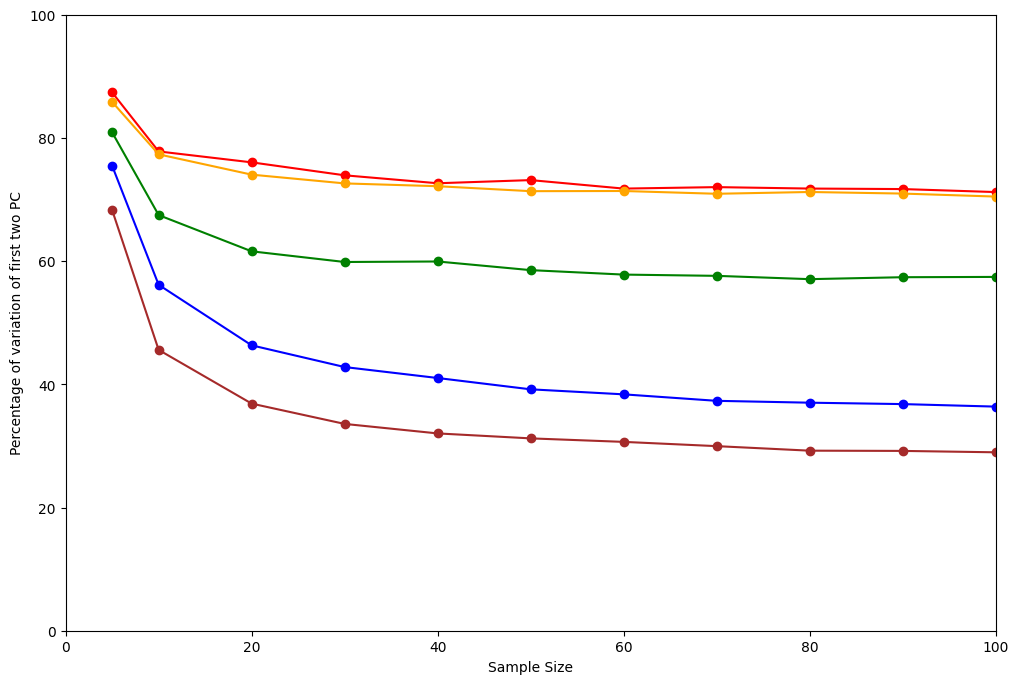

In [9]:
pcaaccuracy = pd.read_csv('../casestudy/mel/melpcanew.csv')
crc_data_val = pcaaccuracy

font = {'weight' : 'bold',
        'size'   : 22}


plt.figure(figsize=(12, 8))
# Plot REAL
plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy'],label='Experimental Train',marker='o', color='red')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min'], crc_data_val['max'], color='red', alpha=0.3)

plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy v'],label='Experimental Validation',marker='o', color='brown')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min v'], crc_data_val['max v'], color='brown', alpha=0.3)


# Plot PP
plt.plot(crc_data_val['Sample Size'], crc_data_val['PP Accuracy'], label='Per-Protein',marker='o', color='blue')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['PP min'], crc_data_val['PP max'], color='blue', alpha=0.3)

# Plot CO
plt.plot(crc_data_val['Sample Size'], crc_data_val['CO Accuracy'], label='Copula',marker='o', color='orange')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['CO min'], crc_data_val['CO max'], color='orange', alpha=0.3)


# Plot TVAE
plt.plot(crc_data_val['Sample Size'], crc_data_val['TVAE Accuracy'], label='TVAE',marker='o', color='green')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['TVAE min'], crc_data_val['TVAE max'], color='green', alpha=0.3)

# Labels and legend
plt.xlabel('Sample Size')
plt.ylabel('Percentage of variation of first two PC')

plt.ylim(0, 100)
plt.xlim(0,100)
plt.show()


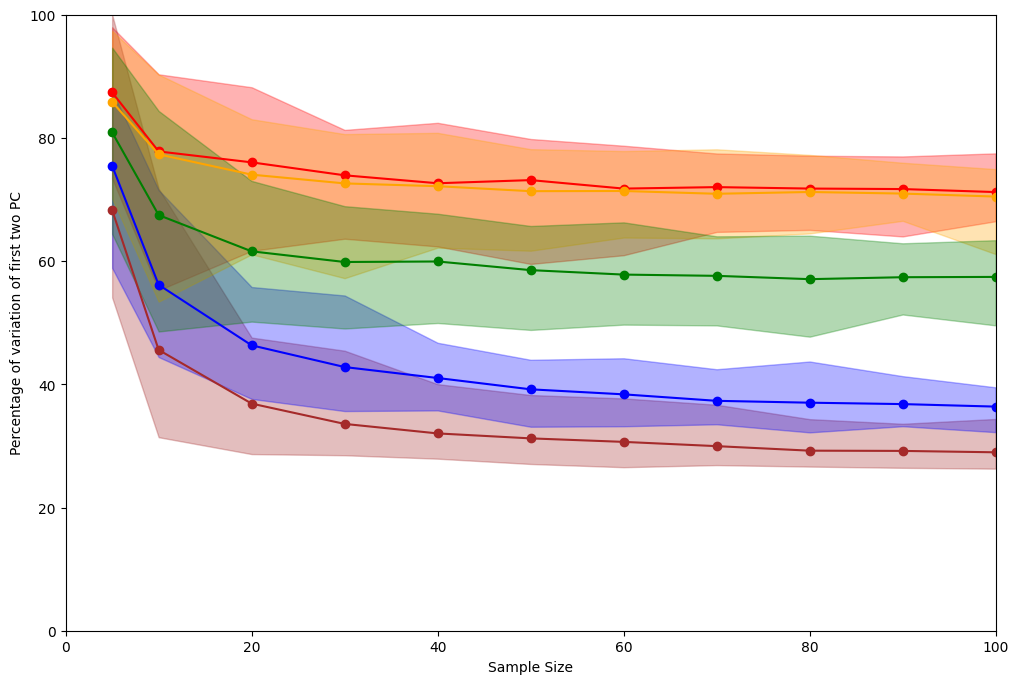

In [10]:

plt.figure(figsize=(12, 8))
# Plot REAL
plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy'],label='Experimental Train',marker='o', color='red')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min'], crc_data_val['max'], color='red', alpha=0.3)

plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy v'],label='Experimental Validation',marker='o', color='brown')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min v'], crc_data_val['max v'], color='brown', alpha=0.3)


# Plot PP
plt.plot(crc_data_val['Sample Size'], crc_data_val['PP Accuracy'], label='Per-Protein',marker='o', color='blue')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['PP min'], crc_data_val['PP max'], color='blue', alpha=0.3)

# Plot CO
plt.plot(crc_data_val['Sample Size'], crc_data_val['CO Accuracy'], label='Copula',marker='o', color='orange')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['CO min'], crc_data_val['CO max'], color='orange', alpha=0.3)


# Plot TVAE
plt.plot(crc_data_val['Sample Size'], crc_data_val['TVAE Accuracy'], label='TVAE',marker='o', color='green')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['TVAE min'], crc_data_val['TVAE max'], color='green', alpha=0.3)

# Labels and legend
plt.xlabel('Sample Size')
plt.ylabel('Percentage of variation of first two PC')

plt.ylim(0, 100)
plt.xlim(0,100)
plt.show()


##### Class Comparison

In [32]:
adjusted_p_values = {}
adjusted_p_values_pp = {}
adjusted_p_values_co = {}
adjusted_p_values_tvae = {}
dicts = {'real_adjust': adjusted_p_values, 'pp_adjust': adjusted_p_values_pp, 'co_adjust': adjusted_p_values_co, 'tvae_adjust': adjusted_p_values_tvae}  # Add more dictionaries as needed

# Load each JSON file and update the corresponding dictionary
for key, value in dicts.items():
    file_path = f'../casestudy/mel/pval/{key}.json'
    with open(file_path, 'r') as json_file:
        value.update(json.load(json_file))
sample_sizes=[5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95,100]

real = []
pp = []
co = []
tvae = []
realmin = []
realmax = []
ppmin = []
ppmax = []
comin = []
comax = []
tvaemin = []
tvaemax = []

col = 'TYB10_HUMAN'

cols = col
for s in sample_sizes:
    s = str(s)
    real.append(np.median(adjusted_p_values[s][col]))
    pp.append(np.median(adjusted_p_values_pp[s][col]))
    co.append(np.median(adjusted_p_values_co[s][col]))
    tvae.append(np.median(adjusted_p_values_tvae[s][col]))
    realmin.append(np.min(adjusted_p_values[s][col]))
    realmax.append(np.max(adjusted_p_values[s][col]))
    ppmin.append(np.min(adjusted_p_values_pp[s][col]))
    ppmax.append(np.max(adjusted_p_values_pp[s][col]))
    comin.append(np.min(adjusted_p_values_co[s][col]))
    comax.append(np.max(adjusted_p_values_co[s][col])) 
    tvaemin.append(np.min(adjusted_p_values_tvae[s][col]))
    tvaemax.append(np.max(adjusted_p_values_tvae[s][col]))

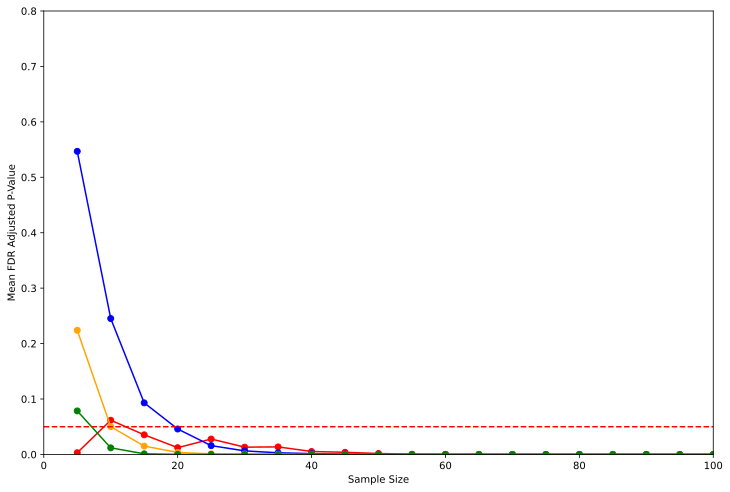

In [34]:
# Plot mean p-value vs sample size for each column
plt.figure(figsize=(12, 8))
font = {'weight' : 'bold',
        'size'   : 22}

plt.plot(sample_sizes, real, marker='o', label='Experimental', color='red', linestyle='-')
# plt.fill_between(sample_sizes, realmin, realmax, color='red', alpha=0.3)

plt.plot(sample_sizes, pp, marker='o', label='Per-Protein', color='blue', linestyle='-')
# plt.fill_between(sample_sizes, ppmin, ppmax, color='blue', alpha=0.3)

plt.plot(sample_sizes, co, marker='o', label='Copula', color='orange', linestyle='-')
# plt.fill_between(sample_sizes, comin, comax, color='orange', alpha=0.3)

plt.plot(sample_sizes, tvae, marker='o', label='TVAE', color='green', linestyle='-')
# plt.fill_between(sample_sizes, tvaemin, tvaemax, color='green', alpha=0.3)

plt.axhline(y=0.05, color='red', linestyle='--')

plt.xlabel('Sample Size')
plt.ylabel('Mean FDR Adjusted P-Value')
plt.ylim(0.0,0.8)
plt.xlim(0,100)
plt.show()

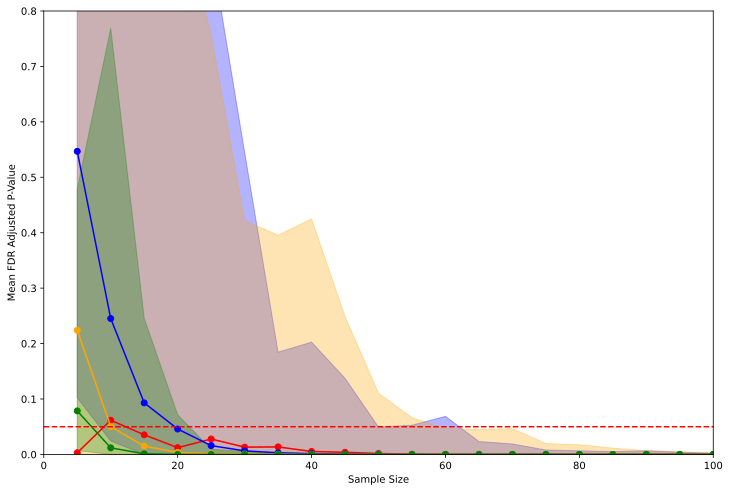

In [35]:
# Plot mean p-value vs sample size for each column
plt.figure(figsize=(12, 8))
font = {'weight' : 'bold',
        'size'   : 22}

plt.plot(sample_sizes, real, marker='o', label='Experimental', color='red', linestyle='-')
plt.fill_between(sample_sizes, realmin, realmax, color='red', alpha=0.3)

plt.plot(sample_sizes, pp, marker='o', label='Per-Protein', color='blue', linestyle='-')
plt.fill_between(sample_sizes, ppmin, ppmax, color='blue', alpha=0.3)

plt.plot(sample_sizes, co, marker='o', label='Copula', color='orange', linestyle='-')
plt.fill_between(sample_sizes, comin, comax, color='orange', alpha=0.3)

plt.plot(sample_sizes, tvae, marker='o', label='TVAE', color='green', linestyle='-')
plt.fill_between(sample_sizes, tvaemin, tvaemax, color='green', alpha=0.3)

plt.axhline(y=0.05, color='red', linestyle='--')

plt.xlabel('Sample Size')
plt.ylabel('Mean FDR Adjusted P-Value')
plt.ylim(0.0,0.8)
plt.xlim(0,100)
plt.show()

## Sample size: correlation-aware (pilot)

Pilot for plan 4.2 (`plans/sample_size.md`). The pilot data are all 628 cells (training + validation), KNN-imputed (k = 5) and centered within condition, so they carry no condition effect. Each simulated experiment draws 2N rows from a pool, adds a log2FC to ceil(π₁ · 124) random proteins in one group, and calls differential abundance with Welch t-tests + BH at FDR 0.05; 500 experiments per (method, log2FC ∈ {0.58, 1}, π₁ ∈ {5, 10, 20%}, N).
Pools: **semi-synthetic benchmark** (the centered cells themselves), **Copula** (20,000 rows from a Gaussian copula fitted to them) and **Copula independence** (same marginals, identity correlation). The **standard calculator** (`analytic_sample_size`, the MSstats `designSampleSize` formula with π₁ as an input) uses the median within-group protein variance.

In [5]:
# Pilot data: all 628 cells (training + validation), KNN-imputed as in the training data
# (k = 5, uniform weights), then each protein centered within its condition (null pool).
from math import ceil
import time
from MSquantSim.power import (center_by_group, within_group_variance, run_experiments,
                              summarize_experiments, analytic_sample_size)
from MSquantSim.simulate import fit_copula, sample_copula

ss_proteins = [c for c in mel_input_raw.columns if c != "Condition"]
ss_imputed = pd.DataFrame(
    KNNImputer(n_neighbors=5, weights="uniform").fit_transform(mel_input_raw[ss_proteins]),
    columns=ss_proteins, index=mel_input_raw.index)
ss_imputed.insert(0, "Condition", mel_input_raw["Condition"].to_numpy())
ss_null = center_by_group(ss_imputed, "Condition")

print("pilot data:", ss_imputed.shape, "| missing values before imputation:",
      int(mel_input_raw[ss_proteins].isna().sum().sum()))
print("cells per condition:", ss_imputed["Condition"].value_counts().to_dict())
print("null pool:", ss_null.shape, "| max |group mean| after centering:",
      float(ss_null.groupby(ss_imputed["Condition"]).mean().abs().max().max()))

pilot data: (628, 125) | missing values before imputation: 10496
cells per condition: {'u': 315, 'm': 313}
null pool: (628, 124) | max |group mean| after centering: 1.5648857870906968e-15


In [6]:
# Pools: semi-synthetic benchmark = the centered cells; Copula (full correlation) and its independence
# ablation (same fitted marginals, identity correlation), each fitted once on the null pool
# and sampled once into a pool of 20,000 rows.
ss_pool_size = 20000
t0 = time.time()
ss_copula_full = fit_copula(ss_null)
ss_copula_ind = fit_copula(ss_null, independent=True)
ss_pools = {
    "benchmark": ss_null[ss_proteins].to_numpy(),
    "copula": sample_copula(ss_copula_full, ss_pool_size, random_state=42)[ss_proteins].to_numpy(),
    "copula_independent": sample_copula(ss_copula_ind, ss_pool_size,
                                        random_state=43)[ss_proteins].to_numpy(),
}
print(f"copula fits + sampling: {time.time() - t0:.0f} s")
for name, pool in ss_pools.items():
    corr = np.corrcoef(pool, rowvar=False)
    print(f"{name:20s} shape={pool.shape}  all finite={np.isfinite(pool).all()}  "
          f"median protein var={np.median(pool.var(axis=0, ddof=1)):.4f}  "
          f"mean off-diagonal corr={corr[np.triu_indices_from(corr, 1)].mean():.3f}")

INFO: [2026-10-08 13:33:53] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


INFO: [2026-10-08 13:34:14] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


copula fits + sampling: 836 s
plasmode             shape=(628, 124)  all finite=True  median protein var=0.8741  mean off-diagonal corr=0.566
copula               shape=(20000, 124)  all finite=True  median protein var=0.9111  mean off-diagonal corr=0.560
copula_independent   shape=(20000, 124)  all finite=True  median protein var=0.9224  mean off-diagonal corr=0.000


In [7]:
# Grid of simulated experiments: 500 per (method, log2FC, pi1, N), each cell with its own
# seeded rng. All experiment rows and the per-cell summaries are saved.
ss_n_grid = [3, 5, 8, 10, 15, 20, 25, 30, 40, 50, 75, 100]
ss_pi1_grid = [0.05, 0.10, 0.20]
ss_log2fc_grid = [0.58, 1.0]
ss_n_experiments = 500
ss_fdr = 0.05
ss_methods = list(ss_pools)
ss_p = len(ss_proteins)
ss_design_cols = ["method", "log2fc", "pi1", "n_changed", "n_per_group"]

t0 = time.time()
ss_experiments, ss_summary = [], []
for mi, method in enumerate(ss_methods):
    for fi, log2fc in enumerate(ss_log2fc_grid):
        for pj, pi1 in enumerate(ss_pi1_grid):
            n_changed = ceil(pi1 * ss_p)
            for ni, n in enumerate(ss_n_grid):
                rng = np.random.default_rng([42, mi, fi, pj, ni])
                exps, _ = run_experiments(ss_pools[method], n, n_changed, log2fc,
                                          ss_n_experiments, rng, fdr=ss_fdr)
                design = dict(method=method, log2fc=log2fc, pi1=pi1,
                              n_changed=n_changed, n_per_group=n)
                ss_experiments.append(exps.assign(experiment=np.arange(len(exps)), **design))
                ss_summary.append({**design, **summarize_experiments(exps).to_dict()})
    print(f"{method}: done ({time.time() - t0:.0f} s)")

ss_experiments = pd.concat(ss_experiments, ignore_index=True)[
    ss_design_cols + ["experiment", "tp", "fp", "discoveries", "power", "fdp"]]
ss_summary = pd.DataFrame(ss_summary)
ss_experiments.to_csv("../data/results/MEL/sample_size_experiments.csv", index=False)
ss_summary.to_csv("../data/results/MEL/sample_size_summary.csv", index=False)
print("experiments:", ss_experiments.shape, "| summary:", ss_summary.shape)

plasmode: done (16 s)


copula: done (33 s)


copula_independent: done (51 s)


experiments: (108000, 11) | summary: (216, 11)


In [8]:
# Standard independence calculator (MSstats designSampleSize formula, pi1 as an input):
# one "representative protein" with the median within-group variance of the pilot data.
ss_variance = within_group_variance(ss_imputed, "Condition")
ss_median_variance = float(ss_variance.median())
ss_calculator = []
for log2fc in ss_log2fc_grid:
    for pi1 in ss_pi1_grid:
        n_calc, alpha = analytic_sample_size(ss_median_variance, log2fc, pi1,
                                             fdr=ss_fdr, power=0.8)
        ss_calculator.append(dict(log2fc=log2fc, pi1=pi1, n_calculator=n_calc,
                                  alpha=alpha, median_variance=ss_median_variance))
ss_calculator = pd.DataFrame(ss_calculator)
ss_calculator.to_csv("../data/results/MEL/sample_size_calculator.csv", index=False)
ss_calculator

,log2fc,pi1,n_calculator,alpha,median_variance
0,0.58,0.05,80,0.002100,0.875528
1,0.58,0.10,72,0.004188,0.875528
2,0.58,0.20,64,0.008333,0.875528
3,1.00,0.05,27,0.002100,0.875528
4,1.00,0.10,25,0.004188,0.875528
5,1.00,0.20,22,0.008333,0.875528


In [9]:
# Per-protein detection (log2FC = 1, pi1 = 10%): six proteins at the 5th-98th percentiles of
# within-group variance are changed in every experiment (the other changed slots are random);
# detection rate per protein and N for semi-synthetic benchmark and Copula (full correlation).
pp_log2fc, pp_pi1 = 1.0, 0.10
pp_n_changed = ceil(pp_pi1 * ss_p)
pp_percentiles = [5, 25, 45, 65, 85, 98]
ss_var_sorted = ss_variance[ss_proteins].sort_values()
pp_proteins = [ss_var_sorted.index[int(round(q / 100 * (ss_p - 1)))] for q in pp_percentiles]
pp_idx = [ss_proteins.index(prot) for prot in pp_proteins]

pp_detection = []
for mi, method in enumerate(["benchmark", "copula"]):
    for ni, n in enumerate(ss_n_grid):
        rng = np.random.default_rng([4206, mi, ni])
        _, detected = run_experiments(ss_pools[method], n, pp_n_changed, pp_log2fc,
                                      ss_n_experiments, rng, fdr=ss_fdr, always_changed=pp_idx)
        for idx, prot in zip(pp_idx, pp_proteins):
            pp_detection.append(dict(method=method, protein=prot, n_per_group=n,
                                     detection_rate=float(detected[idx].mean())))
pp_detection = pd.DataFrame(pp_detection)
pp_detection.to_csv("../data/results/MEL/sample_size_protein_detection.csv", index=False)

pp_n_rep, _ = analytic_sample_size(ss_median_variance, pp_log2fc, pp_pi1, fdr=ss_fdr, power=0.8)
pp_calculator = []
for q, prot in zip(pp_percentiles, pp_proteins):
    n_prot, alpha = analytic_sample_size(ss_variance[prot], pp_log2fc, pp_pi1,
                                         fdr=ss_fdr, power=0.8)
    pp_calculator.append(dict(protein=prot, variance_percentile=q,
                              within_group_variance=float(ss_variance[prot]),
                              n_protein_calculator=n_prot, n_representative=pp_n_rep,
                              alpha=alpha))
pp_calculator = pd.DataFrame(pp_calculator)
pp_calculator.to_csv("../data/results/MEL/sample_size_protein_calculator.csv", index=False)

# smallest N at which each protein is detected in >= 80% of experiments
pp_n80 = (pp_detection[pp_detection["detection_rate"] >= 0.8]
          .groupby(["protein", "method"])["n_per_group"].min().unstack())
print(pp_detection.shape, pp_calculator.shape)
pp_calculator.set_index("protein").join(pp_n80)

(144, 4) (6, 6)


,variance_percentile,within_group_variance,n_protein_calculator,n_representative,alpha,copula,plasmode
protein,,,,,,,
GLS,5,0.593078,17,25,0.004188,25,25
MACROH2A1,25,0.754982,21,25,0.004188,30,30
HNRNPD,45,0.858483,24,25,0.004188,30,30
SOD1,65,0.960218,27,25,0.004188,40,30
NPM1,85,1.107372,31,25,0.004188,40,40
GLUL,98,1.915502,53,25,0.004188,75,75


            mean_power                             p_power_ge_target                             fdp_q95                            
method          copula copula_independent plasmode            copula copula_independent plasmode  copula copula_independent plasmode
n_per_group                                                                                                                         
3                0.001              0.001    0.003             0.000              0.000    0.000   0.000              0.000    0.000
5                0.017              0.006    0.018             0.004              0.000    0.004   0.000              0.000    0.000
8                0.082              0.049    0.077             0.020              0.000    0.020   0.000              0.250    0.100
10               0.147              0.108    0.141             0.046              0.000    0.046   0.112              0.333    0.200
15               0.356              0.348    0.375             0.152 

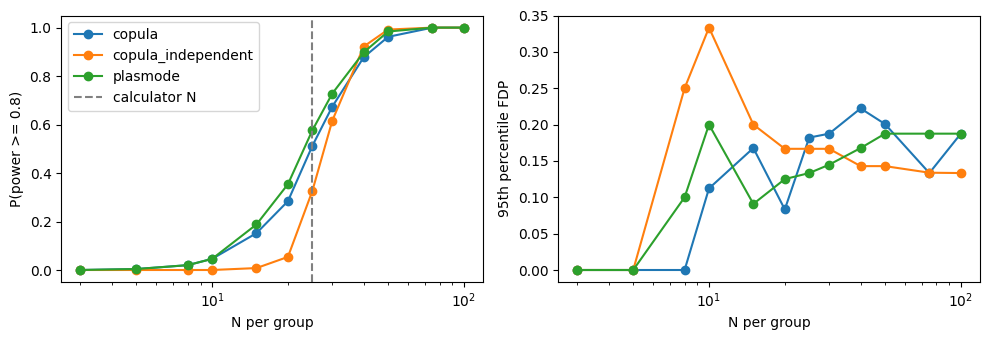

In [10]:
# Sanity check (main-text setting log2FC = 1, pi1 = 10%): mean power, P(power >= 80%) and
# FDP spread per method and N; N80 = smallest N with P(power >= 80%) >= 0.8.
sel = ss_summary[(ss_summary["log2fc"] == 1.0) & (ss_summary["pi1"] == 0.10)]
print(sel.pivot(index="n_per_group", columns="method",
                values=["mean_power", "p_power_ge_target", "fdp_q95"]).round(3).to_string())

def first_n(df, col, thr=0.8):
    hit = df.loc[df[col] >= thr, "n_per_group"]
    return int(hit.min()) if len(hit) else np.nan

ss_n80 = pd.DataFrame([
    dict(method=m, log2fc=f, pi1=p,
         n_mean_power_80=first_n(g, "mean_power"), N80=first_n(g, "p_power_ge_target"))
    for (m, f, p), g in ss_summary.groupby(["method", "log2fc", "pi1"])])
print(ss_n80.merge(ss_calculator[["log2fc", "pi1", "n_calculator"]], on=["log2fc", "pi1"])
      .sort_values(["log2fc", "pi1", "method"]).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for method, g in sel.groupby("method"):
    ax[0].plot(g["n_per_group"], g["p_power_ge_target"], marker="o", label=method)
    ax[1].plot(g["n_per_group"], g["fdp_q95"], marker="o", label=method)
n_calc = ss_calculator.query("log2fc == 1.0 and pi1 == 0.10")["n_calculator"].iloc[0]
ax[0].axvline(n_calc, color="grey", ls="--", label="calculator N")
ax[0].set(xscale="log", xlabel="N per group", ylabel="P(power >= 0.8)")
ax[1].set(xscale="log", xlabel="N per group", ylabel="95th percentile FDP")
ax[0].legend()
plt.tight_layout()
plt.show()

## Missing values: KNN imputation before simulation

Plan 3.5 (`plans/missing_values.md`). Start from the complete (KNN-imputed) training data of each group (monocyte = healthy, melanoma = disease). Missing values are introduced with the MNAR detection curve fitted above (`mnar_params`), its intercept shifted by `calibrate_offsets` so that the expected missing rate is 0, 10, 20, 30 or 40%. The masked data are KNN-imputed (k = 5, as for the training data), Copula, Per-protein and TVAE are trained on the imputed data, and 10 datasets of the group's size are simulated from each. S_corr = Pearson correlation between the upper triangles of a correlation matrix and that of the **complete** experimental data. The helper functions in the next cell are also used by the limited-training-data section.

> **Not used in the paper (Devon, 2026-10-08):** the missing-values section was dropped from the manuscript and supplementary. The code and results are kept for reference only.

In [11]:
# Mask -> KNN-impute -> train -> simulate, one task per group and target missing rate
# (tasks run in parallel; every random step is seeded, so results do not depend on n_jobs).
from joblib import Parallel, delayed

mv_groups = {"healthy": ("u", mel_healthy), "disease": ("m", mel_disease)}
mv_rates = [0, 0.10, 0.20, 0.30, 0.40]
mv_n_sims = 10
mv_a, mv_b = mnar_params


def mv_task(group, gi, label, complete, proteins, rate, ri):
    n_cells = len(complete)
    level = f"r{int(round(rate * 100))}"
    with_condition = complete.assign(Condition=label)
    offsets = calibrate_offsets(with_condition, mv_a, mv_b, rate)
    masked = apply_dropout(with_condition, mv_a, mv_b, offsets=offsets,
                           rng=np.random.default_rng([35, gi, ri]))
    masked = masked.drop(columns=["Condition"])
    realized = float(masked.isna().to_numpy().mean())
    imputed = knn_impute(masked)

    seed = 3500 + 10 * gi + ri
    copula = fit_copula(imputed)
    pp_params = fit_per_protein(imputed)
    pp_rng = np.random.default_rng([3501, gi, ri])
    tvae = fit_tvae(imputed, seed)
    sims = {
        "Copula": [sample_copula(copula, n_cells, random_state=100 * seed + s)
                   for s in range(mv_n_sims)],
        "Per-protein": [sample_per_protein(pp_params, n_cells, rng=pp_rng)
                        for _ in range(mv_n_sims)],
        "TVAE": [tvae.sample(num_rows=n_cells) for _ in range(mv_n_sims)],
    }

    complete_corr = complete[proteins].corr().to_numpy()
    imputed_corr = imputed[proteins].corr().to_numpy()
    corrs = {f"{group}__{level}__Experimental": complete_corr,
             f"{group}__{level}__Imputed": imputed_corr}
    base = dict(group=group, target_rate=rate, realized_rate=realized)
    scores = [dict(**base, source="Imputed", sim=0, s_corr=s_corr(imputed_corr, complete_corr))]
    for source, sim_list in sims.items():
        for s, sim in enumerate(sim_list):
            corr = sim[proteins].corr().to_numpy()
            if s == 0:
                corrs[f"{group}__{level}__{source}"] = corr
            scores.append(dict(**base, source=source, sim=s, s_corr=s_corr(corr, complete_corr)))
    return corrs, scores


mv_corrs, mv_tasks = {}, []
for gi, (group, (label, group_df)) in enumerate(mv_groups.items()):
    complete = group_df.drop(columns=["Condition"], errors="ignore")
    proteins = cluster_order(complete)   # one protein order for every level and source
    mv_corrs[f"{group}__proteins"] = np.array(proteins)
    for ri, rate in enumerate(mv_rates):
        mv_tasks.append(delayed(mv_task)(group, gi, label, complete, proteins, rate, ri))

t0 = time.time()
mv_results = Parallel(n_jobs=len(mv_tasks))(mv_tasks)
print(f"{len(mv_tasks)} tasks in {time.time() - t0:.0f} s")

mv_scores = []
for corrs, scores in mv_results:
    mv_corrs.update(corrs)
    mv_scores.extend(scores)
mv_scores = pd.DataFrame(mv_scores)
np.savez_compressed("../data/results/MEL/missingness_correlations.npz", **mv_corrs)
mv_scores.to_csv("../data/results/MEL/missingness_scores.csv", index=False)
print(len(mv_corrs), "arrays |", mv_scores.shape)
print(mv_scores.groupby(["group", "target_rate"])["realized_rate"].first().round(4).to_string())

10 tasks in 53 s
52 arrays | (310, 6)
group    target_rate
disease  0.0            0.0000
         0.1            0.1012
         0.2            0.2002
         0.3            0.2997
         0.4            0.4052
healthy  0.0            0.0000
         0.1            0.0961
         0.2            0.1974
         0.3            0.2970
         0.4            0.3964


source                             Imputed  Copula  Per-protein   TVAE
group   target_rate realized_rate                                     
disease 0.0         0.000000         1.000   0.939        0.007  0.396
        0.1         0.101194         0.991   0.942        0.001  0.304
        0.2         0.200194         0.978   0.917       -0.002  0.283
        0.3         0.299677         0.963   0.907        0.005  0.370
        0.4         0.405194         0.944   0.890       -0.008  0.288
healthy 0.0         0.000000         1.000   0.951        0.007  0.253
        0.1         0.096134         0.993   0.946       -0.001  0.350
        0.2         0.197421         0.983   0.928        0.001  0.279
        0.3         0.297011         0.973   0.927       -0.004  0.267
        0.4         0.396441         0.948   0.903        0.003  0.310


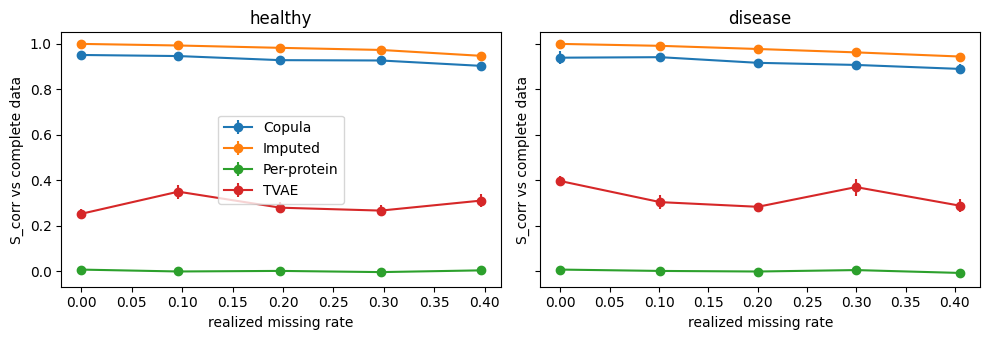

In [12]:
# Mean S_corr (vs complete data) per group, missing rate and source; sanity plot.
mv_mean = (mv_scores.groupby(["group", "target_rate", "realized_rate", "source"])["s_corr"]
           .mean().unstack("source")[["Imputed", "Copula", "Per-protein", "TVAE"]])
print(mv_mean.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for a, (group, g) in zip(ax, mv_scores.groupby("group", sort=False)):
    m = g.groupby(["realized_rate", "source"])["s_corr"].agg(["mean", "std"]).reset_index()
    for source, gs in m.groupby("source"):
        a.errorbar(gs["realized_rate"], gs["mean"], yerr=gs["std"], marker="o", label=source)
    a.set(title=group, xlabel="realized missing rate", ylabel="S_corr vs complete data")
ax[0].legend()
plt.tight_layout()
plt.show()

## Sample size: seed-protein design (4.2)

MEL run of the plan 4.2 seed-protein design (`plans/sample_size.md`, "Redesign: PDAC-DIA seed proteins", "Devon's review" and "MEL run of the same design"; Devon, 2026-10-16: "also run this using the MEL dataset"). Empirical $t$-test power and false discovery proportion (FDP) when the truly changed proteins follow the correlation structure of the data (a changed protein drags its correlated partners along), against the independence planner's fixed 5% of proteins changed at random.

- Data: the 4.2 pilot null (cell 184): all 628 cells (315 u, 313 m; training + validation), the 124 proteins of the INDRA component (cell 8), KNN-imputed (k = 5) as `ss_imputed`, then each protein centered within condition (`ss_null`). No cells are dropped; per-cell missingness before imputation is reported in Step 0.
- Pools (cell 185, unchanged): **benchmark** (semi-synthetic: the 628 centered cells), **copula** (20,000 rows from a Gaussian copula fitted to them, random_state 42) and **copula_independent** (same fitted marginals, identity correlation; 20,000 rows, random_state 43).
- Changed proteins (benchmark and copula): each experiment draws 2 seed proteins at random; partners come from the Pearson correlation of `ss_null` (columns in pool order), positive correlations only (`MSquantSim.power.seed_changed_sets`).
  - Rule A (top-m): each seed adds its 2 most positively correlated proteins not already in the set (6 changed proteins, the same number as the random arm).
  - Rule B (threshold): each seed adds every protein with r ≥ 0.5, at most the 15 strongest (up to 32 changed proteins; the size varies).
- copula_independent does not use the seed sets: each run changes a fixed 6 of 124 proteins (5%, the independence planner's assumption), drawn uniformly at random without replacement, a new set per run.
- Pairing: for each (rule, N) the 500 seed sets are drawn once (`default_rng([5207, rule, N])`) and shared by both log2FC values, the benchmark and the copula. For each N the 500 random sets of copula_independent are drawn once (`default_rng([5208, N])`) and shared by both log2FC values and both rules (its rows are written under rule A and rule B, with the same sets). Each (rule, log2FC, N, pool) draws its rows from its own generator (`default_rng([5209, rule, log2FC, N, pool])`; indices into the grids).
- Experiments: 2N rows per experiment, log2FC ∈ {0.58, 1} added to the changed set in one group, Welch $t$-tests + BH at FDR 0.05; N per group ∈ {3, 5, 8, 10, 15, 20, 25, 30, 40, 50, 75, 100}; 500 experiments per (rule, log2FC, N, pool). The benchmark pool has 628 rows, so even N = 100 (200 rows) leaves room between experiments.
- Standard calculator: `analytic_sample_size` (MSstats `designSampleSize` formula) with the median within-group variance of the 124 proteins on the imputed 628-cell data; π₁ = 6/124 for both rules.
- Step 0 checks the premise (proteins correlated with a changed protein tend to change too) with the real labels (u vs m). About 115 of the 124 proteins differ between conditions, so the base rate is near 1 and the check is expected to be uninformative; it is run and reported anyway.
- Outputs: `../data/results/MEL/sample_size_seed_{premise,experiments,summary,sets,calculator}.csv` (new files; the pilot's `sample_size_*.csv` are not touched).
- To reproduce, run only the upstream cells the pilot data need (imports, data loading, missing-value filter, INDRA component), the pilot's data and pool cells, and this section: `run_cells.py MEL_case_study.ipynb 2,5,7-8,184-185,193-203` (cell numbers as of 2026-10-21, after the reorder; about 15 min, mostly Copula sampling in cell 185). Do not add cells 186 or 188: they overwrite the pilot's result files.
  - Headless on macOS, run it as `env -u USER python ../../plans/tools/run_cells.py ...`: cell 2 opens a Neo4j client with `$USER`, and the shell's `USER` otherwise shadows the project `.env` value (run_cells loads `.env` with `setdefault`), so cell 2 fails with an authentication error. The client is not used by this section.

### Step 0: missingness and premise check with the real labels

- **Missingness per cell before imputation** (report only, no cells dropped): share of missing values over the 124 analyzed proteins (`mel_input_raw` after cells 7–8) and over every unambiguous protein group of the raw file; median, 95th percentile, maximum, and the cells above 50%.
- **Premise:** D = proteins differentially abundant between u and m (Welch $t$-test on the imputed 628-cell data `ss_imputed`, BH at FDR 0.05). For three within-group correlation matrices, the centered data (all 628 cells, the matrix the seed partners come from) and each condition alone (u only, m only):
  - share of D among the top-3 positive partners of D proteins vs of non-D proteins, vs the base rate |D| / 124;
  - P(protein ∈ D | it has r ≥ 0.5 with some other D protein), vs proteins without such a link;
  - permutation baseline: 1,000 random sets of size |D| (seeded);
  - correlation noise: off-diagonal r quantiles, per-protein maximum r, partners at r ≥ 0.5 (quantiles, share of proteins with none), and the chance level from the same data with each column permuted independently once.

In [7]:
# Step 0: per-cell missingness before imputation (report only), then the premise check with the
# real labels (u vs m): enrichment of D among the correlation partners of D proteins
import time
from MSquantSim.power import (center_by_group, within_group_variance, welch_pvalues,
                              seed_changed_sets, run_experiments, summarize_experiments,
                              analytic_sample_size)
from MSquantSim.downstreamanalysis import _bh_adjust

seed_fdr = 0.05
seed_prots = list(ss_proteins)
seed_p = len(seed_prots)
assert list(ss_null.columns) == seed_prots and ss_null.shape == (628, 124)
assert ss_imputed[seed_prots].notna().all().all()

# Missing share per cell before imputation: the 124 analyzed proteins, and every unambiguous
# protein group of the raw file (Run and Channel identify the cell)
seed_raw = pd.read_csv('../data/mel/MEL_protein_level_data.csv')
assert seed_raw.index.equals(mel_input_raw.index) and seed_raw["Condition"].equals(mel_input_raw["Condition"])
seed_raw_prots = [c for c in seed_raw.columns if ";" not in c and c not in ("Run", "Channel", "Condition")]
seed_missing = pd.DataFrame({"Run": seed_raw["Run"], "Channel": seed_raw["Channel"],
                             "Condition": seed_raw["Condition"],
                             "panel": mel_input_raw[seed_prots].isna().mean(axis=1),
                             "raw_file": seed_raw[seed_raw_prots].isna().mean(axis=1)})
premise_rows = []
for scope, n_cols in {"panel": seed_p, "raw_file": len(seed_raw_prots)}.items():
    m = seed_missing[scope]
    print(f"missing per cell, {scope} ({n_cols} proteins): median {m.median():.1%}, "
          f"q95 {m.quantile(0.95):.1%}, max {m.max():.1%}; cells > 50%: {int((m > 0.5).sum())} of {len(m)}")
    premise_rows += [(f"missingness_{scope}", "n_proteins", n_cols, len(m)),
                     (f"missingness_{scope}", "cell_missing_median", m.median(), len(m)),
                     (f"missingness_{scope}", "cell_missing_q95", m.quantile(0.95), len(m)),
                     (f"missingness_{scope}", "cell_missing_max", m.max(), len(m)),
                     (f"missingness_{scope}", "n_cells_gt_0.5", int((m > 0.5).sum()), len(m))]
print("most-missing cells (panel):")
display(seed_missing.sort_values("panel", ascending=False).head(5).round(3))


def top_partners(corr, m=3):
    """Each protein's m most positively correlated other proteins (ranked as in rule A)."""
    c = np.where(np.isfinite(corr), corr, -np.inf)
    np.fill_diagonal(c, -np.inf)
    ranked = np.argsort(-c, axis=1)[:, :m]
    return ranked, np.take_along_axis(c, ranked, axis=1) > 0   # partners, and whether r > 0


def top_share(ranked, positive, members, of):
    """Share of members among the positive top partners of the proteins in `of`; pair count."""
    partners = ranked[of][positive[of]]
    return (members[partners].mean() if len(partners) else np.nan), len(partners)


def linked_share(strong, members):
    """P(protein in members | strong link to some OTHER member), count linked, and P(in members | no link)."""
    linked = strong[:, members].any(axis=1)
    return ((members[linked].mean() if linked.any() else np.nan), int(linked.sum()),
            (members[~linked].mean() if (~linked).any() else np.nan))


def premise_metrics(data, in_D, seeds, n_perm=1000):
    """Enrichment, permutation baseline and correlation noise for one (samples x proteins) matrix."""
    p, n_D = data.shape[1], int(in_D.sum())
    corr = np.corrcoef(data, rowvar=False)
    ranked, positive = top_partners(corr)
    strong = corr >= 0.5
    np.fill_diagonal(strong, False)

    # Enrichment, observed
    share_D, n_pairs_D = top_share(ranked, positive, in_D, in_D)
    share_nonD, n_pairs_nonD = top_share(ranked, positive, in_D, ~in_D)
    link_D, n_linked, unlinked_D = linked_share(strong, in_D)
    any_link = strong.any(axis=1)
    rows = [("n_samples_matrix", data.shape[0], np.nan),
            ("top3_share_D_among_partners_of_D", share_D, n_pairs_D),
            ("top3_share_D_among_partners_of_nonD", share_nonD, n_pairs_nonD),
            ("r05_P_D_given_link_to_other_D", link_D, n_linked),
            ("r05_P_D_given_no_link_to_D", unlinked_D, p - n_linked),
            ("r05_P_D_given_any_link", in_D[any_link].mean() if any_link.any() else np.nan,
             int(any_link.sum()))]

    # Permutation baseline: random sets of the same size as D
    rng = np.random.default_rng([5200, *seeds])
    perm_top, perm_link = np.empty(n_perm), np.empty(n_perm)
    for b in range(n_perm):
        members = np.zeros(p, dtype=bool)
        members[rng.choice(p, n_D, replace=False)] = True
        perm_top[b] = top_share(ranked, positive, members, members)[0]
        perm_link[b] = linked_share(strong, members)[0]
    rows += [("top3_perm_mean", perm_top.mean(), n_perm),
             ("top3_perm_q95", np.quantile(perm_top, 0.95), n_perm),
             ("top3_perm_p", (1 + (perm_top >= share_D).sum()) / (1 + n_perm), n_perm),
             ("r05_perm_mean", np.nanmean(perm_link), n_perm),
             ("r05_perm_q95", np.nanquantile(perm_link, 0.95), n_perm),
             ("r05_perm_p", (1 + (perm_link >= link_D).sum()) / (1 + n_perm), n_perm)]

    # Correlation noise
    off = corr[np.triu_indices(p, 1)]
    c = corr.copy()
    np.fill_diagonal(c, np.nan)
    max_r = np.nanmax(c, axis=1)
    n_partners = strong.sum(axis=1)
    rows += [(f"offdiag_r_q{q:g}", np.quantile(off, q), len(off))
             for q in [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]]
    rows += [("offdiag_r_mean", off.mean(), len(off)),
             ("n_pairs_r05", int((off >= 0.5).sum()), len(off))]
    rows += [(f"max_r_per_protein_q{q:g}", np.quantile(max_r, q), p) for q in [0.05, 0.25, 0.5, 0.75, 0.95]]
    rows += [(f"n_partners_r05_q{q:g}", np.quantile(n_partners, q), p) for q in [0.25, 0.5, 0.75, 0.95]]
    rows += [("n_partners_r05_max", n_partners.max(), p),
             ("share_proteins_0_partners_r05", (n_partners == 0).mean(), p)]

    # Chance level: each column permuted independently once (no correlation left)
    rng = np.random.default_rng([5201, *seeds])
    chance = np.corrcoef(np.column_stack([rng.permutation(col) for col in data.T]), rowvar=False)
    np.fill_diagonal(chance, np.nan)
    chance_max_r, chance_max_abs = np.nanmax(chance, axis=1), np.nanmax(np.abs(chance), axis=1)
    rows += [("chance_max_r_per_protein_q0.5", np.median(chance_max_r), p),
             ("chance_max_r_per_protein_q0.95", np.quantile(chance_max_r, 0.95), p),
             ("chance_max_abs_r_per_protein_q0.5", np.median(chance_max_abs), p),
             ("chance_max_abs_r_per_protein_q0.95", np.quantile(chance_max_abs, 0.95), p),
             ("chance_max_abs_r_overall", np.nanmax(np.abs(chance)), p),
             ("chance_share_proteins_with_partner_r05", (chance >= 0.5).any(axis=1).mean(), p)]
    return rows


# D from the real labels on the imputed 628-cell data (u = group 1, m = group 2)
is_m = (ss_imputed["Condition"] == "m").to_numpy()
seed_X = ss_imputed[seed_prots].to_numpy(dtype=float)
seed_in_D = _bh_adjust(welch_pvalues(seed_X[~is_m], seed_X[is_m])) < seed_fdr
print(f"|D| = {seed_in_D.sum()} of {seed_p} proteins (BH {seed_fdr}); base rate {seed_in_D.mean():.3f}; "
      f"non-D: {[seed_prots[i] for i in np.flatnonzero(~seed_in_D)]}")
premise_rows += [("labels", "n_samples", len(ss_imputed), np.nan),
                 ("labels", "n_D", int(seed_in_D.sum()), seed_p),
                 ("labels", "base_rate", seed_in_D.mean(), seed_p)]
seed_matrices = {"centered_all": ss_null[seed_prots].to_numpy(dtype=float),
                 "u_only": seed_X[~is_m], "m_only": seed_X[is_m]}
for mi, (matrix, data) in enumerate(seed_matrices.items()):
    premise_rows += [(matrix, metric, value, n)
                     for metric, value, n in premise_metrics(data, seed_in_D, (mi,))]

seed_premise = pd.DataFrame(premise_rows, columns=["matrix", "metric", "value", "n"])
seed_premise.to_csv("../data/results/MEL/sample_size_seed_premise.csv", index=False)
with pd.option_context("display.max_rows", 200):
    display(seed_premise[seed_premise["matrix"].isin(seed_matrices)]
            .pivot_table(index="metric", columns="matrix", values="value", sort=False, dropna=False)
            [list(seed_matrices)].round(3))

# Partners for the seed sets: Pearson correlation of the centered 628-cell null, pool column order
seed_corr = np.corrcoef(ss_null[seed_prots].to_numpy(dtype=float), rowvar=False)

missing per cell, panel (124 proteins): median 7.3%, q95 89.5%, max 98.4%; cells > 50%: 39 of 628
missing per cell, raw_file (3139 proteins): median 58.7%, q95 96.1%, max 99.6%; cells > 50%: 628 of 628
most-missing cells (panel):


,Run,Channel,Condition,panel,raw_file
605,eAL00265,channel14,m,0.984,0.989
608,eAL00265,channel17,m,0.984,0.991
611,eAL00265,channel6,u,0.984,0.992
579,eAL00263,channel14,m,0.984,0.987
585,eAL00263,channel6,u,0.984,0.984


|D| = 116 of 124 proteins (BH 0.05); base rate 0.935; non-D: ['SOD1', 'ELANE', 'MMP3', 'LGALS1', 'RAC1', 'LYAR', 'USP14', 'DIABLO']


matrix,centered_all,u_only,m_only
metric,,,
n_samples_matrix,628.000,315.000,313.000
top3_share_D_among_partners_of_D,1.000,1.000,0.991
top3_share_D_among_partners_of_nonD,0.875,0.917,0.875
r05_P_D_given_link_to_other_D,0.950,0.950,0.943
r05_P_D_given_no_link_to_D,0.500,0.500,0.500
r05_P_D_given_any_link,0.950,0.950,0.943
top3_perm_mean,0.937,0.936,0.933
top3_perm_q95,0.994,0.994,0.994
top3_perm_p,0.019,0.009,0.094


### Pools

The three pools of cell 185 (columns in `ss_proteins` order). Checks: non-finite values (the section stops if there are any), median protein SD, max |value| and the number of values (and proteins) beyond the benchmark's max |value| (heavy Copula marginals, R10 in `plans/text_code_discrepancies.md`), mean off-diagonal correlation, agreement of each pool's correlation with the benchmark's, and the mean correlation over the top-2 partner pairs that rule A uses.

In [8]:
# Pool checks: benchmark = the 628 centered cells; copula and copula_independent = the 20,000-row
# pools of cell 185 (random_state 42 and 43)
seed_pools = ss_pools
seed_methods = list(seed_pools)   # benchmark, copula, copula_independent
assert seed_methods == ["benchmark", "copula", "copula_independent"]
assert np.array_equal(seed_pools["benchmark"], ss_null[seed_prots].to_numpy())

seed_top2, seed_top2_pos = top_partners(seed_corr, m=2)
seed_pair_i = np.repeat(np.arange(seed_p), 2)[seed_top2_pos.ravel()]
seed_pair_j = seed_top2.ravel()[seed_top2_pos.ravel()]
seed_iu = np.triu_indices(seed_p, 1)
seed_benchmark_max = np.abs(seed_pools["benchmark"]).max()
seed_pool_check = []
for pool_name, pool_values in seed_pools.items():
    finite = np.isfinite(pool_values)
    beyond = np.abs(np.where(finite, pool_values, 0)) > seed_benchmark_max
    check = dict(pool=pool_name, rows=pool_values.shape[0], proteins=pool_values.shape[1],
                 non_finite=int((~finite).sum()),
                 median_sd=np.median(np.nanstd(np.where(finite, pool_values, np.nan), axis=0, ddof=1)),
                 max_abs_value=np.abs(pool_values[finite]).max(),
                 n_beyond_benchmark_max=int(beyond.sum()),
                 n_proteins_beyond_benchmark_max=int(beyond.any(axis=0).sum()))
    if finite.all():
        pool_corr = np.corrcoef(pool_values, rowvar=False)
        check.update(mean_offdiag_r=pool_corr[seed_iu].mean(),
                     r_vs_benchmark_corr=np.corrcoef(pool_corr[seed_iu], seed_corr[seed_iu])[0, 1],
                     mean_r_top2_pairs=pool_corr[seed_pair_i, seed_pair_j].mean())
    seed_pool_check.append(check)
seed_pool_check = pd.DataFrame(seed_pool_check).set_index("pool")
print(f"benchmark max |value|: {seed_benchmark_max:.3f}")
display(seed_pool_check.round(4))
assert seed_pool_check["non_finite"].eq(0).all(), "non-finite values in a pool: stop and report"

benchmark max |value|: 9.266


,rows,proteins,non_finite,median_sd,max_abs_value,n_beyond_benchmark_max,n_proteins_beyond_benchmark_max,mean_offdiag_r,r_vs_benchmark_corr,mean_r_top2_pairs
pool,,,,,,,,,,
benchmark,628,124,0,0.9350,9.2657,0,0,0.5657,1.0000,0.7243
copula,20000,124,0,0.9545,103.6731,95,15,0.5604,0.9864,0.7028
copula_independent,20000,124,0,0.9604,64.5693,94,14,0.0000,0.0194,0.0004


### Changed sets and experiments

Devon, 2026-10-16: the correlation-removed Copula uses a fixed 5% of proteins (6 of 124) changed at random, the independence planner's assumption; the benchmark and Copula use the seed sets (rule A: 2 seeds + top-2 partners each = 6; rule B: 2 seeds + every partner with r ≥ 0.5, at most 15 each).

`seed_partner_links` re-derives which seed added each partner (same selection as `seed_changed_sets`, checked against its output) to record each partner's correlation to its seed (rule B: the strongest seed that selected it). Seeds: seed sets `[5207, rule, N]`, random sets of copula_independent `[5208, N]`, rows `[5209, rule, log2FC, N, pool]` (indices into the grids). `sample_size_seed_sets.csv` holds both: the seed sets under rule A and B, and the random sets under rule = "random" (seeds empty, partner columns NaN); copula_independent rows of either rule use the random set with the same N and experiment index.

In [9]:
# Grid, changed sets and the experiment loop
seed_rules = {"A": dict(top_m=2), "B": dict(min_corr=0.5, max_partners=15)}
seed_n_seeds = 2
seed_log2fc_grid = [0.58, 1.0]
seed_n_grid = [3, 5, 8, 10, 15, 20, 25, 30, 40, 50, 75, 100]
seed_n_experiments = 500
seed_random_k = 6   # copula_independent: fixed 5% of 124 changed at random (Devon, 2026-10-16)
seed_experiment_cols = ["rule", "method", "log2fc", "n_per_group", "experiment", "n_changed",
                        "tp", "fp", "discoveries", "power", "fdp"]
assert 2 * max(seed_n_grid) <= min(pool.shape[0] for pool in seed_pools.values())

# Partner ranking exactly as in seed_changed_sets
seed_corr_ranked = np.where(np.isfinite(seed_corr), seed_corr, -np.inf)
np.fill_diagonal(seed_corr_ranked, -np.inf)
seed_ranked = np.argsort(-seed_corr_ranked, axis=1)


def seed_partner_links(seeds, top_m=None, min_corr=None, max_partners=None):
    """The changed set of these seeds, and each non-seed member's correlation to its seed."""
    seed_set = set(seeds.tolist())
    changed, link = set(seed_set), {}
    for s in seeds:
        partners = [j for j in seed_ranked[s] if seed_corr_ranked[s, j] > 0]
        if top_m is not None:
            partners = [j for j in partners if j not in changed][:top_m]
        else:
            partners = [j for j in partners if seed_corr_ranked[s, j] >= min_corr][:max_partners]
        changed.update(partners)
        for j in partners:
            if j not in seed_set:
                link[j] = max(link.get(j, -np.inf), seed_corr_ranked[s, j])
    return changed, np.array(list(link.values()))


def draw_seed_sets(rule, n):
    """The 500 changed sets of one (rule, N) and a table of their seeds and partner correlations."""
    ri, ni = list(seed_rules).index(rule), seed_n_grid.index(n)
    sets, seeds = seed_changed_sets(seed_corr, seed_n_experiments, seed_n_seeds,
                                    np.random.default_rng([5207, ri, ni]), **seed_rules[rule])
    rows = []
    for e, (members, s) in enumerate(zip(sets, seeds)):
        changed, r = seed_partner_links(s, **seed_rules[rule])
        assert changed == set(members.tolist()), (rule, n, e)
        rows.append(dict(rule=rule, n_per_group=n, experiment=e, n_changed=len(members),
                         n_partners=len(r), seeds=";".join(seed_prots[i] for i in s),
                         partner_r_mean=r.mean() if len(r) else np.nan,
                         partner_r_min=r.min() if len(r) else np.nan,
                         changed_proteins=";".join(seed_prots[i] for i in members)))
    return sets, pd.DataFrame(rows)


def draw_random_sets(n):
    """The 500 random sets of copula_independent for one N (6 proteins, uniform, no replacement)."""
    rng = np.random.default_rng([5208, seed_n_grid.index(n)])
    sets = [np.sort(rng.choice(seed_p, seed_random_k, replace=False))
            for _ in range(seed_n_experiments)]
    table = pd.DataFrame(dict(rule="random", n_per_group=n, experiment=np.arange(len(sets)),
                              n_changed=seed_random_k, n_partners=np.nan, seeds="",
                              partner_r_mean=np.nan, partner_r_min=np.nan,
                              changed_proteins=[";".join(seed_prots[i] for i in s) for s in sets]))
    return sets, table


def run_seed_grid(n_grid, n_experiments):
    """Experiments for every (rule, N, log2FC, pool); returns experiments, summary and sets."""
    experiments, summary, set_tables, random_tables = [], [], [], []
    random_sets = {}
    for n in n_grid:
        sets, table = draw_random_sets(n)
        random_sets[n] = sets[:n_experiments]
        random_tables.append(table.iloc[:n_experiments])
    for ri, rule in enumerate(seed_rules):
        for n in n_grid:
            ni = seed_n_grid.index(n)
            sets, set_table = draw_seed_sets(rule, n)
            sets = sets[:n_experiments]
            set_tables.append(set_table.iloc[:n_experiments])
            for fi, log2fc in enumerate(seed_log2fc_grid):
                for mi, method in enumerate(seed_methods):
                    # copula_independent: random sets; benchmark and copula: seed sets
                    method_sets = random_sets[n] if method == "copula_independent" else sets
                    rng = np.random.default_rng([5209, ri, fi, ni, mi])
                    exps, _ = run_experiments(seed_pools[method], n, None, log2fc, n_experiments,
                                              rng, fdr=seed_fdr, changed_sets=method_sets)
                    design = dict(rule=rule, method=method, log2fc=log2fc, n_per_group=n)
                    experiments.append(exps.assign(experiment=np.arange(n_experiments), **design))
                    summary.append({**design, "mean_n_changed": exps["n_changed"].mean(),
                                    "mean_tp": exps["tp"].mean(), "mean_fp": exps["fp"].mean(),
                                    "max_fp": exps["fp"].max(),
                                    **summarize_experiments(exps).to_dict()})
    return (pd.concat(experiments, ignore_index=True)[seed_experiment_cols],
            pd.DataFrame(summary), pd.concat(set_tables + random_tables, ignore_index=True))

In [10]:
# Smoke test (seconds): N = 10, the first 20 changed sets per rule. Nothing is saved.
t0 = time.time()
seed_smoke, seed_smoke_summary, seed_smoke_sets = run_seed_grid([10], 20)
print(f"smoke test: {len(seed_smoke)} experiments in {time.time() - t0:.1f} s")
assert len(seed_smoke) == 2 * 2 * len(seed_methods) * 20
assert seed_smoke_sets.query("rule == 'A'")["n_changed"].eq(6).all()
assert seed_smoke_sets.query("rule == 'random'")["n_changed"].eq(seed_random_k).all()
seed_smoke_summary.round(3)

smoke test: 240 experiments in 0.2 s


,rule,method,log2fc,n_per_group,mean_n_changed,mean_tp,mean_fp,max_fp,mean_power,p_power_ge_target,fdp_mean,fdp_q90,fdp_q95,p_fdp_gt_threshold,p_fp_share_gt_threshold
0,A,benchmark,0.58,10,6.00,0.35,0.25,4,0.058,0.05,0.039,0.033,0.339,0.10,0.00
1,A,copula,0.58,10,6.00,0.00,0.00,0,0.000,0.00,0.000,0.000,0.000,0.00,0.00
2,A,copula_independent,0.58,10,6.00,0.10,0.05,1,0.017,0.00,0.025,0.000,0.025,0.05,0.00
3,A,benchmark,1.00,10,6.00,1.30,3.25,58,0.217,0.20,0.077,0.179,0.520,0.15,0.10
4,A,copula,1.00,10,6.00,0.40,0.00,0,0.067,0.00,0.000,0.000,0.000,0.00,0.00
5,A,copula_independent,1.00,10,6.00,0.80,0.05,1,0.133,0.00,0.017,0.000,0.017,0.05,0.00
6,B,benchmark,0.58,10,23.35,0.45,0.05,1,0.018,0.00,0.005,0.000,0.005,0.00,0.00
7,B,copula,0.58,10,23.35,0.95,2.75,53,0.037,0.00,0.056,0.011,0.156,0.10,0.05
8,B,copula_independent,0.58,10,6.00,0.00,0.00,0,0.000,0.00,0.000,0.000,0.000,0.00,0.00
9,B,benchmark,1.00,10,23.35,7.70,0.15,2,0.320,0.25,0.007,0.004,0.045,0.00,0.00


In [11]:
# Full run: 500 experiments per (rule, log2FC, N, pool); saves experiments, summary and sets
t0 = time.time()
seed_experiments, seed_summary, seed_sets = run_seed_grid(seed_n_grid, seed_n_experiments)
print(f"full run: {len(seed_experiments)} experiments in {time.time() - t0:.0f} s")
assert len(seed_experiments) == len(seed_rules) * len(seed_log2fc_grid) * len(seed_n_grid) \
    * len(seed_methods) * seed_n_experiments
seed_experiments.to_csv("../data/results/MEL/sample_size_seed_experiments.csv", index=False)
seed_summary.to_csv("../data/results/MEL/sample_size_seed_summary.csv", index=False)
seed_sets.to_csv("../data/results/MEL/sample_size_seed_sets.csv", index=False)
print("experiments:", seed_experiments.shape, "| summary:", seed_summary.shape,
      "| sets:", seed_sets.shape)

full run: 72000 experiments in 20 s
experiments: (72000, 11) | summary: (144, 15) | sets: (18000, 9)


In [12]:
# Standard independence calculator (MSstats designSampleSize formula, pi1 as an input): one
# "representative protein" with the median within-group variance of the 124 proteins (imputed,
# 628 cells). pi1 = 6/124 for both rules, the independence planner's assumption (Devon, 2026-10-16)
seed_median_variance = float(within_group_variance(ss_imputed, "Condition").median())
seed_pi1 = {"A": seed_random_k / seed_p, "B": seed_random_k / seed_p}
seed_calculator = []
for rule, pi1 in seed_pi1.items():
    for log2fc in seed_log2fc_grid:
        n_calc, alpha = analytic_sample_size(seed_median_variance, log2fc, pi1,
                                             fdr=seed_fdr, power=0.8)
        seed_calculator.append(dict(rule=rule, log2fc=log2fc, pi1=pi1, n_calculator=n_calc,
                                    alpha=alpha, median_variance=seed_median_variance))
seed_calculator = pd.DataFrame(seed_calculator)
seed_calculator.to_csv("../data/results/MEL/sample_size_seed_calculator.csv", index=False)
seed_calculator

,rule,log2fc,pi1,n_calculator,alpha,median_variance
0,A,0.58,0.048387,81,0.002032,0.875528
1,A,1.00,0.048387,28,0.002032,0.875528
2,B,0.58,0.048387,81,0.002032,0.875528
3,B,1.00,0.048387,28,0.002032,0.875528


In [13]:
# Changed-set sizes and partner correlations (all N), then the main metrics by N
display(seed_sets.groupby("rule")[["n_changed", "n_partners", "partner_r_mean", "partner_r_min"]]
        .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T.round(3))
seed_metrics = ["mean_n_changed", "mean_tp", "mean_power", "p_power_ge_target", "fdp_mean",
                "mean_fp", "max_fp", "p_fp_share_gt_threshold"]
for log2fc in seed_log2fc_grid:
    calc = seed_calculator.query("log2fc == @log2fc").set_index("rule")["n_calculator"].to_dict()
    print(f"log2FC = {log2fc}; calculator N per group: {calc}")
    display(seed_summary.query("log2fc == @log2fc")
            .pivot_table(index="n_per_group", columns=["rule", "method"], values=seed_metrics)
            .reindex(columns=seed_metrics, level=0).round(3))

rule                         A         B  random
n_changed      count  6000.000  6000.000  6000.0
               mean      6.000    23.425     6.0
               std       0.000     3.223     0.0
               min       6.000     2.000     6.0
               5%        6.000    17.000     6.0
               25%       6.000    22.000     6.0
               50%       6.000    24.000     6.0
               75%       6.000    26.000     6.0
               95%       6.000    28.000     6.0
               max       6.000    32.000     6.0
n_partners     count  6000.000  6000.000     0.0
               mean      4.000    21.425     NaN
               std       0.000     3.223     NaN
               min       4.000     0.000     NaN
               5%        4.000    15.000     NaN
               25%       4.000    20.000     NaN
               50%       4.000    22.000     NaN
               75%       4.000    24.000     NaN
               95%       4.000    26.000     NaN
               max       4.000    30.000     NaN
partner_r_mean count  6000.000  5993.000     0.0
               mean      0.724     0.723     NaN
               std       0.072     0.065     NaN
               min       0.436     0.510     NaN
               5%        0.596     0.608     NaN
               25%       0.677     0.680     NaN
               50%       0.731     0.729     NaN
               75%       0.777     0.772     NaN
               95%       0.833     0.822     NaN
               max       0.885     0.853     NaN
partner_r_min  count  6000.000  5993.000     0.0
               mean      0.658     0.637     NaN
               std       0.099     0.080     NaN
               min       0.394     0.501     NaN
               5%        0.448     0.504     NaN
               25%       0.606     0.574     NaN
               50%       0.663     0.637     NaN
               75%       0.731     0.693     NaN
               95%       0.805     0.768     NaN
               max       0.877     0.832     NaN

log2FC = 0.58; calculator N per group: {'A': 81, 'B': 81}


mean_n_changed                                              \
rule                     A                                   B           
method           benchmark copula copula_independent benchmark  copula   
n_per_group                                                              
3                      6.0    6.0                6.0    23.468  23.468   
5                      6.0    6.0                6.0    23.388  23.388   
8                      6.0    6.0                6.0    23.320  23.320   
10                     6.0    6.0                6.0    23.478  23.478   
15                     6.0    6.0                6.0    23.728  23.728   
20                     6.0    6.0                6.0    23.466  23.466   
25                     6.0    6.0                6.0    23.630  23.630   
30                     6.0    6.0                6.0    23.420  23.420   
40                     6.0    6.0                6.0    23.408  23.408   
50                     6.0    6.0                6.0    23.562  23.562   
75                     6.0    6.0                6.0    23.200  23.200   
100                    6.0    6.0                6.0    23.032  23.032   

                                 mean_tp                                      \
rule                                   A                                   B   
method      copula_independent benchmark copula copula_independent benchmark   
n_per_group                                                                    
3                          6.0     0.000  0.006              0.000     0.006   
5                          6.0     0.042  0.020              0.012     0.324   
8                          6.0     0.032  0.072              0.034     0.884   
10                         6.0     0.092  0.136              0.052     1.024   
15                         6.0     0.274  0.236              0.164     2.746   
20                         6.0     0.502  0.502              0.306     4.084   
25                         6.0     0.958  0.812              0.478     5.538   
30                         6.0     1.038  1.070              0.820     7.210   
40                         6.0     1.828  1.956              1.598    11.122   
50                         6.0     2.710  2.716              2.428    14.590   
75                         6.0     4.390  4.396              4.146    19.756   
100                        6.0     5.290  5.164              5.074    21.706   

             ...             max_fp                                      \
rule         ...                  A         B                             
method       ... copula_independent benchmark copula copula_independent   
n_per_group  ...                                                          
3            ...                1.0       2.0    2.0                1.0   
5            ...                1.0      45.0   22.0                1.0   
8            ...                1.0      79.0   54.0                2.0   
10           ...                2.0      78.0   62.0                3.0   
15           ...                2.0      41.0   61.0                2.0   
20           ...                3.0      49.0   58.0                3.0   
25           ...                2.0      55.0   68.0                3.0   
30           ...                2.0      50.0   54.0                4.0   
40           ...                2.0      72.0   55.0                3.0   
50           ...                3.0      71.0   67.0                2.0   
75           ...                4.0      50.0   36.0                3.0   
100          ...                3.0      50.0   59.0                3.0   

            p_fp_share_gt_threshold                                      \
rule                              A                                   B   
method                    benchmark copula copula_independent benchmark   
n_per_group                                                               
3                             0.000  0.000   

log2FC = 1.0; calculator N per group: {'A': 28, 'B': 28}


mean_n_changed                                              \
rule                     A                                   B           
method           benchmark copula copula_independent benchmark  copula   
n_per_group                                                              
3                      6.0    6.0                6.0    23.468  23.468   
5                      6.0    6.0                6.0    23.388  23.388   
8                      6.0    6.0                6.0    23.320  23.320   
10                     6.0    6.0                6.0    23.478  23.478   
15                     6.0    6.0                6.0    23.728  23.728   
20                     6.0    6.0                6.0    23.466  23.466   
25                     6.0    6.0                6.0    23.630  23.630   
30                     6.0    6.0                6.0    23.420  23.420   
40                     6.0    6.0                6.0    23.408  23.408   
50                     6.0    6.0                6.0    23.562  23.562   
75                     6.0    6.0                6.0    23.200  23.200   
100                    6.0    6.0                6.0    23.032  23.032   

                                 mean_tp                                      \
rule                                   A                                   B   
method      copula_independent benchmark copula copula_independent benchmark   
n_per_group                                                                    
3                          6.0     0.008  0.020              0.008     0.060   
5                          6.0     0.136  0.076              0.040     0.944   
8                          6.0     0.404  0.384              0.226     3.590   
10                         6.0     1.064  0.826              0.552     5.726   
15                         6.0     1.974  2.128              1.606    11.660   
20                         6.0     3.124  2.760              2.752    16.296   
25                         6.0     4.110  3.808              3.862    19.128   
30                         6.0     4.814  4.688              4.528    20.664   
40                         6.0     5.552  5.448              5.390    22.610   
50                         6.0     5.812  5.794              5.692    23.372   
75                         6.0     5.984  5.966              5.942    23.194   
100                        6.0     5.994  5.992              5.984    23.028   

             ...             max_fp                                      \
rule         ...                  A         B                             
method       ... copula_independent benchmark copula copula_independent   
n_per_group  ...                                                          
3            ...                1.0       2.0    2.0                2.0   
5            ...                1.0      61.0   44.0                2.0   
8            ...                2.0      39.0   32.0                2.0   
10           ...                3.0      59.0   31.0                2.0   
15           ...                3.0      31.0   29.0                2.0   
20           ...                2.0      38.0   60.0                3.0   
25           ...                3.0      28.0   50.0                3.0   
30           ...                3.0      52.0   82.0                5.0   
40           ...                3.0      50.0   64.0                4.0   
50           ...                4.0      40.0   60.0                3.0   
75           ...                4.0      77.0   80.0                4.0   
100          ...                4.0      58.0   70.0                5.0   

            p_fp_share_gt_threshold                                      \
rule                              A                                   B   
method                    benchmark copula copula_independent benchmark   
n_per_group                                                               
3                             0.002  0.002   